# BTL-T10 — Phần 1: Dữ liệu (tải, trực quan hóa, làm sạch, xử lý, chia tập)

**Đề:** BTL-T10 *So sánh có công bằng không? Ngân sách tìm siêu tham số và thứ hạng baseline* (PDF trang 55–57).
**Sinh viên:** Nguyễn Tuấn Anh · Mai Hoàng Anh.

### Phần dữ liệu cần đáp ứng gì (rút từ PDF)
| Nguồn trong PDF | Yêu cầu | Làm ở |
|---|---|---|
| T10 — Dữ liệu | Diginetica (warm), **valid tách theo thời gian** | Phần 5 |
| Mục 1.3 — Tiền xử lý | Sắp theo thời gian; giữ phiên ≥ 2 click; lọc item 5-core; category phủ ≥ 95%, thiếu thì gán `unknown` | Phần 3, 5 |
| Mục 1.3 — Chia | 80/10/10 theo phiên; **ghi rõ thứ tự (thời gian hay ngẫu nhiên)** | Phần 5 |
| Mục 1.3 — Nhóm item | Cold = 0 · Near-cold 1–2 · Long-tail 1–10 · Warm > 10 tương tác trong train | Phần 5.6, 6 |
| Mục 1.3 — Bucket độ dài | 2–3, 4–5, 6–10, > 10 | Phần 2.6, 6.5 |
| Mục 1.5 | Không dùng định danh người dùng; thông tin phụ trợ chỉ là category | Phần 2.12, 3.1 |
| D01 | Trung vị, P90 độ dài phiên trước/sau xử lý; % phiên < 5 item; % item có category; đối chiếu số công bố (43.097 item) | Phần 2, 4, 8 |
| T04 | Tránh rò rỉ dữ liệu (split ngẫu nhiên, thống kê tính trên toàn bộ dữ liệu) | Phần 4, 7 |

**Kết quả của notebook:** 3 file `train/valid/test` dạng atomic của RecBole + bảng metadata từng mẫu + `data_report.json`,
sẵn sàng cho phần train GRU4Rec / NARM / SASRec. Toàn bộ chạy **CPU trên laptop** (~5 phút), không dùng GPU.

## Phần 0 — Cài đặt

### 0.1. Import thư viện

In [121]:
# ===== 0.1. Thư viện: pandas/numpy xử lý dữ liệu, matplotlib vẽ, scipy cho thống kê =====
import csv
import gzip
import hashlib
import json
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.4.6


### 0.2. Đường dẫn và hằng số giao thức

In [122]:
# ===== 0.2. Thư mục + các hằng số của giao thức (Mục 1.3 PDF) =====
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if any(p.glob("Project 3_P0_SBR*.pdf"))), Path.cwd())
RUN_TAG = "t10_v2"
RAW_DIR = ROOT / "btl_t10_data" / "raw" / "2672053d53bf74e6e8eec77e684e4e7b6bc5da8c"
PREPARED_DIR = ROOT / "btl_t10_data" / "prepared" / RUN_TAG     # đầu ra cho phần train
FIG_DIR = ROOT / "output" / RUN_TAG / "figures_data"            # biểu đồ cho báo cáo
TABLE_DIR = ROOT / "output" / RUN_TAG / "tables_data"           # bảng CSV cho báo cáo
for d in (RAW_DIR, PREPARED_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

SOURCE_ROOT = "https://raw.githubusercontent.com/RecoHut-Datasets/diginetica/2672053d53bf74e6e8eec77e684e4e7b6bc5da8c/"
EXPECTED_SHA256 = {
    "train-item-views.csv": "0b9edf1b7960bb855a2248972f8ed593f18721f321b976b2077c9f782fb43e38",
    "product-categories.csv": "9e9566e34548e5d1b8d05ed6dd0222fbb8a7b7b2a8a18cdf28c1a4eba8f9e42c",
}
DATASET = "diginetica"            # tên bộ dữ liệu trong RecBole
MIN_SESSION_LEN = 2               # giữ phiên >= 2 click
MIN_ITEM_COUNT = 5                # 5-core: item phải có >= 5 tương tác TRONG TRAIN
SPLIT_RATIO = (0.8, 0.1, 0.1)     # train / valid / test theo phiên
MAX_LEN = 50                      # độ dài prefix tối đa đưa vào mô hình
THETA_NEAR, THETA_WARM = 2, 10    # ngưỡng near-cold / warm (Mục 1.3)
LEN_BUCKETS = [(2, 3), (4, 5), (6, 10), (11, 10**9)]
LEN_LABELS = ["2–3", "4–5", "6–10", ">10"]
SPLIT_COLORS = {"train": "#4C72B0", "valid": "#DD8452", "test": "#55A868"}
print("ROOT:", ROOT)

ROOT: f:\Đồ Án 3


### 0.3. Hàm tiện ích

In [123]:
# ===== 0.3. Hàm dùng chung: ghi JSON, băm file, lưu hình, Gini, gán bucket độ dài =====
def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
    tmp.replace(path)


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


def gini(values):
    # Hệ số Gini: 0 = phân bố đều, 1 = dồn hết vào một phần tử
    x = np.sort(np.asarray(values, dtype=float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))


def length_bucket(n):
    # Bucket độ dài phiên dùng chung của P0: 2–3, 4–5, 6–10, >10 (phiên 1 click ghi "1")
    if n < 2:
        return "1"
    return next(lab for (lo, hi), lab in zip(LEN_BUCKETS, LEN_LABELS) if lo <= n <= hi)


def describe_lengths(lengths):
    s = pd.Series(lengths)
    return {"Số phiên": len(s), "Trung bình": round(s.mean(), 2), "Trung vị": float(s.median()),
            "P90": float(s.quantile(.9)), "% phiên < 5 click": round((s < 5).mean() * 100, 1)}

## Phần 1 — Tải và đọc dữ liệu

Diginetica là dữ liệu CIKM Cup 2016, Track 2. Notebook dùng bản mirror cố định commit và kiểm tra SHA-256,
nên ai chạy lại cũng có đúng cùng một file.

### 1.1. Tải 2 file và kiểm tra SHA-256

In [124]:
# ===== 1.1. Tải nếu chưa có; dừng ngay nếu file khác bản đã kiểm chứng =====
sources = {}
for name, expected in EXPECTED_SHA256.items():
    path = RAW_DIR / name
    if not path.exists():
        print("Đang tải", name)
        req = urllib.request.Request(SOURCE_ROOT + name, headers={"User-Agent": "BTL-T10"})
        with urllib.request.urlopen(req, timeout=300) as resp:
            path.write_bytes(resp.read())
    digest = sha256_file(path)
    assert digest == expected, f"{name}: SHA-256 không khớp"
    sources[name] = {"url": SOURCE_ROOT + name, "sha256": digest, "bytes": path.stat().st_size}
    print(f"OK  {name}  {path.stat().st_size / 2**20:.1f} MiB")

OK  train-item-views.csv  40.7 MiB
OK  product-categories.csv  1.9 MiB


### 1.2. Đọc file (giữ nguyên dạng chuỗi để phát hiện giá trị lỗi)

In [125]:
# ===== 1.2. Đọc CSV; giữ thứ tự dòng gốc trong cột _row =====
views_raw = pd.read_csv(RAW_DIR / "train-item-views.csv", sep=";", dtype=str, keep_default_na=False)
cats_raw = pd.read_csv(RAW_DIR / "product-categories.csv", sep=";", dtype=str, keep_default_na=False)
views_raw["_row"] = np.arange(len(views_raw))
print("train-item-views:", views_raw.shape, "| product-categories:", cats_raw.shape)
display(views_raw.head(8))

train-item-views: (1235380, 6) | product-categories: (184047, 2)


,sessionId,userId,itemId,timeframe,eventdate,_row
0,1,NA,81766,526309,2016-05-09,0
1,1,NA,31331,1031018,2016-05-09,1
2,1,NA,32118,243569,2016-05-09,2
3,1,NA,9654,75848,2016-05-09,3
4,1,NA,32627,1112408,2016-05-09,4
5,1,NA,33043,173912,2016-05-09,5
6,1,NA,12352,329870,2016-05-09,6
7,1,NA,35077,390072,2016-05-09,7


### 1.3. Mô tả từng cột: kiểu, giá trị thiếu, số giá trị khác nhau, ý nghĩa

In [126]:
# ===== 1.3. Bảng schema: cột nào thiếu, cột nào không dùng được =====
meaning = {"sessionId": "ID phiên (ẩn danh)", "userId": "ID người dùng đã đăng nhập (NA nếu không)",
           "itemId": "ID sản phẩm được xem", "timeframe": "ms tính từ lúc bắt đầu phiên (truy vấn đầu tiên)",
           "eventdate": "ngày của lượt xem (không có giờ)", "categoryId": "category của sản phẩm"}
rows = []
for df_name, df in (("views", views_raw), ("categories", cats_raw)):
    for col in df.columns:
        if col.startswith("_"):
            continue
        s = df[col]
        rows.append({"File": df_name, "Cột": col, "Rỗng/NA": int(s.isin(["", "NA"]).sum()),
                     "% Rỗng/NA": round(s.isin(["", "NA"]).mean() * 100, 2), "Số giá trị khác nhau": s.nunique(),
                     "Ví dụ": s.iloc[0], "Ý nghĩa": meaning[col]})
schema = pd.DataFrame(rows)
schema.to_csv(TABLE_DIR / "schema.csv", index=False, encoding="utf-8-sig")
display(schema)

,File,Cột,Rỗng/NA,% Rỗng/NA,Số giá trị khác nhau,Ví dụ,Ý nghĩa
0,views,sessionId,0,0.00,310324,1,ID phiên (ẩn danh)
1,views,userId,862389,69.81,87935,NA,ID người dùng đã đăng nhập (NA nếu không)
2,views,itemId,0,0.00,122993,81766,ID sản phẩm được xem
3,views,timeframe,0,0.00,644845,526309,ms tính từ lúc bắt đầu phiên (truy vấn đầu tiên)
4,views,eventdate,0,0.00,152,2016-05-09,ngày của lượt xem (không có giờ)
5,categories,itemId,0,0.00,184047,139578,ID sản phẩm được xem
6,categories,categoryId,0,0.00,1217,1096,category của sản phẩm


### 1.4. Chuyển kiểu dữ liệu và ghép category

In [127]:
# ===== 1.4. Ép kiểu số/ngày (giá trị lỗi -> NaN để phát hiện), ghép category theo itemId =====
views = pd.DataFrame({
    "session_id": pd.to_numeric(views_raw.sessionId, errors="coerce"),
    "user_id": views_raw.userId.replace("NA", ""),
    "item_id": pd.to_numeric(views_raw.itemId, errors="coerce"),
    "timeframe": pd.to_numeric(views_raw.timeframe, errors="coerce"),
    "day": pd.to_datetime(views_raw.eventdate, errors="coerce"),
    "_row": views_raw._row,
})
cat_map = dict(zip(pd.to_numeric(cats_raw.itemId), cats_raw.categoryId))
views["category"] = views.item_id.map(cat_map)
print("Dòng có giá trị lỗi sau khi ép kiểu:", int(views[["session_id", "item_id", "timeframe", "day"]].isna().any(axis=1).sum()))
print("Item có nhiều hơn 1 category:", int(cats_raw.groupby("itemId").categoryId.nunique().gt(1).sum()))
display(views.head())

Dòng có giá trị lỗi sau khi ép kiểu: 0
Item có nhiều hơn 1 category: 0


,session_id,user_id,item_id,timeframe,day,_row,category
0,1,,81766,526309,2016-05-09,0,1010
1,1,,31331,1031018,2016-05-09,1,1010
2,1,,32118,243569,2016-05-09,2,1010
3,1,,9654,75848,2016-05-09,3,1010
4,1,,32627,1112408,2016-05-09,4,1010


## Phần 2 — Trực quan hóa dữ liệu thô: dữ liệu có vấn đề gì?

Mỗi mục là một vấn đề. Biểu đồ được lưu ở `output/t10_v2/figures_data/`.
Mục 2.14 tổng hợp vấn đề → quyết định xử lý.

### 2.1. Bảng thống kê theo phiên (dùng cho các biểu đồ sau)

In [128]:
# ===== 2.1. Mỗi phiên: ngày, số click, số item khác nhau, thời lượng, có userId không, có đúng thứ tự không =====
v_file = views.sort_values(["session_id", "_row"], kind="mergesort")          # thứ tự như trong file
same_sess = v_file.session_id.values[1:] == v_file.session_id.values[:-1]
backward = np.r_[False, same_sess & (np.diff(v_file.timeframe.values) < 0)]   # timeframe giảm so với click trước
v_file["backward"] = backward
v_file["has_user"] = v_file.user_id != ""

sessions = v_file.groupby("session_id").agg(
    day=("day", "min"), n_days=("day", "nunique"), clicks=("item_id", "size"), unique_items=("item_id", "nunique"),
    t_min=("timeframe", "min"), t_max=("timeframe", "max"), has_user=("has_user", "any"),
    unordered=("backward", "any"), n_cats=("category", "nunique"))
sessions["duration_min"] = (sessions.t_max - sessions.t_min) / 60000
sessions["bucket"] = sessions.clicks.map(length_bucket)
print(f"{len(sessions):,} phiên | {views.item_id.nunique():,} item | {len(views):,} click | "
      f"{views.day.min().date()} → {views.day.max().date()} ({views.day.nunique()} ngày)")
display(sessions.head())

310,324 phiên | 122,993 item | 1,235,380 click | 2016-01-01 → 2016-06-01 (152 ngày)


,day,n_days,clicks,unique_items,t_min,t_max,has_user,unordered,n_cats,duration_min,bucket
session_id,,,,,,,,,,,
1,2016-05-09,1,10,10,75848,1112408,False,True,1,17.276000,6–10
2,2016-05-09,1,10,8,38317,1045018,False,True,1,16.778350,6–10
4,2016-05-09,1,1,1,21812,21812,False,False,1,0.000000,1
5,2016-05-09,1,2,2,22430,121036,False,False,1,1.643433,2–3
6,2016-05-09,1,2,2,53123,88337,False,False,1,0.586900,2–3


### 2.2. Vấn đề 1 — Click trong phiên KHÔNG được sắp theo thời gian trong file gốc
Mô hình SBR học từ **thứ tự** click. Nếu không sắp lại theo `timeframe`, prefix và item kế tiếp sẽ sai.

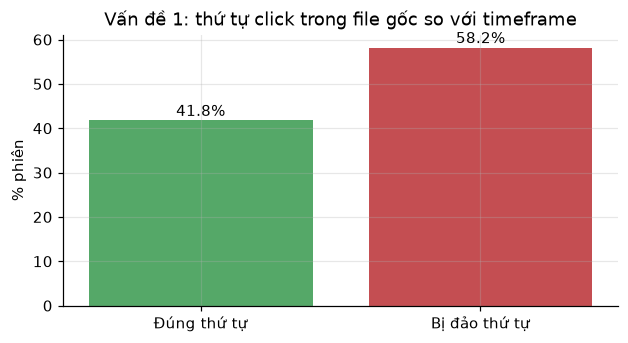

Ví dụ phiên 15 (thứ tự trong file — timeframe không tăng dần):


,session_id,item_id,timeframe,day,_row
46,15,135099,135386,2016-04-05,46
47,15,151445,318401,2016-04-05,47
48,15,29592,276284,2016-04-05,48
49,15,19726,77423,2016-04-05,49
50,15,19726,37837,2016-04-05,50
51,15,58223,104426,2016-04-05,51


In [129]:
# ===== 2.2. Tỉ lệ phiên có ít nhất một click bị đảo thứ tự + ví dụ một phiên =====
pct_unordered = sessions.unordered.mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(["Đúng thứ tự", "Bị đảo thứ tự"], [100 - pct_unordered, pct_unordered], color=["#55A868", "#C44E52"])
for i, v in enumerate([100 - pct_unordered, pct_unordered]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylabel("% phiên")
ax.set_title("Vấn đề 1: thứ tự click trong file gốc so với timeframe")
save_fig(fig, "d01_unordered_sessions.png")
plt.show()

example = sessions[sessions.unordered & (sessions.clicks.between(4, 6))].index[0]
print("Ví dụ phiên", example, "(thứ tự trong file — timeframe không tăng dần):")
display(v_file[v_file.session_id == example][["session_id", "item_id", "timeframe", "day", "_row"]])

### 2.3. Vấn đề 2 — Lưu lượng không ổn định: giai đoạn khởi động và các ngày sụt đột ngột
- **Giai đoạn khởi động:** những ngày đầu có rất ít phiên (hệ thống mới bắt đầu ghi log).
- **Ngày sụt đột ngột:** số phiên < 30% trung vị của 7 ngày xung quanh, có thể do lỗi ghi log. Các ngày này làm
  valid/test kém đại diện nếu rơi vào đó.

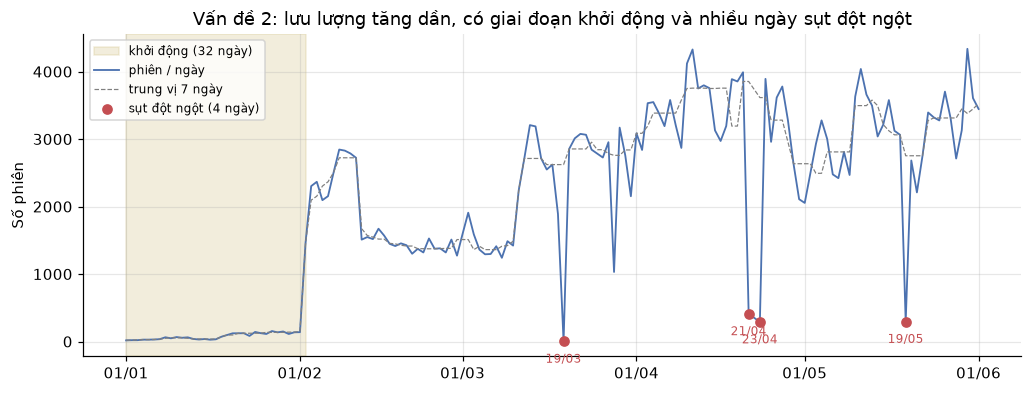

Khởi động: 2016-01-01 → 2016-02-01, 2,462 phiên (0.8% tổng)
Ngày sụt đột ngột:


,clicks,sessions,trung_vi_7_ngay,ti_le
day,,,,
2016-03-19,2,2,2622.0,0.00
2016-04-21,1406,411,3854.0,0.11
2016-04-23,1292,290,3615.0,0.08
2016-05-19,784,296,2753.0,0.11


In [130]:
# ===== 2.3. Số phiên/ngày; tô vùng khởi động; đánh dấu ngày sụt so với trung vị 7 ngày xung quanh =====
daily = views.groupby("day").agg(clicks=("item_id", "size"), sessions=("session_id", "nunique"))
median_sess = daily.sessions.median()
ramp_end = daily.index[daily.sessions >= 0.25 * median_sess][0]           # ngày đầu đạt 25% trung vị
ramp = daily[daily.index < ramp_end]
rolling = daily.sessions.rolling(7, center=True, min_periods=3).median()
drops = daily[(daily.sessions < 0.3 * rolling) & (daily.index >= ramp_end)]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(daily.index[0], ramp_end, color="#CCB974", alpha=.25, label=f"khởi động ({len(ramp)} ngày)")
ax.plot(daily.index, daily.sessions, color="#4C72B0", lw=1.2, label="phiên / ngày")
ax.plot(rolling.index, rolling, color="gray", lw=.8, ls="--", label="trung vị 7 ngày")
ax.scatter(drops.index, drops.sessions, color="#C44E52", zorder=3, label=f"sụt đột ngột ({len(drops)} ngày)")
for d, r_ in drops.iterrows():
    ax.annotate(d.strftime("%d/%m"), (d, r_.sessions), textcoords="offset points", xytext=(0, -14),
                ha="center", fontsize=8, color="#C44E52")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_ylabel("Số phiên")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Vấn đề 2: lưu lượng tăng dần, có giai đoạn khởi động và nhiều ngày sụt đột ngột")
save_fig(fig, "d02_daily_volume.png")
plt.show()
print(f"Khởi động: {ramp.index[0].date()} → {ramp.index[-1].date()}, {ramp.sessions.sum():,} phiên "
      f"({ramp.sessions.sum() / daily.sessions.sum() * 100:.1f}% tổng)")
print("Ngày sụt đột ngột:")
display(drops.assign(trung_vi_7_ngay=rolling[drops.index].round(0),
                     ti_le=(drops.sessions / rolling[drops.index]).round(2)))

### 2.4. Lưu lượng theo tháng và theo thứ trong tuần

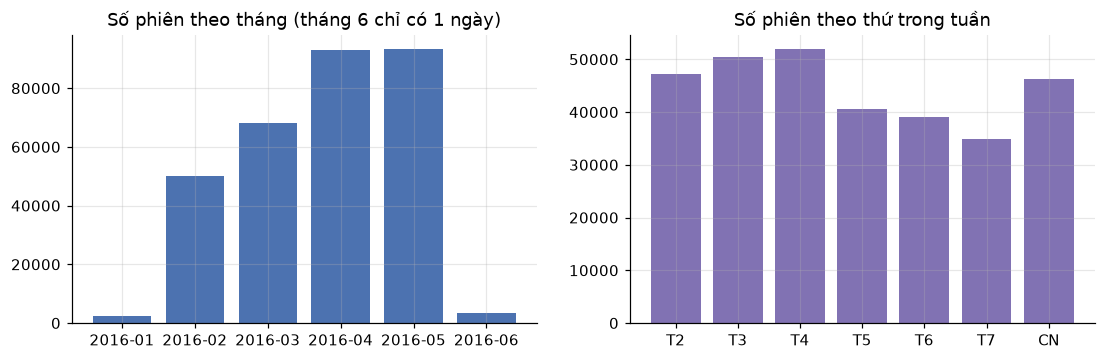

In [131]:
# ===== 2.4. Phân bố phiên theo tháng và theo thứ =====
monthly = sessions.groupby(sessions.day.dt.to_period("M")).size()
weekday = sessions.groupby(sessions.day.dt.dayofweek).size()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].bar(monthly.index.astype(str), monthly.values, color="#4C72B0")
axes[0].set_title("Số phiên theo tháng (tháng 6 chỉ có 1 ngày)")
axes[1].bar(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], weekday.values, color="#8172B3")
axes[1].set_title("Số phiên theo thứ trong tuần")
save_fig(fig, "d03_monthly_weekday.png")
plt.show()

### 2.5. sessionId có tăng theo thời gian không?
Nếu có, có thể xếp thứ tự phiên trong cùng một ngày. Nếu không, chỉ chia được theo **ngày**.

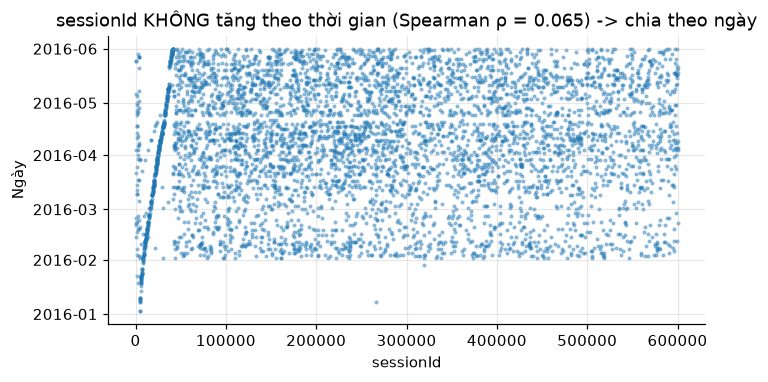

In [132]:
# ===== 2.5. Tương quan Spearman giữa sessionId và ngày của phiên =====
rho = stats.spearmanr(sessions.index, sessions.day.values.astype("int64")).statistic
sample = sessions.sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(sample.index, sample.day, s=3, alpha=.4)
ax.set_xlabel("sessionId")
ax.set_ylabel("Ngày")
ax.set_title(f"sessionId KHÔNG tăng theo thời gian (Spearman ρ = {rho:.3f}) -> chia theo ngày")
save_fig(fig, "d04_sessionid_vs_date.png")
plt.show()

### 2.6. Vấn đề 3 — Phiên rất ngắn; nhiều phiên chỉ có 1 click

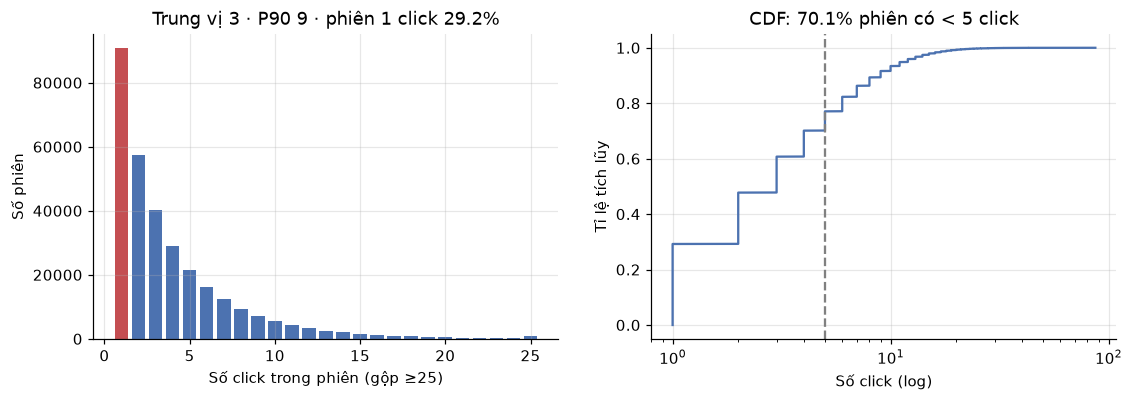

bucket,1,2–3,4–5,6–10,>10
% phiên (thô),29.2,31.5,16.3,16.3,6.6


In [133]:
# ===== 2.6. Histogram + CDF độ dài phiên; tỉ lệ theo bucket của P0 =====
L = sessions.clicks
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
vc = L.clip(upper=25).value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=["#C44E52" if k == 1 else "#4C72B0" for k in vc.index])
axes[0].set_xlabel("Số click trong phiên (gộp ≥25)")
axes[0].set_ylabel("Số phiên")
axes[0].set_title(f"Trung vị {L.median():.0f} · P90 {L.quantile(.9):.0f} · phiên 1 click {(L == 1).mean() * 100:.1f}%")
xs = np.sort(L.values)
axes[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color="#4C72B0")
axes[1].set_xscale("log")
axes[1].axvline(5, color="gray", ls="--")
axes[1].set_xlabel("Số click (log)")
axes[1].set_ylabel("Tỉ lệ tích lũy")
axes[1].set_title(f"CDF: {(L < 5).mean() * 100:.1f}% phiên có < 5 click")
save_fig(fig, "d05_session_length.png")
plt.show()
bucket_raw = (sessions.bucket.value_counts(normalize=True) * 100).reindex(["1", *LEN_LABELS]).round(1)
display(bucket_raw.rename("% phiên (thô)").to_frame().T)

### 2.7. Thời lượng phiên và khoảng cách giữa hai click
`timeframe` không bắt đầu từ 0 vì được tính từ truy vấn tìm kiếm đầu tiên của phiên. Thời lượng phiên bị chặn
khoảng 20 phút, có thể do hệ thống cắt phiên.

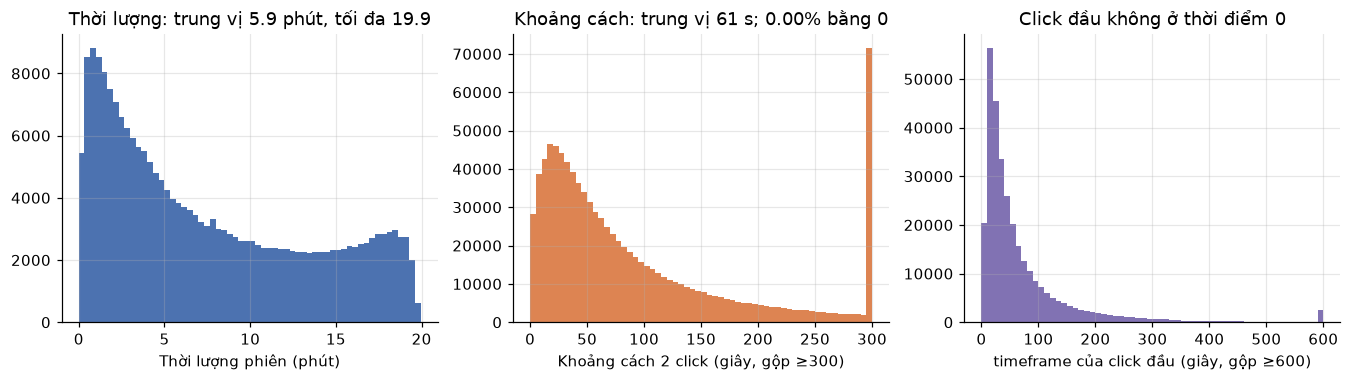

In [134]:
# ===== 2.7. Thời lượng phiên (phút) và khoảng cách giữa 2 click liên tiếp (giây), sau khi sắp theo timeframe =====
v_time = views.sort_values(["session_id", "timeframe", "_row"], kind="mergesort")
same = v_time.session_id.values[1:] == v_time.session_id.values[:-1]
gaps = np.diff(v_time.timeframe.values)[same] / 1000
multi = sessions[sessions.clicks > 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
axes[0].hist(multi.duration_min, bins=60, color="#4C72B0")
axes[0].set_xlabel("Thời lượng phiên (phút)")
axes[0].set_title(f"Thời lượng: trung vị {multi.duration_min.median():.1f} phút, tối đa {multi.duration_min.max():.1f}")
axes[1].hist(np.clip(gaps, 0, 300), bins=60, color="#DD8452")
axes[1].set_xlabel("Khoảng cách 2 click (giây, gộp ≥300)")
axes[1].set_title(f"Khoảng cách: trung vị {np.median(gaps):.0f} s; {(gaps == 0).mean() * 100:.2f}% bằng 0")
axes[2].hist(np.clip(sessions.t_min / 1000, 0, 600), bins=60, color="#8172B3")
axes[2].set_xlabel("timeframe của click đầu (giây, gộp ≥600)")
axes[2].set_title("Click đầu không ở thời điểm 0")
save_fig(fig, "d06_duration_gaps.png")
plt.show()

### 2.8. Vấn đề 4 — Độ phổ biến item lệch nặng (long-tail)

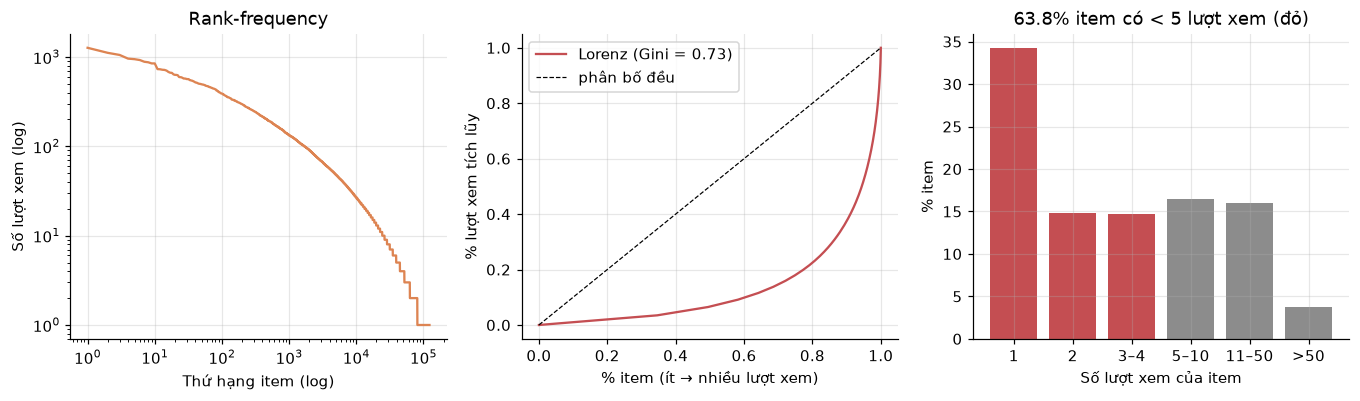

1% item phổ biến nhất chiếm 21.6% lượt xem; Gini = 0.726


In [135]:
# ===== 2.8. Rank-frequency (log-log), đường Lorenz + Gini, phân nhóm số lượt xem =====
item_cnt = views.item_id.value_counts()
g = gini(item_cnt.values)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].loglog(np.arange(1, len(item_cnt) + 1), item_cnt.values, color="#DD8452")
axes[0].set_xlabel("Thứ hạng item (log)")
axes[0].set_ylabel("Số lượt xem (log)")
axes[0].set_title("Rank-frequency")
lor = np.r_[0, np.cumsum(np.sort(item_cnt.values)) / item_cnt.sum()]
axes[1].plot(np.linspace(0, 1, len(lor)), lor, color="#C44E52", label=f"Lorenz (Gini = {g:.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8, label="phân bố đều")
axes[1].set_xlabel("% item (ít → nhiều lượt xem)")
axes[1].set_ylabel("% lượt xem tích lũy")
axes[1].legend()
bins, labels = [1, 2, 3, 5, 11, 51, 10**7], ["1", "2", "3–4", "5–10", "11–50", ">50"]
binned = pd.cut(item_cnt, bins=bins, right=False, labels=labels).value_counts().reindex(labels)
axes[2].bar(labels, binned.values / len(item_cnt) * 100, color=["#C44E52"] * 3 + ["#8C8C8C"] * 3)
axes[2].set_xlabel("Số lượt xem của item")
axes[2].set_ylabel("% item")
axes[2].set_title(f"{(item_cnt < MIN_ITEM_COUNT).mean() * 100:.1f}% item có < {MIN_ITEM_COUNT} lượt xem (đỏ)")
save_fig(fig, "d07_item_popularity.png")
plt.show()
top1 = item_cnt.head(len(item_cnt) // 100).sum() / item_cnt.sum() * 100
print(f"1% item phổ biến nhất chiếm {top1:.1f}% lượt xem; Gini = {g:.3f}")

### 2.9. Vấn đề 5 — Người dùng xem lại cùng một item
Click lặp **liên tiếp** (A → A) làm bài toán dễ hơn: đoán "item vừa xem" là trúng. Cần đo để đọc kết quả cho đúng.

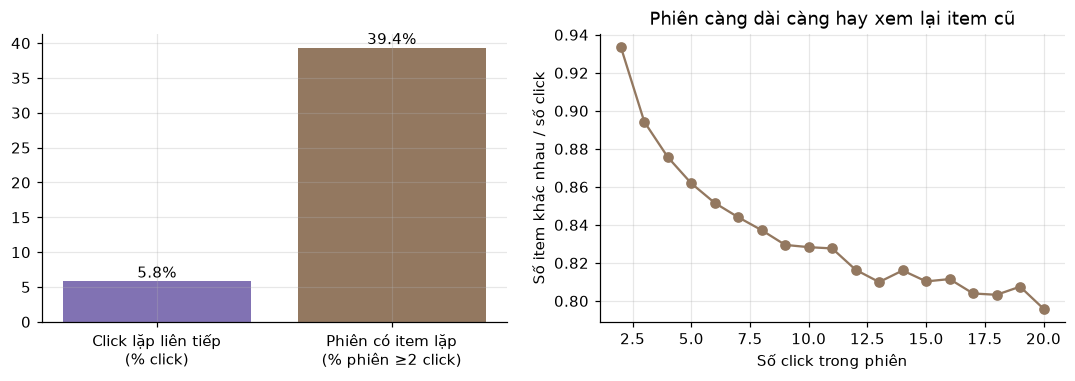

In [136]:
# ===== 2.9. Click lặp liên tiếp, phiên có item lặp, tỉ lệ item khác nhau / số click =====
rep_consec = np.r_[False, same & (v_time.item_id.values[1:] == v_time.item_id.values[:-1])]
pct_consec = rep_consec.mean() * 100
sessions["has_repeat"] = sessions.unique_items < sessions.clicks
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
vals = [pct_consec, sessions[sessions.clicks > 1].has_repeat.mean() * 100]
axes[0].bar(["Click lặp liên tiếp\n(% click)", "Phiên có item lặp\n(% phiên ≥2 click)"], vals, color=["#8172B3", "#937860"])
for i, v in enumerate(vals):
    axes[0].text(i, v + .5, f"{v:.1f}%", ha="center")
ratio = sessions[sessions.clicks > 1].groupby(sessions.clicks.clip(upper=20)).apply(
    lambda d: (d.unique_items / d.clicks).mean())
axes[1].plot(ratio.index, ratio.values, marker="o", color="#937860")
axes[1].set_xlabel("Số click trong phiên")
axes[1].set_ylabel("Số item khác nhau / số click")
axes[1].set_title("Phiên càng dài càng hay xem lại item cũ")
save_fig(fig, "d08_repeats.png")
plt.show()

### 2.10. Vấn đề 6 — Item mới liên tục xuất hiện (cold-start, trôi dạt theo thời gian)
Item xuất hiện lần đầu ở giai đoạn cuối sẽ **không có trong train** khi chia theo thời gian.

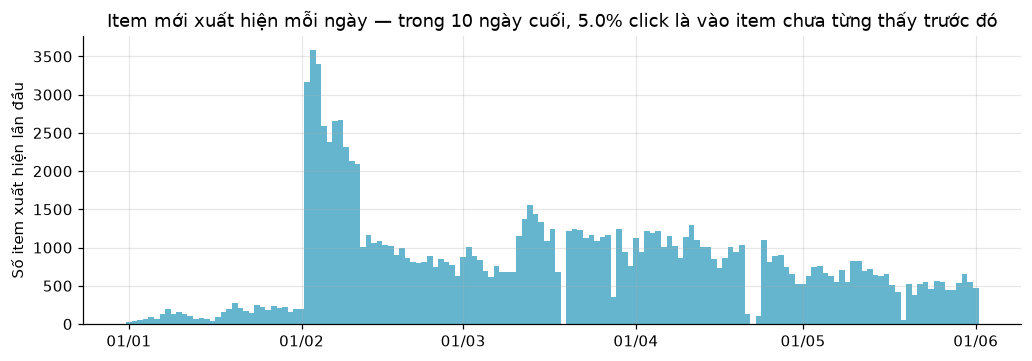

In [137]:
# ===== 2.10. Số item xuất hiện lần đầu mỗi ngày + tỉ lệ click vào item "mới" trong 10 ngày cuối =====
first_seen = views.groupby("item_id").day.min()
new_per_day = first_seen.value_counts().sort_index()
last10 = views.day.max() - pd.Timedelta(days=9)
late = views[views.day >= last10]
pct_new_clicks = late.item_id.map(first_seen).ge(last10).mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(new_per_day.index, new_per_day.values, color="#64B5CD", width=1)
ax.set_ylabel("Số item xuất hiện lần đầu")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title(f"Item mới xuất hiện mỗi ngày — trong 10 ngày cuối, {pct_new_clicks:.1f}% click là vào item chưa từng thấy trước đó")
save_fig(fig, "d09_new_items.png")
plt.show()

### 2.11. Category: kích thước rất chênh lệch
Category là thông tin phụ trợ duy nhất được phép (Mục 1.5). Đề T10 **không đưa category vào mô hình**,
nhưng phải kiểm tra độ phủ (≥ 95%).

[modal-client] 2026-10-31T10:40:25+0700 Warning: the results of a call to Function.map.aio was not consumed, so the call will never be executed. Consider a for-loop like `for x in Function.map.aio(...)` or unpacking the generator using `list(...)`


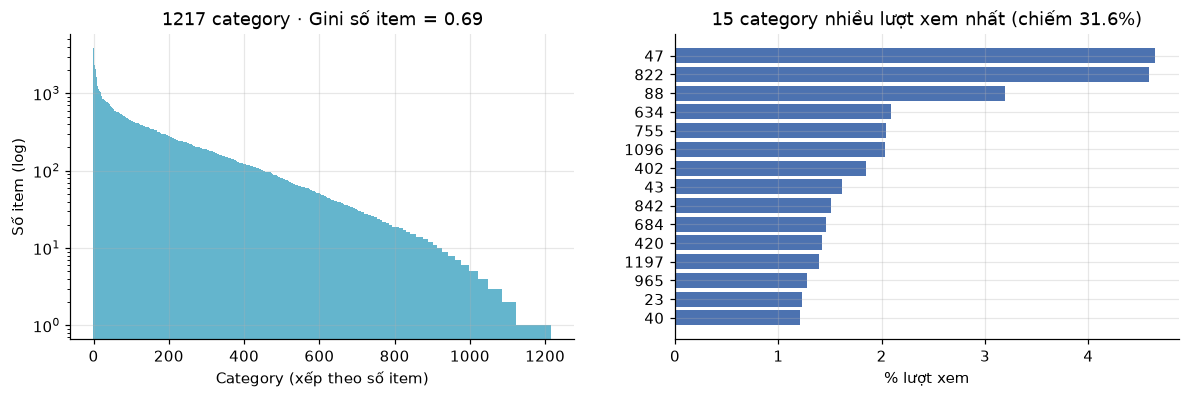

Độ phủ category: 100.00% item có lượt xem, 100.00% lượt xem | mỗi item đúng 1 category


In [138]:
# ===== 2.11. Số item mỗi category, top category theo lượt xem, độ phủ category =====
cat_items = cats_raw.groupby("categoryId").itemId.nunique().sort_values(ascending=False)
cat_clicks = views.category.value_counts()
cov_items = views.drop_duplicates("item_id").category.notna().mean() * 100
cov_clicks = views.category.notna().mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar(np.arange(len(cat_items)), cat_items.values, width=1, color="#64B5CD")
axes[0].set_yscale("log")
axes[0].set_xlabel("Category (xếp theo số item)")
axes[0].set_ylabel("Số item (log)")
axes[0].set_title(f"{len(cat_items)} category · Gini số item = {gini(cat_items.values):.2f}")
top = cat_clicks.head(15)[::-1]
axes[1].barh(top.index.astype(str), top.values / len(views) * 100, color="#4C72B0")
axes[1].set_xlabel("% lượt xem")
axes[1].set_title(f"15 category nhiều lượt xem nhất (chiếm {cat_clicks.head(15).sum() / len(views) * 100:.1f}%)")
save_fig(fig, "d10_categories.png")
plt.show()
print(f"Độ phủ category: {cov_items:.2f}% item có lượt xem, {cov_clicks:.2f}% lượt xem | mỗi item đúng 1 category")

### 2.12. Category trong một phiên: khách có ở lại trong một category không?

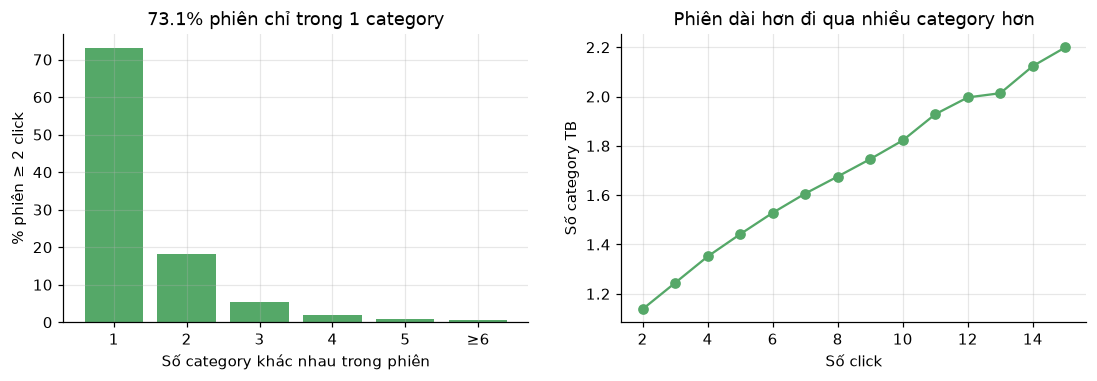

In [139]:
# ===== 2.12. Số category khác nhau trong phiên theo độ dài phiên =====
multi = sessions[sessions.clicks >= 2]
single_cat = (multi.n_cats == 1).mean() * 100
by_len = multi.groupby(multi.clicks.clip(upper=15)).n_cats.mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
vc = multi.n_cats.clip(upper=6).value_counts(normalize=True).sort_index() * 100
axes[0].bar([str(k) if k < 6 else "≥6" for k in vc.index], vc.values, color="#55A868")
axes[0].set_xlabel("Số category khác nhau trong phiên")
axes[0].set_ylabel("% phiên ≥ 2 click")
axes[0].set_title(f"{single_cat:.1f}% phiên chỉ trong 1 category")
axes[1].plot(by_len.index, by_len.values, marker="o", color="#55A868")
axes[1].set_xlabel("Số click")
axes[1].set_ylabel("Số category TB")
axes[1].set_title("Phiên dài hơn đi qua nhiều category hơn")
save_fig(fig, "d11_category_in_session.png")
plt.show()

### 2.13. Dữ liệu định danh người dùng và các dòng/phiên bất thường
PDF Mục 1.5 cấm dùng định danh người dùng → bỏ cột `userId`.

In [140]:
# ===== 2.13. % lượt xem có userId, dòng lỗi, dòng trùng, phiên nhiều ngày, timeframe trùng trong phiên =====
anomalies = pd.Series({
    "% lượt xem có userId": round((views.user_id != "").mean() * 100, 1),
    "Số người dùng có ID": views.loc[views.user_id != "", "user_id"].nunique(),
    "Dòng có giá trị lỗi": int(views[["session_id", "item_id", "timeframe", "day"]].isna().any(axis=1).sum()),
    "Dòng trùng hoàn toàn": int(views_raw.duplicated(subset=["sessionId", "userId", "itemId", "timeframe", "eventdate"]).sum()),
    "Phiên trải trên nhiều ngày": int((sessions.n_days > 1).sum()),
    "Cặp click trùng timeframe trong phiên": int(views.duplicated(["session_id", "timeframe"]).sum()),
}, name="Giá trị", dtype=object)
display(anomalies.to_frame())

,Giá trị
% lượt xem có userId,30.2
Số người dùng có ID,87934
Dòng có giá trị lỗi,0
Dòng trùng hoàn toàn,0
Phiên trải trên nhiều ngày,260
Cặp click trùng timeframe trong phiên,4


### 2.14. Tổng hợp: vấn đề → quyết định xử lý

In [141]:
# ===== 2.14. Bảng quyết định (đưa thẳng vào báo cáo) =====
decisions = pd.DataFrame([
    ["Click trong phiên không đúng thứ tự", f"{pct_unordered:.1f}% phiên", "Sắp theo timeframe (hòa → thứ tự dòng gốc)", "Bước 3.3"],
    ["Phiên 1 click", f"{(L == 1).mean() * 100:.1f}% phiên", "Loại: không tạo được cặp prefix → item kế tiếp", "Bước 3.5"],
    ["Phiên trải nhiều ngày", f"{int((sessions.n_days > 1).sum())} phiên", "Loại: không gán được vào 1 ngày khi chia theo thời gian", "Bước 3.4"],
    ["Dòng lỗi / trùng", f"{int(anomalies['Dòng có giá trị lỗi'])} lỗi, {int(anomalies['Dòng trùng hoàn toàn'])} trùng", "Loại (giữ lại kiểm tra cho lần tải khác)", "Bước 3.1–3.2"],
    ["userId (định danh người dùng)", f"{anomalies['% lượt xem có userId']}% lượt xem", "Bỏ cột (Mục 1.5 PDF)", "Bước 3.1"],
    ["sessionId không theo thời gian", f"ρ = {rho:.3f}", "Chia theo NGÀY, không theo sessionId", "Phần 5"],
    ["Giai đoạn khởi động ít dữ liệu", f"{len(ramp)} ngày, {ramp.sessions.sum() / daily.sessions.sum() * 100:.1f}% phiên",
     "Giữ (nằm trong train, rất nhỏ; không bịa dữ liệu)", "Phần 5"],
    ["Ngày sụt đột ngột", f"{len(drops)} ngày < 30% trung vị 7 ngày", "Giữ nguyên; báo cáo ngày sụt rơi vào tập nào (5.3)", "Phần 5.3"],
    ["Item hiếm", f"{(item_cnt < MIN_ITEM_COUNT).mean() * 100:.1f}% item < 5 lượt", "Lọc 5-core CHỈ trên train (không nhìn tương lai)", "Phần 5.4"],
    ["Item mới ở giai đoạn cuối", f"{pct_new_clicks:.1f}% click 10 ngày cuối", "Bỏ mẫu có target chưa thấy trong train (T10 là warm), báo cáo tỉ lệ", "Phần 6"],
    ["Click lặp liên tiếp", f"{pct_consec:.1f}% click", "Giữ (hành vi thật, giống chuẩn SR-GNN); đo tỉ lệ mẫu 'target = item vừa xem'", "Phần 6.8"],
    ["Category lệch", f"Gini {gini(cat_items.values):.2f}; phủ {cov_items:.1f}%", "Chỉ dùng kiểm tra độ phủ; item thiếu gán 'unknown'", "Phần 5.5"],
], columns=["Vấn đề", "Số liệu", "Quyết định", "Ở đâu"])
decisions.to_csv(TABLE_DIR / "data_problems_decisions.csv", index=False, encoding="utf-8-sig")
display(decisions)

,Vấn đề,Số liệu,Quyết định,Ở đâu
0,Click trong phiên không đúng thứ tự,58.2% phiên,Sắp theo timeframe (hòa → thứ tự dòng gốc),Bước 3.3
1,Phiên 1 click,29.2% phiên,Loại: không tạo được cặp prefix → item kế tiếp,Bước 3.5
2,Phiên trải nhiều ngày,260 phiên,Loại: không gán được vào 1 ngày khi chia theo ...,Bước 3.4
3,Dòng lỗi / trùng,"0 lỗi, 0 trùng",Loại (giữ lại kiểm tra cho lần tải khác),Bước 3.1–3.2
4,userId (định danh người dùng),30.2% lượt xem,Bỏ cột (Mục 1.5 PDF),Bước 3.1
5,sessionId không theo thời gian,ρ = 0.065,"Chia theo NGÀY, không theo sessionId",Phần 5
6,Giai đoạn khởi động ít dữ liệu,"32 ngày, 0.8% phiên","Giữ (nằm trong train, rất nhỏ; không bịa dữ liệu)",Phần 5
7,Ngày sụt đột ngột,4 ngày < 30% trung vị 7 ngày,Giữ nguyên; báo cáo ngày sụt rơi vào tập nào (...,Phần 5.3
8,Item hiếm,63.8% item < 5 lượt,Lọc 5-core CHỈ trên train (không nhìn tương lai),Phần 5.4
9,Item mới ở giai đoạn cuối,5.0% click 10 ngày cuối,Bỏ mẫu có target chưa thấy trong train (T10 là...,Phần 6


## Phần 3 — Làm sạch dữ liệu

Chỉ gồm các bước **không dùng thông tin của valid/test**. Lọc theo tần suất item để sang Phần 5, chỉ tính trên train.
Mỗi bước ghi số dòng, phiên, item còn lại vào `funnel`.

### 3.1. Bước 1 — Loại dòng lỗi, bỏ cột userId

In [142]:
# ===== 3.1. Bỏ dòng có ID/thời gian không hợp lệ; bỏ userId theo Mục 1.5 =====
funnel = []


def log_step(name, df):
    funnel.append({"Bước": name, "Dòng": len(df), "Phiên": df.session_id.nunique(), "Item": df.item_id.nunique()})


log_step("0. Dữ liệu gốc", views)
clean = views.dropna(subset=["session_id", "item_id", "timeframe", "day"])
clean = clean[clean.timeframe >= 0].drop(columns=["user_id"])
clean = clean.astype({"session_id": "int64", "item_id": "int64", "timeframe": "int64"})
log_step("1. Loại dòng lỗi, bỏ userId", clean)
print(funnel[-1])

{'Bước': '1. Loại dòng lỗi, bỏ userId', 'Dòng': 1235380, 'Phiên': 310324, 'Item': 122993}


### 3.2. Bước 2 — Loại dòng trùng hoàn toàn

In [143]:
# ===== 3.2. Cùng phiên, cùng item, cùng thời điểm, cùng ngày -> giữ 1 dòng =====
clean = clean.drop_duplicates(subset=["session_id", "item_id", "timeframe", "day"], keep="first")
log_step("2. Loại dòng trùng", clean)
print(funnel[-1])

{'Bước': '2. Loại dòng trùng', 'Dòng': 1235380, 'Phiên': 310324, 'Item': 122993}


### 3.3. Bước 3 — Sắp xếp click trong phiên theo thời gian

In [144]:
# ===== 3.3. Sắp theo (phiên, timeframe, thứ tự dòng gốc) và kiểm tra lại =====
clean = clean.sort_values(["session_id", "timeframe", "_row"], kind="mergesort").reset_index(drop=True)
same_s = clean.session_id.values[1:] == clean.session_id.values[:-1]
assert not (same_s & (np.diff(clean.timeframe.values) < 0)).any(), "Vẫn còn click bị đảo thứ tự"
log_step("3. Sắp theo timeframe", clean)
print("Đã sắp xong: mọi phiên có timeframe không giảm.")

Đã sắp xong: mọi phiên có timeframe không giảm.


### 3.4. Bước 4 — Loại phiên trải trên nhiều ngày

In [145]:
# ===== 3.4. Phiên có click ở 2 ngày khác nhau không gán được vào train/valid/test theo ngày =====
n_days = clean.groupby("session_id").day.nunique()
clean = clean[clean.session_id.isin(n_days[n_days == 1].index)]
log_step("4. Loại phiên nhiều ngày", clean)
print(funnel[-1])

{'Bước': '4. Loại phiên nhiều ngày', 'Dòng': 1233287, 'Phiên': 310064, 'Item': 122911}


### 3.5. Bước 5 — Loại phiên chỉ có 1 click

In [146]:
# ===== 3.5. Phiên < 2 click không tạo được mẫu (prefix, item kế tiếp) =====
sess_len = clean.groupby("session_id").size()
clean = clean[clean.session_id.isin(sess_len[sess_len >= MIN_SESSION_LEN].index)].reset_index(drop=True)
log_step("5. Loại phiên < 2 click", clean)
print(funnel[-1])

{'Bước': '5. Loại phiên < 2 click', 'Dòng': 1142593, 'Phiên': 219370, 'Item': 121386}


### 3.6. Biểu đồ phễu làm sạch

,Dòng,Phiên,Item
Bước,,,
0. Dữ liệu gốc,1235380,310324,122993
"1. Loại dòng lỗi, bỏ userId",1235380,310324,122993
2. Loại dòng trùng,1235380,310324,122993
3. Sắp theo timeframe,1235380,310324,122993
4. Loại phiên nhiều ngày,1233287,310064,122911
5. Loại phiên < 2 click,1142593,219370,121386


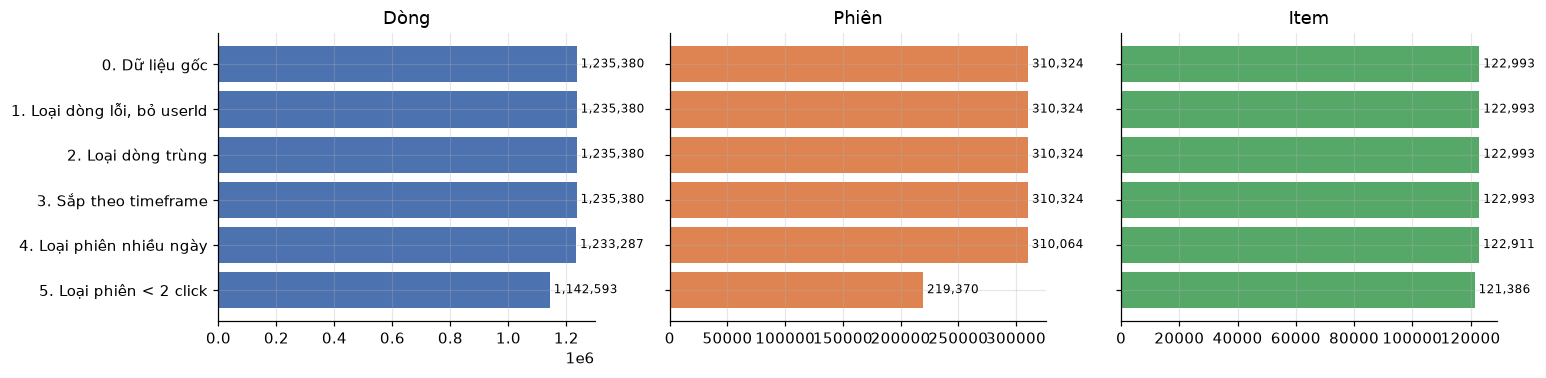

In [147]:
# ===== 3.6. Số dòng / phiên / item còn lại sau từng bước =====
funnel_df = pd.DataFrame(funnel).set_index("Bước")
funnel_df.to_csv(TABLE_DIR / "cleaning_funnel.csv", encoding="utf-8-sig")
display(funnel_df)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, col, color in zip(axes, ["Dòng", "Phiên", "Item"], ["#4C72B0", "#DD8452", "#55A868"]):
    ax.barh(funnel_df.index[::-1], funnel_df[col][::-1], color=color)
    ax.set_title(col)
    for y, v in enumerate(funnel_df[col][::-1]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8)
axes[1].set_yticklabels([])
axes[2].set_yticklabels([])
save_fig(fig, "d12_cleaning_funnel.png")
plt.show()

### 3.7. Trước / sau làm sạch: độ dài phiên

,Số phiên,Trung bình,Trung vị,P90,% phiên < 5 click
Thô,310324.0,3.98,3.0,9.0,70.1
Sau làm sạch,219370.0,5.21,4.0,10.0,57.8


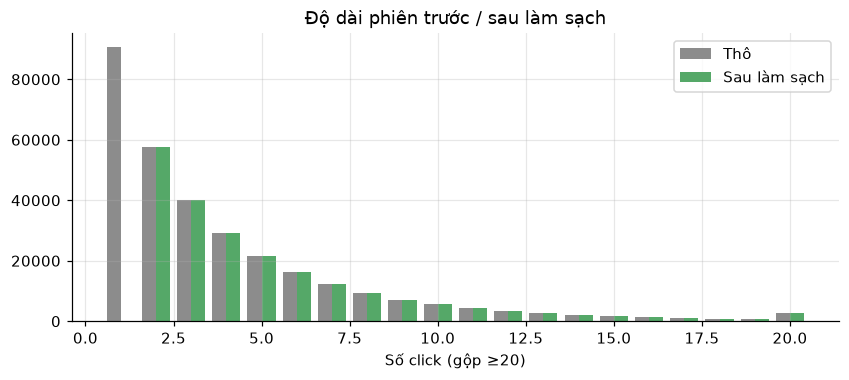

In [148]:
# ===== 3.7. So sánh thống kê độ dài phiên trước và sau làm sạch (câu hỏi 1–2 của D01) =====
clean_len = clean.groupby("session_id").size()
length_table = pd.DataFrame({"Thô": describe_lengths(sessions.clicks), "Sau làm sạch": describe_lengths(clean_len)}).T
display(length_table)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist([sessions.clicks.clip(upper=20), clean_len.clip(upper=20)], bins=np.arange(1, 22) - .5,
        label=["Thô", "Sau làm sạch"], color=["#8C8C8C", "#55A868"])
ax.set_xlabel("Số click (gộp ≥20)")
ax.legend()
ax.set_title("Độ dài phiên trước / sau làm sạch")
save_fig(fig, "d13_length_before_after.png")
plt.show()

## Phần 4 — Đối chiếu với tiền xử lý chuẩn của SR-GNN (D01, bước 3)

SR-GNN [3] (và NARM [2]) công bố Diginetica sau xử lý gồm **982.961 click, 43.097 item, 719.470 mẫu train,
60.858 mẫu test**. Tái hiện cách xử lý đó cho ra cùng số liệu, chứng tỏ dữ liệu tải về đúng bản chuẩn.

Cách SR-GNN **lọc 5-core trên toàn bộ dữ liệu, kể cả tuần test**, tức là dùng thông tin tương lai để quyết định item nào
được giữ (rò rỉ, xem T04). Bài này vì vậy lọc 5-core **chỉ trên train** và chia 80/10/10 theo thời gian như Mục 1.3.

### 4.1. Tái hiện tiền xử lý SR-GNN

In [149]:
# ===== 4.1. SR-GNN preprocess.py: bỏ phiên 1 click -> bỏ item < 5 lần (toàn bộ dữ liệu) -> test = 7 ngày cuối =====
def srgnn_preprocess(df):
    df = df.sort_values(["session_id", "timeframe", "_row"], kind="mergesort")
    sess_date = df.groupby("session_id").day.max()                          # SR-GNN dùng ngày click cuối
    n = df.groupby("session_id").size()
    df = df[df.session_id.isin(n[n > 1].index)]
    ic = df.item_id.value_counts()
    df = df[df.item_id.isin(ic[ic >= 5].index)]                             # <- dùng cả dữ liệu tương lai
    n = df.groupby("session_id").size()
    df = df[df.session_id.isin(n[n >= 2].index)]
    sd = sess_date.loc[df.session_id.unique()]
    cut = sd.max() - pd.Timedelta(days=7)
    tr, te = df[df.session_id.isin(sd[sd < cut].index)], df[df.session_id.isin(sd[sd > cut].index)]
    te = te[te.item_id.isin(set(tr.item_id))]
    n = te.groupby("session_id").size()
    te = te[te.session_id.isin(n[n >= 2].index)]
    both = pd.concat([tr, te])
    return {"Click": len(both), "Item": both.item_id.nunique(), "Phiên train": tr.session_id.nunique(),
            "Phiên test": te.session_id.nunique(), "Mẫu train (prefix)": int((tr.groupby("session_id").size() - 1).sum()),
            "Mẫu test (prefix)": int((te.groupby("session_id").size() - 1).sum()),
            "Độ dài TB": round(both.groupby("session_id").size().mean(), 2)}


srgnn = srgnn_preprocess(views.dropna(subset=["session_id", "item_id", "timeframe", "day"]).astype({"session_id": "int64", "item_id": "int64", "timeframe": "int64"}))
published = {"Click": 982961, "Item": 43097, "Mẫu train (prefix)": 719470, "Mẫu test (prefix)": 60858, "Độ dài TB": 5.12}
compare = pd.DataFrame({"Tái hiện SR-GNN": srgnn, "Công bố [3]": published})
compare["Khớp"] = [(str(a == b) if pd.notna(b) else "—") for a, b in zip(compare.iloc[:, 0], compare.iloc[:, 1])]
compare.to_csv(TABLE_DIR / "srgnn_comparison.csv", encoding="utf-8-sig")
display(compare)

,Tái hiện SR-GNN,Công bố [3],Khớp
Click,982961.00,982961.00,True
Item,43097.00,43097.00,True
Phiên train,186670.00,NaN,—
Phiên test,15963.00,NaN,—
Mẫu train (prefix),719470.00,719470.00,True
Mẫu test (prefix),60858.00,60858.00,True
Độ dài TB,4.85,5.12,False


**Nhận xét:**
- Click, item, số mẫu train/test **khớp tuyệt đối** với SR-GNN, nên dữ liệu là bản chuẩn.
- Độ dài trung bình 5,12 trong bài báo khác vài phần trăm, có thể do cách tính (trên phiên gốc hay sau lọc).
- PDF ghi 204.771 phiên; tổng phiên train + test ở trên chênh nhẹ, cũng có thể do khác cách đếm.
  Theo yêu cầu của D01, chênh lệch này được ghi lại và giải thích.

## Phần 5 — Chia train / valid / test theo thời gian

**Thứ tự chia: theo THỜI GIAN** (đề T10 yêu cầu *valid tách theo thời gian*; Mục 1.3 bắt buộc ghi rõ).
Đơn vị chia là **nguyên phiên** và **nguyên ngày**, vì `sessionId` không cho biết thứ tự trong ngày (mục 2.5).
Chọn 2 ngày cắt sao cho số phiên gần 80% / 10% / 10% nhất.

### 5.1. Hàm chọn ngày cắt

In [150]:
# ===== 5.1. Ngày cắt: tích lũy số phiên gần 80% và 90% nhất =====
def day_boundaries(session_days, ratios=SPLIT_RATIO):
    counts = session_days.value_counts().sort_index()
    cum = counts.cumsum().to_numpy() / counts.sum()
    i = min(range(len(counts) - 2), key=lambda j: (abs(cum[j] - ratios[0]), j))
    j = min(range(i + 1, len(counts) - 1), key=lambda k: (abs(cum[k] - ratios[0] - ratios[1]), k))
    return counts.index[i], counts.index[j]

### 5.2. Chia phiên vào 3 tập

In [151]:
# ===== 5.2. Gán mỗi phiên vào train / valid / test theo ngày của phiên =====
session_day = clean.groupby("session_id").day.first()
cut1, cut2 = day_boundaries(session_day)
split_of = pd.Series(np.where(session_day <= cut1, "train", np.where(session_day <= cut2, "valid", "test")),
                     index=session_day.index)
clean["split"] = clean.session_id.map(split_of)
parts = {s: clean[clean.split == s] for s in ("train", "valid", "test")}
split_summary = pd.DataFrame({s: {"Từ ngày": p.day.min().date(), "Đến ngày": p.day.max().date(),
                                   "Số ngày": p.day.nunique(), "Phiên": p.session_id.nunique(),
                                   "% phiên": round(p.session_id.nunique() / len(session_day) * 100, 2), "Click": len(p)}
                              for s, p in parts.items()}).T
print("Ngày cắt:", cut1.date(), "|", cut2.date())
display(split_summary)

Ngày cắt: 2016-05-12 | 2016-05-23


,Từ ngày,Đến ngày,Số ngày,Phiên,% phiên,Click
train,2016-01-01,2016-05-12,131,175802,80.14,920067
valid,2016-05-13,2016-05-23,11,21766,9.92,110465
test,2016-05-24,2016-06-01,9,21802,9.94,112061


### 5.3. Biểu đồ: các ngày thuộc tập nào

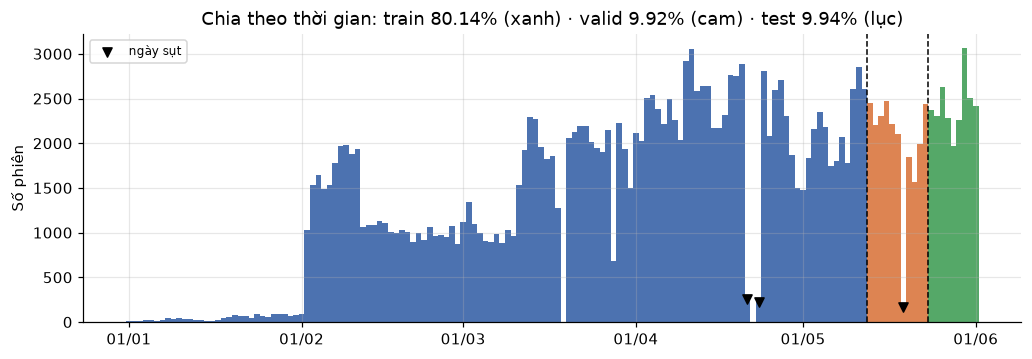

Ngày sụt đột ngột rơi vào tập: {'2016-03-19': 'train', '2016-04-21': 'train', '2016-04-23': 'train', '2016-05-19': 'valid'}


In [152]:
# ===== 5.3. Số phiên mỗi ngày tô màu theo tập =====
per_day = session_day.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(per_day.index, per_day.values, width=1,
       color=[SPLIT_COLORS["train" if d <= cut1 else "valid" if d <= cut2 else "test"] for d in per_day.index])
for c in (cut1, cut2):
    ax.axvline(c + pd.Timedelta(hours=12), color="black", ls="--", lw=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_ylabel("Số phiên")
ax.scatter(drops.index, per_day.reindex(drops.index), color="black", marker="v", zorder=3, label="ngày sụt")
ax.legend(fontsize=8)
r = split_summary["% phiên"]
ax.set_title(f"Chia theo thời gian: train {r['train']}% (xanh) · valid {r['valid']}% (cam) · test {r['test']}% (lục)")
save_fig(fig, "d14_split_by_day.png")
plt.show()
drop_split = pd.Series(["train" if d <= cut1 else "valid" if d <= cut2 else "test" for d in drops.index],
                       index=[str(d.date()) for d in drops.index], name="tập")
print("Ngày sụt đột ngột rơi vào tập:", drop_split.to_dict())

### 5.4. Lọc 5-core chỉ trên train
Lặp lại: bỏ item < 5 tương tác và phiên < 2 click cho tới khi không đổi. Từ điển item được **đóng băng** từ đây;
valid/test không ảnh hưởng tới việc chọn item.

In [153]:
# ===== 5.4. Lọc lặp trên train; ghi lại số dòng sau mỗi vòng =====
train = parts["train"]
core_log = [{"Vòng": 0, "Dòng": len(train), "Phiên": train.session_id.nunique(), "Item": train.item_id.nunique()}]
while True:
    before = len(train)
    ic = train.item_id.value_counts()
    train = train[train.item_id.isin(ic[ic >= MIN_ITEM_COUNT].index)]
    sl = train.groupby("session_id").size()
    train = train[train.session_id.isin(sl[sl >= MIN_SESSION_LEN].index)]
    core_log.append({"Vòng": len(core_log), "Dòng": len(train), "Phiên": train.session_id.nunique(),
                     "Item": train.item_id.nunique()})
    if len(train) == before:
        break
parts["train"] = train
core_df = pd.DataFrame(core_log).set_index("Vòng")
display(core_df)

,Dòng,Phiên,Item
Vòng,,,
0,920067,175802,111173
1,778636,161869,37187
2,774825,161213,36325
3,774487,161151,36253
4,774446,161142,36245
5,774441,161141,36244
6,774441,161141,36244


### 5.5. Từ điển item, số tương tác train, category (thiếu thì `unknown`)
`train_count` = số tương tác của item trong train **sau 5-core, trước khi tạo prefix**. Đây chính là `count` dùng để
chia nhóm Cold / Near-cold / Long-tail / Warm (Mục 1.3).

In [154]:
# ===== 5.5. Đóng băng từ điển; tính độ phủ category trên từ điển =====
train_count = train.item_id.value_counts().to_dict()
vocab = set(train_count)
item_category = {i: cat_map.get(i, "unknown") or "unknown" for i in vocab}
cat_coverage = np.mean([c != "unknown" for c in item_category.values()])
print(f"Từ điển: {len(vocab):,} item | độ phủ category: {cat_coverage * 100:.2f}% (yêu cầu ≥ 95%)")
assert cat_coverage >= .95, "Độ phủ category < 95%"

Từ điển: 36,244 item | độ phủ category: 100.00% (yêu cầu ≥ 95%)


### 5.6. Nhóm item theo số tương tác trong train

In [155]:
# ===== 5.6. Định nghĩa nhóm (Mục 1.3): Cold 0 | Near-cold 1–2 | Long-tail 1–10 (gồm near-cold) | Warm >10 =====
def item_group(count):
    if count == 0:
        return "Cold"
    if count <= THETA_NEAR:
        return "Near-cold"           # cũng thuộc Long-tail
    if count <= THETA_WARM:
        return "Long-tail (3–10)"
    return "Warm"


vocab_groups = pd.Series({i: item_group(c) for i, c in train_count.items()}).value_counts()
print("Near-cold = 0 trong từ điển vì 5-core bắt buộc mỗi item có ≥ 5 tương tác train.")
display(vocab_groups.rename("Số item trong từ điển").to_frame())

Near-cold = 0 trong từ điển vì 5-core bắt buộc mỗi item có ≥ 5 tương tác train.


,Số item trong từ điển
Warm,18834
Long-tail (3–10),17410


## Phần 6 — Tạo mẫu cho mô hình: (prefix → item kế tiếp)

Mỗi vị trí t ≥ 2 của phiên tạo một tình huống dự đoán: **prefix = các item trước t**, **target = item thứ t**.
- **Target không có trong từ điển** (item cold, chưa thấy trong train): bỏ, vì T10 là đề warm. Ghi lại tỉ lệ.
- **Item không có trong từ điển ở prefix**: bỏ khỏi prefix (chỉ giữ ngữ cảnh mô hình biết). Prefix rỗng thì bỏ mẫu.
- Prefix dài hơn 50: giữ 50 item gần nhất.
- Train cũng dùng mọi prefix (prefix augmentation, chuẩn SBR [3]).

### 6.1. Hàm sinh mẫu + metadata từng vị trí

In [156]:
# ===== 6.1. Duyệt từng phiên đã sắp; trả về bảng mọi vị trí (giữ/bỏ + lý do) =====
def build_positions(part, split):
    rows = []
    for sid, items in part.groupby("session_id", sort=False).item_id:
        items = items.tolist()
        known, had_oov = [], False
        for pos, target in enumerate(items):
            if pos > 0:
                if target not in vocab:
                    status = "bỏ: item mới (cold)"
                elif not known:
                    status = "bỏ: prefix rỗng"
                else:
                    status = "giữ"
                prefix = known[-MAX_LEN:]
                rows.append((split, sid, pos, len(items), target, train_count.get(target, 0), status,
                             " ".join(map(str, prefix)), len(prefix), len(known) > MAX_LEN, had_oov,
                             bool(prefix) and prefix[-1] == target))
            if target in vocab:
                known.append(target)
            else:
                had_oov = True
    return pd.DataFrame(rows, columns=["split", "session_id", "position", "session_len", "target", "train_count",
                                       "status", "prefix", "prefix_len", "truncated", "had_oov", "repeat_last"])

### 6.2. Sinh mẫu cho 3 tập

In [157]:
# ===== 6.2. Chạy cho train/valid/test; gán nhóm item và bucket độ dài =====
positions = pd.concat([build_positions(parts[s], s) for s in ("train", "valid", "test")], ignore_index=True)
positions["group"] = positions.train_count.map(item_group)
positions["len_bucket"] = positions.session_len.map(length_bucket)
samples = positions[positions.status == "giữ"].reset_index(drop=True)
print(f"{len(positions):,} vị trí dự đoán → giữ {len(samples):,} mẫu")
display(samples.head())

792,258 vị trí dự đoán → giữ 745,529 mẫu


,split,session_id,position,session_len,target,train_count,status,prefix,prefix_len,truncated,had_oov,repeat_last,group,len_bucket
0,train,1,1,9,33043,162,giữ,9654,1,False,False,False,Warm,6–10
1,train,1,2,9,32118,53,giữ,9654 33043,2,False,False,False,Warm,6–10
2,train,1,3,9,12352,275,giữ,9654 33043 32118,3,False,False,False,Warm,6–10
3,train,1,4,9,35077,68,giữ,9654 33043 32118 12352,4,False,False,False,Warm,6–10
4,train,1,5,9,36118,108,giữ,9654 33043 32118 12352 35077,5,False,False,False,Warm,6–10


### 6.3. Bảng số mẫu giữ / bỏ theo tập

In [158]:
# ===== 6.3. Mỗi tập: số vị trí, số mẫu giữ, số bị bỏ theo lý do =====
status_table = positions.pivot_table(index="split", columns="status", values="position", aggfunc="size", fill_value=0)
status_table = status_table.reindex(["train", "valid", "test"])
status_table["Tổng vị trí"] = status_table.sum(axis=1)
status_table["% giữ"] = (status_table["giữ"] / status_table["Tổng vị trí"] * 100).round(2)
status_table.to_csv(TABLE_DIR / "samples_status.csv", encoding="utf-8-sig")
display(status_table)

status,bỏ: item mới (cold),bỏ: prefix rỗng,giữ,Tổng vị trí,% giữ
split,,,,,
train,0,0,613300,613300,100.00
valid,20897,1878,65924,88699,74.32
test,21754,2200,66305,90259,73.46


### 6.4. Biểu đồ: thành phần mẫu theo nhóm item
Train chỉ có item thuộc từ điển, nên không có Cold. Valid/test có nhiều vị trí là **item mới**: đây chính là bài toán
cold-start mà bộ đề P0 nghiên cứu riêng.

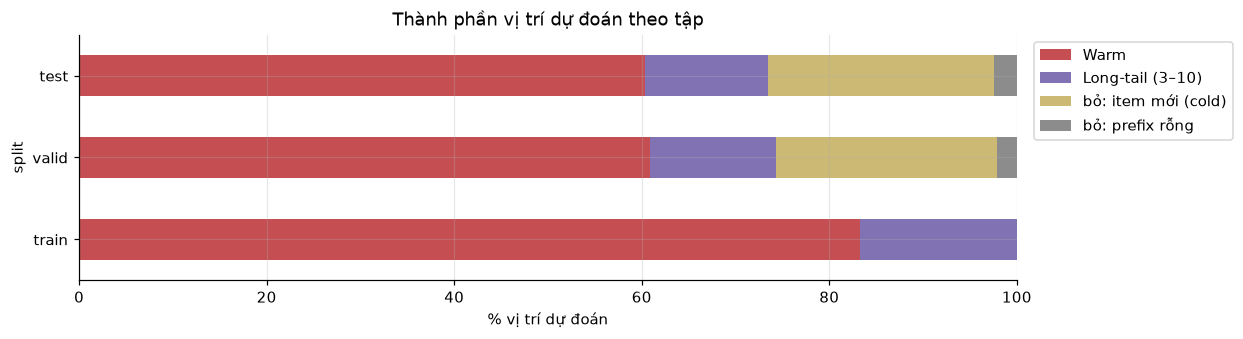

loại,Warm,Long-tail (3–10),bỏ: item mới (cold),bỏ: prefix rỗng
split,,,,
train,83.31,16.69,0.00,0.00
valid,60.88,13.44,23.56,2.12
test,60.34,13.12,24.10,2.44


In [159]:
# ===== 6.4. % vị trí theo nhóm (Warm / Long-tail / Near-cold) và bị bỏ (cold / prefix rỗng) =====
pos_cat = np.where(positions.status == "giữ", positions.group, positions.status)
comp = pd.crosstab(positions.split, pd.Series(pos_cat, name="loại"), normalize="index").reindex(["train", "valid", "test"]) * 100
order = [c for c in ["Warm", "Long-tail (3–10)", "Near-cold", "bỏ: item mới (cold)", "bỏ: prefix rỗng"] if c in comp]
ax = comp[order].plot.barh(stacked=True, figsize=(11, 2.9),
                           color=["#C44E52", "#8172B3", "#CCB974", "#8C8C8C", "#DDDDDD"][:len(order)])
ax.set_xlabel("% vị trí dự đoán")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Thành phần vị trí dự đoán theo tập")
save_fig(ax.figure, "d15_sample_composition.png")
plt.show()
display(comp[order].round(2))

### 6.5. Phân bố mẫu theo bucket độ dài phiên (2–3, 4–5, 6–10, > 10)

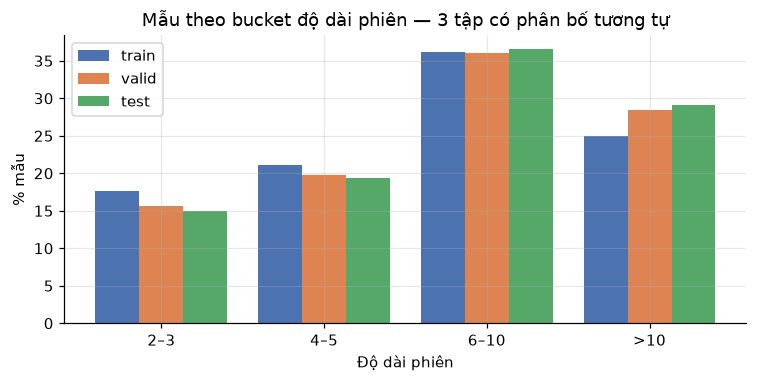

len_bucket,2–3,4–5,6–10,>10
split,,,,
train,17.69,21.08,36.19,25.04
valid,15.69,19.74,36.08,28.49
test,15.01,19.36,36.58,29.05


In [160]:
# ===== 6.5. Bucket độ dài phiên của P0 cho từng tập (dùng để tách kết quả sau khi train) =====
bk = pd.crosstab(samples.split, samples.len_bucket, normalize="index").reindex(["train", "valid", "test"])[LEN_LABELS] * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(LEN_LABELS))
for i, s in enumerate(["train", "valid", "test"]):
    ax.bar(x + (i - 1) * .27, bk.loc[s], .27, color=SPLIT_COLORS[s], label=s)
ax.set_xticks(x)
ax.set_xticklabels(LEN_LABELS)
ax.set_xlabel("Độ dài phiên")
ax.set_ylabel("% mẫu")
ax.legend()
ax.set_title("Mẫu theo bucket độ dài phiên — 3 tập có phân bố tương tự")
save_fig(fig, "d16_length_buckets.png")
plt.show()
display(bk.round(2))

### 6.6. Độ dài prefix và số prefix bị cắt ở 50

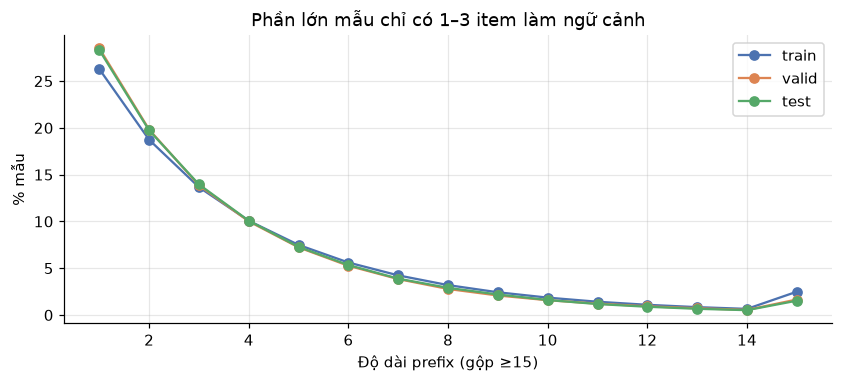

,Prefix TB,Tỉ lệ bị cắt ở 50,Tỉ lệ có item lạ bị bỏ
split,,,
train,4.0851,0.0001,0.0000
valid,3.7278,0.0000,0.2465
test,3.7168,0.0000,0.2732


In [161]:
# ===== 6.6. Phân bố độ dài prefix; tỉ lệ bị cắt (truncated) và có item lạ bị bỏ (had_oov) =====
fig, ax = plt.subplots(figsize=(9, 3.4))
for s in ("train", "valid", "test"):
    h = samples[samples.split == s].prefix_len.clip(upper=15).value_counts(normalize=True).sort_index() * 100
    ax.plot(h.index, h.values, marker="o", color=SPLIT_COLORS[s], label=s)
ax.set_xlabel("Độ dài prefix (gộp ≥15)")
ax.set_ylabel("% mẫu")
ax.legend()
ax.set_title("Phần lớn mẫu chỉ có 1–3 item làm ngữ cảnh")
save_fig(fig, "d17_prefix_length.png")
plt.show()
display(samples.groupby("split")[["prefix_len", "truncated", "had_oov"]].mean()
        .rename(columns={"prefix_len": "Prefix TB", "truncated": "Tỉ lệ bị cắt ở 50", "had_oov": "Tỉ lệ có item lạ bị bỏ"})
        .reindex(["train", "valid", "test"]).round(4))

### 6.7. Độ phổ biến có trôi theo thời gian không?
So sánh số tương tác của item trong train với số lần item đó là target trong test. Tương quan càng thấp thì
"gợi ý item phổ biến trong quá khứ" càng kém.

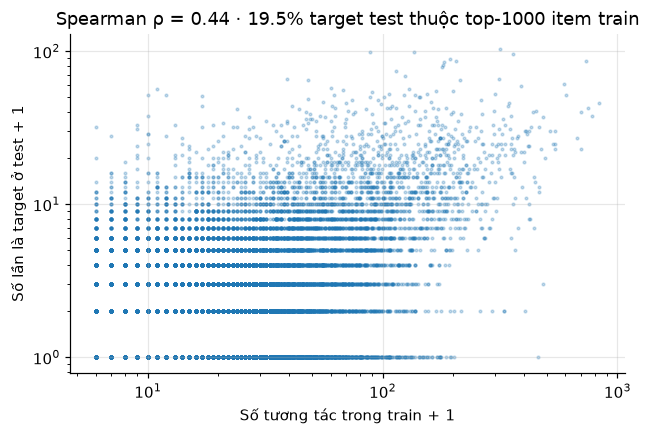

In [162]:
# ===== 6.7. Scatter train_count vs số lần làm target ở test; Spearman; độ phủ top-K item train =====
test_freq = samples[samples.split == "test"].target.value_counts()
both = pd.DataFrame({"train": pd.Series(train_count), "test": test_freq}).fillna(0)
rho_pop = stats.spearmanr(both.train, both.test).statistic
top1000 = set(pd.Series(train_count).nlargest(1000).index)
share_top = samples[samples.split == "test"].target.isin(top1000).mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(both.train + 1, both.test + 1, s=3, alpha=.25)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Số tương tác trong train + 1")
ax.set_ylabel("Số lần là target ở test + 1")
ax.set_title(f"Spearman ρ = {rho_pop:.2f} · {share_top:.1f}% target test thuộc top-1000 item train")
save_fig(fig, "d18_popularity_drift.png")
plt.show()

### 6.8. Mẫu "target = item vừa xem" (do click lặp liên tiếp)
Những mẫu này rất dễ đoán. Cần biết tỉ lệ để hiểu vì sao mô hình đạt HR cao ở các mẫu đó.

In [163]:
# ===== 6.8. Tỉ lệ mẫu có target trùng item cuối của prefix =====
rep = samples.groupby("split").repeat_last.mean().reindex(["train", "valid", "test"]) * 100
display(rep.round(2).rename("% mẫu target = item cuối prefix").to_frame())

,% mẫu target = item cuối prefix
split,
train,9.43
valid,9.95
test,9.70


### 6.9. Ghi file atomic cho RecBole + metadata

In [164]:
# ===== 6.9. Ghi diginetica.{train,valid,test}.inter (tab) + metadata từng mẫu + số tương tác train + category =====
ds_dir = PREPARED_DIR / DATASET
ds_dir.mkdir(parents=True, exist_ok=True)
file_hash = {}
for s in ("train", "valid", "test"):
    path = ds_dir / f"{DATASET}.{s}.inter"
    part = samples[samples.split == s]
    with path.open("w", encoding="utf-8", newline="") as f:
        w = csv.writer(f, delimiter="\t", lineterminator="\n")
        w.writerow(["session_id:token", "item_id_list:token_seq", "item_id:token"])
        w.writerows(zip(part.session_id, part.prefix, part.target))
    file_hash[s] = sha256_file(path)
    print(f"{path.name}: {len(part):,} mẫu")
meta_cols = ["split", "session_id", "position", "session_len", "len_bucket", "target", "train_count", "group",
             "prefix_len", "truncated", "had_oov", "repeat_last"]
samples[meta_cols].to_csv(ds_dir / "samples_metadata.csv.gz", index=False)
write_json(ds_dir / "train_item_counts.json", {str(k): int(v) for k, v in train_count.items()})
write_json(ds_dir / "item_categories.json", {str(k): v for k, v in item_category.items()})

diginetica.train.inter: 613,300 mẫu
diginetica.valid.inter: 65,924 mẫu
diginetica.test.inter: 66,305 mẫu


## Phần 7 — Kiểm tra rò rỉ dữ liệu và tính hợp lệ

Mỗi dòng là một bất biến phải đúng. Sai thì dữ liệu chưa được dùng để train.

In [165]:
# ===== 7.1. Các kiểm tra tự động =====
sess_sets = {s: set(parts[s].session_id) for s in parts}
train_seq = set(parts["train"].groupby("session_id").item_id.apply(tuple))
test_seq = parts["test"].groupby("session_id").item_id.apply(tuple)
dup_test = test_seq.isin(train_seq).mean() * 100
re_read = pd.read_csv(ds_dir / f"{DATASET}.test.inter", sep="\t", dtype=str)
same_final = clean.session_id.values[1:] == clean.session_id.values[:-1]          # tính lại trên dữ liệu cuối cùng
checks = {
    "Không phiên nào thuộc 2 tập": not (sess_sets["train"] & sess_sets["valid"] or sess_sets["train"] & sess_sets["test"]
                                        or sess_sets["valid"] & sess_sets["test"]),
    "Ngày: train < valid < test": parts["train"].day.max() < parts["valid"].day.min() <= parts["valid"].day.max() < parts["test"].day.min(),
    "Từ điển chỉ lấy từ train": vocab == set(parts["train"].item_id),
    "Mọi item train có >= 5 tương tác": min(train_count.values()) >= MIN_ITEM_COUNT,
    "Mọi target valid/test thuộc từ điển": samples.target.isin(vocab).all(),
    "Mọi item trong prefix thuộc từ điển": all(int(t) in vocab for p in samples.prefix.sample(20000, random_state=0) for t in p.split()),
    "Không prefix rỗng": (samples.prefix_len > 0).all(),
    "Click trong phiên đã sắp theo thời gian": not (same_final & (np.diff(clean.timeframe.values) < 0)).any(),
    "Độ phủ category >= 95%": cat_coverage >= .95,
    "Không dùng userId": "user_id" not in clean.columns,
    "File test đọc lại đúng số mẫu": len(re_read) == int((samples.split == "test").sum()),
}
check_df = pd.Series(checks, name="Đạt").to_frame()
display(check_df)
print(f"Tham khảo: {dup_test:.2f}% phiên test có chuỗi item y hệt một phiên train (hành vi lặp lại tự nhiên, không phải rò rỉ split).")
assert all(checks.values()), "Có kiểm tra không đạt"

,Đạt
Không phiên nào thuộc 2 tập,True
Ngày: train < valid < test,True
Từ điển chỉ lấy từ train,True
Mọi item train có >= 5 tương tác,True
Mọi target valid/test thuộc từ điển,True
Mọi item trong prefix thuộc từ điển,True
Không prefix rỗng,True
Click trong phiên đã sắp theo thời gian,True
Độ phủ category >= 95%,True
Không dùng userId,True


Tham khảo: 3.52% phiên test có chuỗi item y hệt một phiên train (hành vi lặp lại tự nhiên, không phải rò rỉ split).


## Phần 8 — Tóm tắt và lưu báo cáo dữ liệu

### 8.1. Trả lời các câu hỏi dữ liệu (D01) cho bộ Diginetica

In [166]:
# ===== 8.1. Bảng tóm tắt dùng cho báo cáo =====
final_len = pd.concat([parts[s].groupby("session_id").size() for s in parts])
summary = pd.Series({
    "Trung vị / P90 độ dài phiên — thô": f"{sessions.clicks.median():.0f} / {sessions.clicks.quantile(.9):.0f}",
    "Trung vị / P90 độ dài phiên — sau làm sạch": f"{clean_len.median():.0f} / {clean_len.quantile(.9):.0f}",
    "Trung vị / P90 độ dài phiên — sau 5-core (dữ liệu cuối)": f"{final_len.median():.0f} / {final_len.quantile(.9):.0f}",
    "% phiên < 5 click — thô / sau làm sạch / sau 5-core":
        f"{(sessions.clicks < 5).mean() * 100:.1f}% / {(clean_len < 5).mean() * 100:.1f}% / {(final_len < 5).mean() * 100:.1f}%",
    "% item có category hợp lệ (từ điển)": f"{cat_coverage * 100:.2f}%",
    "Gini số item theo category": f"{gini(cat_items.values):.2f}",
    "Gini độ phổ biến item (thô)": f"{g:.2f}",
    "Số item trong từ điển (5-core trên train)": f"{len(vocab):,}",
    "Ngày cắt train | valid": f"{cut1.date()} | {cut2.date()}",
    "Số mẫu train / valid / test": " / ".join(f"{int((samples.split == s).sum()):,}" for s in ("train", "valid", "test")),
    "% vị trí test bị bỏ vì item mới": f"{(positions[positions.split == 'test'].status == 'bỏ: item mới (cold)').mean() * 100:.1f}%",
    "% mẫu test Warm / Long-tail": " / ".join(f"{(samples[samples.split == 'test'].train_count.pipe(f)).mean() * 100:.1f}%"
                                            for f in (lambda c: c > THETA_WARM, lambda c: c <= THETA_WARM)),
}, name="Giá trị")
summary.to_csv(TABLE_DIR / "data_summary.csv", encoding="utf-8-sig")
display(summary.to_frame())

,Giá trị
Trung vị / P90 độ dài phiên — thô,3 / 9
Trung vị / P90 độ dài phiên — sau làm sạch,4 / 10
Trung vị / P90 độ dài phiên — sau 5-core (dữ liệu cuối),4 / 9
% phiên < 5 click — thô / sau làm sạch / sau 5-core,70.1% / 57.8% / 61.0%
% item có category hợp lệ (từ điển),100.00%
Gini số item theo category,0.69
Gini độ phổ biến item (thô),0.73
Số item trong từ điển (5-core trên train),"36,244"
Ngày cắt train | valid,2016-05-12 | 2016-05-23
Số mẫu train / valid / test,"613,300 / 65,924 / 66,305"


### 8.2. Lưu `data_report.json` (đầu vào cho phần train)

In [167]:
# ===== 8.2. Báo cáo dữ liệu + fingerprint: đổi bất kỳ file nào -> đổi fingerprint =====
report = {
    "protocol": {"split_order": "temporal (by whole day)", "split_ratio": SPLIT_RATIO, "min_session_len": MIN_SESSION_LEN,
                 "item_core": f"{MIN_ITEM_COUNT}-core on TRAIN only", "max_prefix_len": MAX_LEN,
                 "oov_policy": "drop unseen targets; remove unseen items from prefix; drop empty prefix",
                 "repeats": "kept", "user_id": "dropped", "groups": {"near_cold": THETA_NEAR, "warm": THETA_WARM},
                 "len_buckets": LEN_LABELS},
    "sources": sources, "cleaning_funnel": funnel, "train_core": core_log,
    "boundaries": [str(cut1.date()), str(cut2.date())], "vocabulary_items": len(vocab),
    "category_coverage": cat_coverage,
    "splits": {s: {"sessions": int(split_summary.loc[s, "Phiên"]), "samples": int((samples.split == s).sum()),
                   "sha256": file_hash[s]} for s in ("train", "valid", "test")},
    "srgnn_check": srgnn,
}
report["fingerprint"] = hashlib.sha256(json.dumps({"protocol": report["protocol"], "files": file_hash},
                                                  sort_keys=True, default=str).encode()).hexdigest()
write_json(PREPARED_DIR / "data_report.json", report)
print("Fingerprint:", report["fingerprint"][:16])
print("\nFile đầu ra:")
for p in sorted(PREPARED_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 2**20:.1f} MiB)")
print(f"\n{len(list(FIG_DIR.glob('*.png')))} biểu đồ trong {FIG_DIR.relative_to(ROOT)}; "
      f"{len(list(TABLE_DIR.glob('*.csv')))} bảng trong {TABLE_DIR.relative_to(ROOT)}")

Fingerprint: 1ffb16f5692b5857

File đầu ra:
  btl_t10_data\prepared\t10_v2\data_report.json  (0.0 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\diginetica.test.inter  (2.2 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\diginetica.train.inter  (21.6 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\diginetica.valid.inter  (2.2 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\item_categories.json  (0.6 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\samples_metadata.csv.gz  (6.7 MiB)
  btl_t10_data\prepared\t10_v2\diginetica\train_item_counts.json  (0.5 MiB)

18 biểu đồ trong output\t10_v2\figures_data; 6 bảng trong output\t10_v2\tables_data


### Dữ liệu đã sẵn sàng cho phần train
Phần tiếp theo (train default → tìm siêu tham số → so sánh) đọc `btl_t10_data/prepared/t10_v2/`.
Mọi quyết định xử lý đều nằm ở bảng 2.14 và `data_report.json`.

## Phần 9 — Kết nối Modal và gọi GPU H100

Laptop không cần GPU: code train được gửi lên máy **NVIDIA H100** của Modal, kết quả gửi về laptop.

**Trước khi chạy:**
1. Kernel **Python 3.11** (Modal yêu cầu Python ở laptop trùng với máy chủ khi code viết trong notebook).
2. Đã chạy **Phần 0** (thư viện, đường dẫn) và đã có dữ liệu ở `btl_t10_data/prepared/t10_v2/`
   (Phần 1–8 đã chạy rồi thì không cần chạy lại).
3. Đã đăng nhập Modal: máy này đã có `~/.modal.toml`. Nếu cell 9.1 báo chưa đăng nhập, mở Terminal chạy
   `python -m modal token new`.

**Chi phí:** cell 9.7 thuê H100 khoảng 2–4 phút. Lần đầu Modal mất thêm vài phút để cài torch + RecBole
(build image, không tính giờ GPU). Các lần sau dùng lại image đã build.

### 9.1. Kiểm tra gói modal và tài khoản đăng nhập

In [168]:
# ===== 9.1. Cài modal nếu thiếu; kiểm tra đã đăng nhập Modal chưa =====
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("modal") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "modal"])
import modal

LOCAL_PY = f"{sys.version_info.major}.{sys.version_info.minor}"
assert LOCAL_PY in ("3.10", "3.11"), f"Kernel đang là Python {LOCAL_PY}; hãy chọn Python 3.11"
profile = subprocess.run([sys.executable, "-m", "modal", "profile", "current"], capture_output=True, text=True,
                         encoding="utf-8", errors="replace")
print("modal", modal.__version__, "| Python", LOCAL_PY)
if profile.returncode == 0 and profile.stdout.strip():
    print("Đã đăng nhập Modal, workspace:", profile.stdout.strip())
else:
    print("CHƯA đăng nhập Modal -> mở Terminal chạy:  python -m modal token new")

modal 1.6.3 | Python 3.11
Đã đăng nhập Modal, workspace: tuananhnguyen28112005


### 9.2. Thông số kết nối và dữ liệu sẽ upload

In [169]:
# ===== 9.2. Tên app/Volume trên Modal; đọc fingerprint dữ liệu đã chia ở Phần 8 =====
APP_NAME = "btl-t10"                 # tên ứng dụng hiện trên trang modal.com
VOLUME_NAME = "btl-t10-v2"           # ổ lưu trữ trên Modal: chứa dữ liệu, checkpoint, kết quả
REMOTE_ROOT = "/data"                # Volume được gắn vào thư mục này trên máy H100
GPU_TYPE = "H100"

data_report = json.loads((PREPARED_DIR / "data_report.json").read_text(encoding="utf-8"))
FINGERPRINT = data_report["fingerprint"]
FP16 = FINGERPRINT[:16]
REMOTE_PREPARED = f"{REMOTE_ROOT}/prepared/{FP16}"   # mỗi phiên bản dữ liệu một thư mục riêng
print("Dữ liệu local :", PREPARED_DIR)
print("Dữ liệu remote:", VOLUME_NAME + ":" + REMOTE_PREPARED)
print("Số mẫu        :", {s: v["samples"] for s, v in data_report["splits"].items()})

Dữ liệu local : f:\Đồ Án 3\btl_t10_data\prepared\t10_v2
Dữ liệu remote: btl-t10-v2:/data/prepared/1ffb16f5692b5857
Số mẫu        : {'train': 613300, 'valid': 65924, 'test': 66305}


### 9.3. Môi trường trên máy H100 (image)
Python trùng laptop, torch 2.5.1 + CUDA 12.4, RecBole 1.2.1. Các phiên bản numpy/pandas được ghim vì RecBole 1.2.1
không chạy với numpy ≥ 1.24.

In [170]:
# ===== 9.3. Khai báo image (chưa build; Modal build ở lần gọi đầu tiên) =====
gpu_image = (
    modal.Image.debian_slim(python_version=LOCAL_PY)
    .uv_pip_install("torch==2.5.1", index_url="https://download.pytorch.org/whl/cu124")
    .uv_pip_install("recbole==1.2.1", "numpy==1.23.5", "pandas==1.5.3", "scipy==1.10.1", "ray==2.6.3",
                    "pyarrow==12.0.1", "pydantic==1.10.22", "protobuf==4.25.8", "setuptools<81")
    .env({"PYTHONUNBUFFERED": "1"})
)
volume = modal.Volume.from_name(VOLUME_NAME, create_if_missing=True)
app = modal.App(APP_NAME)
print("Đã khai báo image + Volume + app (chưa tốn tiền).")

Đã khai báo image + Volume + app (chưa tốn tiền).


### 9.4. Cấu hình RecBole dùng chung
Phần train sau này dùng lại hàm này cho mọi mô hình, nên dữ liệu, cách chọn checkpoint và cách đánh giá giống nhau
(ngân sách công bằng).

In [171]:
# ===== 9.4. Thiết lập RecBole: đọc 3 file đã chia sẵn, loss CE, đánh giá full ranking, chọn theo valid MRR@20 =====
def recbole_settings(data_path, checkpoint_dir, seed=42, epochs=30):
    return {
        # --- dữ liệu ---
        "data_path": str(data_path), "benchmark_filename": ["train", "valid", "test"],
        "USER_ID_FIELD": "session_id", "ITEM_ID_FIELD": "item_id", "TIME_FIELD": None,
        "alias_of_item_id": ["item_id_list"],
        "load_col": {"inter": ["session_id", "item_id_list", "item_id"]},
        "MAX_ITEM_LIST_LENGTH": MAX_LEN, "rm_dup_inter": None,
        # --- train (giống nhau cho mọi mô hình) ---
        "seed": seed, "reproducibility": True, "use_gpu": True, "gpu_id": "0",
        "epochs": epochs, "eval_step": 1, "stopping_step": 5,
        "train_batch_size": 2048, "learner": "adam", "weight_decay": 0.0,
        "train_neg_sample_args": None,
        # --- đánh giá ---
        "eval_args": {"order": "TO", "group_by": "none", "mode": "full"},
        "metrics": ["Hit", "MRR", "NDCG"], "topk": [10, 20],
        "valid_metric": "MRR@20", "valid_metric_bigger": True, "eval_batch_size": 128,
        "repeatable": True, "checkpoint_dir": str(checkpoint_dir), "show_progress": False,
    }

### 9.5. Hàm chạy trên H100: kiểm tra GPU, dữ liệu, RecBole
Hàm này chạy **trên máy H100**, không phải trên laptop. Các bước kiểm tra:
- Đọc thông tin GPU (`nvidia-smi`) và đo tốc độ nhân ma trận.
- Kiểm tra dữ liệu trên Volume có đúng fingerprint và đủ số mẫu không.
- Dựng dataset bằng RecBole, tạo SASRec, chạy 1 bước train (forward, backward, cập nhật trọng số).
- Chấm điểm toàn bộ item cho 1 batch valid.

Kiểm tra này qua được thì phần train sẽ chạy được.

In [172]:
# ===== 9.5. Hàm từ xa (serialized=True: Modal gửi thẳng hàm từ notebook lên máy H100) =====
@app.function(image=gpu_image, gpu=GPU_TYPE, cpu=4, memory=16384, timeout=1800,
              volumes={REMOTE_ROOT: volume}, serialized=True)
def h100_check(remote_prepared, fingerprint):
    import importlib.metadata as md_
    import platform
    import time
    import torch

    volume.reload()                                       # lấy bản Volume mới nhất (vừa upload)
    out = {"python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
           "recbole": md_.version("recbole"), "numpy": md_.version("numpy"), "pandas": md_.version("pandas"),
           "cuda_available": torch.cuda.is_available()}
    # --- 1) GPU ---
    out["gpu"] = torch.cuda.get_device_name(0)
    out["gpu_memory_gib"] = round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1)
    out["nvidia_smi"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                                        "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
    a = torch.randn(8192, 8192, device="cuda")
    a @ a
    torch.cuda.synchronize()
    t = time.time()
    for _ in range(20):
        a @ a
    torch.cuda.synchronize()
    out["matmul_tflops_fp32"] = round(20 * 2 * 8192**3 / (time.time() - t) / 1e12, 1)

    # --- 2) Dữ liệu trên Volume ---
    report_path = Path(remote_prepared) / "data_report.json"
    out["data_on_volume"] = report_path.exists()
    if not report_path.exists():
        return out
    report = json.loads(report_path.read_text(encoding="utf-8"))
    out["fingerprint_ok"] = report["fingerprint"] == fingerprint

    # --- 3) RecBole: dựng dataset + 1 bước train SASRec + 1 batch đánh giá ---
    from recbole.config import Config
    from recbole.data import create_dataset, data_preparation
    from recbole.utils import get_model, init_seed

    t = time.time()
    config = Config(model="SASRec", dataset=DATASET,
                    config_dict=recbole_settings(remote_prepared, "/tmp/ckpt", epochs=1))
    init_seed(42, True)
    ds = create_dataset(config)
    train_data, valid_data, test_data = data_preparation(config, ds)
    out["recbole_load_seconds"] = round(time.time() - t, 1)
    out["samples_recbole"] = {"train": len(train_data._dataset), "valid": len(valid_data._dataset),
                              "test": len(test_data._dataset)}
    out["samples_match_report"] = all(out["samples_recbole"][s] == report["splits"][s]["samples"]
                                      for s in ("train", "valid", "test"))
    out["n_items"] = int(ds.item_num - 1)
    model = get_model("SASRec")(config, train_data._dataset).to(config["device"])
    optim = torch.optim.Adam(model.parameters(), lr=1e-3)
    batch = next(iter(train_data)).to(config["device"])
    t = time.time()
    loss = model.calculate_loss(batch)
    loss.backward()
    optim.step()
    torch.cuda.synchronize()
    out["train_step_seconds"] = round(time.time() - t, 3)
    out["train_step_loss"] = round(float(loss), 4)
    vb = valid_data._dataset.inter_feat[:128].to(config["device"])
    with torch.no_grad():
        scores = model.full_sort_predict(vb).reshape(128, ds.item_num)
    out["full_sort_shape"] = list(scores.shape)
    out["peak_gpu_memory_gib"] = round(torch.cuda.max_memory_allocated() / 2**30, 2)
    return out

### 9.6. Upload dữ liệu lên Volume (miễn phí, không dùng GPU)
Bỏ qua nếu Volume đã có đúng phiên bản dữ liệu (cùng fingerprint).

In [173]:
# ===== 9.6. Upload thư mục prepared lên Modal Volume =====
try:
    on_volume = json.loads(b"".join(volume.read_file(f"prepared/{FP16}/data_report.json")))
    already = on_volume.get("fingerprint") == FINGERPRINT
except Exception:
    already = False
if already:
    print("Volume đã có đúng dữ liệu:", REMOTE_PREPARED)
else:
    print("Đang upload", PREPARED_DIR, "...")
    with volume.batch_upload(force=True) as batch:
        batch.put_directory(str(PREPARED_DIR), f"/prepared/{FP16}")
    print("Xong ->", VOLUME_NAME + ":" + REMOTE_PREPARED)
print("Thư mục trên Volume:", [e.path for e in volume.listdir(f"prepared/{FP16}")])

Volume đã có đúng dữ liệu: /data/prepared/1ffb16f5692b5857
Thư mục trên Volume: ['prepared/1ffb16f5692b5857/diginetica', 'prepared/1ffb16f5692b5857/data_report.json']


### 9.7. Gọi GPU H100 chạy kiểm tra
Lần đầu sẽ thấy log `Building image ...` (cài torch + RecBole, vài phút). Đó là bình thường, không phải lỗi.

In [174]:
# ===== 9.7. Thuê H100, chạy h100_check, nhận kết quả về laptop =====
import time as _time

t0 = _time.time()
with modal.enable_output(), app.run():
    h100_info = h100_check.remote(REMOTE_PREPARED, FINGERPRINT)
print(f"Hoàn tất sau {(_time.time() - t0) / 60:.1f} phút (gồm cả thời gian build image lần đầu)")
display(pd.Series(h100_info, name="Giá trị", dtype=object).to_frame())

✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-nQjCrOZql8M0n4DWiz1vGT
- Initializing...
| Creating objects...objects...
- Creating objects...h100_check...
| Creating objects...h100_check...
└── ✓ Created Function h100_check.
✓ Created objects.
└── ✓ Created Function h100_check.
- Running... View app at 
| Running... View app at rOZql8M0n4DWiz1vGT
- Running... View app at rOZql8M0n4DWiz1vGT
| Running... View app at rOZql8M0n4DWiz1vGT
- Running... View app at rOZql8M0n4DWiz1vGT
| Running... View app at rOZql8M0n4DWiz1vGT
- Loading images (1 containers initializing)... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers initializing)... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers initializing)... View app at 
| Running (1/1 containers active)... View app at 
- Running (1/1 containers active)... View app at 
| Running (1/1 containers active)...

,Giá trị
python,3.11.12
torch,2.5.1+cu124
cuda,12.4
recbole,1.2.1
numpy,1.23.5
pandas,1.5.3
cuda_available,True
gpu,NVIDIA H100 80GB HBM3
gpu_memory_gib,79.2
nvidia_smi,"NVIDIA H100 80GB HBM3, 81559 MiB, 610.57.04"


### 9.8. Đánh giá kết quả kết nối

In [175]:
# ===== 9.8. Các điều kiện cần đạt trước khi chuyển sang train; lưu thông tin máy chủ =====
conn_checks = {
    "Máy chủ là H100": "H100" in h100_info.get("gpu", ""),
    "CUDA dùng được": h100_info.get("cuda_available", False),
    "Python máy chủ trùng laptop": h100_info.get("python", "").startswith(LOCAL_PY),
    "RecBole 1.2.1": h100_info.get("recbole") == "1.2.1",
    "Dữ liệu có trên Volume, đúng fingerprint": h100_info.get("fingerprint_ok", False),
    "RecBole đọc đủ số mẫu train/valid/test": h100_info.get("samples_match_report", False),
    "Train 1 bước + chấm toàn bộ item chạy được": h100_info.get("full_sort_shape") == [128, h100_info.get("n_items", -1) + 1],
}
display(pd.Series(conn_checks, name="Đạt").to_frame())
write_json(ROOT / "output" / RUN_TAG / "modal_h100_check.json", {**h100_info, "checks": conn_checks})
if all(conn_checks.values()):
    print("KẾT NỐI H100 THÀNH CÔNG — sẵn sàng viết phần train.")
else:
    print("Có mục chưa đạt — gửi bảng trên để sửa trước khi train.")

,Đạt
Máy chủ là H100,True
CUDA dùng được,True
Python máy chủ trùng laptop,True
RecBole 1.2.1,True
"Dữ liệu có trên Volume, đúng fingerprint",True
RecBole đọc đủ số mẫu train/valid/test,True
Train 1 bước + chấm toàn bộ item chạy được,True


KẾT NỐI H100 THÀNH CÔNG — sẵn sàng viết phần train.


## Phần 10 — Train 3 mô hình với tham số MẶC ĐỊNH và đánh giá kết quả

Đây là **baseline** của đề T10: GRU4Rec, NARM, SASRec chạy với tham số mặc định của RecBole 1.2.1. Phần tìm
siêu tham số sau này sẽ so với kết quả ở đây.

**Giao thức train (giống nhau cho mọi mô hình):** tối đa 30 epoch, đánh giá valid sau mỗi epoch, dừng sớm nếu
valid MRR@20 không tăng sau 5 epoch, giữ checkpoint có valid MRR@20 tốt nhất rồi mới chấm test. Batch 2048,
Adam, loss cross-entropy trên toàn bộ item, seed 42.

**Yêu cầu:** đã chạy Phần 0 và Phần 9 (9.1–9.6) trong cùng kernel. Phần 9 khai báo `app`, `volume`, `gpu_image`,
`recbole_settings`; dữ liệu đã upload lên Volume.
**Chi phí ước lượng:** 3 lần train, khoảng 3–9 phút H100 mỗi lần. Chạy song song 3 GPU nên chờ khoảng 10 phút.

### 10.0. Kiểm tra kernel trước khi train

In [176]:
# ===== 10.0. Kiểm tra kernel đã có đủ biến từ Phần 0 và Phần 9 chưa (tránh lỗi NameError trên máy H100) =====
required = {"Phần 0.1": ["np", "pd", "plt", "json", "Path", "Counter", "stats", "hashlib", "display"],
            "Phần 0.2": ["ROOT", "RUN_TAG", "PREPARED_DIR", "FIG_DIR", "DATASET", "MAX_LEN", "THETA_WARM", "LEN_LABELS"],
            "Phần 0.3": ["write_json", "save_fig", "length_bucket"],
            "Phần 9 (9.1-9.4)": ["modal", "app", "volume", "gpu_image", "GPU_TYPE", "REMOTE_ROOT", "REMOTE_PREPARED",
                                 "FINGERPRINT", "recbole_settings"]}
missing = {part: [v for v in names if v not in globals()] for part, names in required.items()}
missing = {part: v for part, v in missing.items() if v}
if missing:
    for part, names in missing.items():
        print(f"THIẾU {names} -> chạy lại {part}")
    raise RuntimeError("Kernel thiếu biến. Khuyên: Restart kernel, chạy Phần 0 (3 cell đầu) rồi Phần 9 (9.1–9.6).")
print("Đủ biến, chạy tiếp Phần 10. RUN_TAG =", RUN_TAG, "| dữ liệu:", REMOTE_PREPARED)

Đủ biến, chạy tiếp Phần 10. RUN_TAG = t10_v2 | dữ liệu: /data/prepared/1ffb16f5692b5857


### 10.1. Các chỉ số đánh giá (Mục 1.4 PDF)

Với mỗi mẫu test, mô hình chấm điểm **toàn bộ 36.244 item** trong từ điển (full ranking, không lấy mẫu ứng viên).
Gọi $r$ là hạng của item đúng (bắt đầu từ 1), $N$ là số mẫu:

| Chỉ số | Công thức | Ý nghĩa |
|---|---|---|
| **HR@K** (Hit Rate) | $\frac{1}{N}\sum \mathbb{1}[r \le K]$ | Tỉ lệ mẫu có item đúng nằm trong top-K. Trùng với Recall@K vì mỗi mẫu chỉ có 1 item đúng |
| **MRR@20** | $\frac{1}{N}\sum \mathbb{1}[r \le 20]\cdot\frac{1}{r}$ | Thưởng nhiều hơn khi item đúng đứng cao (hạng 1 được 1 điểm, hạng 2 được 0,5 điểm) |
| **NDCG@20** | $\frac{1}{N}\sum \mathbb{1}[r \le 20]\cdot\frac{1}{\log_2(r+1)}$ | Giống MRR nhưng giảm chậm hơn theo hạng (IDCG = 1 vì chỉ có 1 item đúng) |

- **Hòa điểm:** item có điểm bằng item đúng và ID nội bộ nhỏ hơn được xếp trước (quy tắc cố định, ghi trong báo cáo).
- Token đệm `[PAD]` bị loại khỏi danh sách xếp hạng.
- **Báo cáo tách nhóm** theo số tương tác của item đúng trong train: **All-seen** (mọi mẫu), **Warm** (> 10),
  **Long-tail** (≤ 10). Thêm bảng theo **độ dài phiên** 2–3 / 4–5 / 6–10 / > 10 (Mục 1.3).
- **Chỉ số chọn checkpoint** là valid MRR@20 (All-seen). Báo cáo đủ HR@10, HR@20, MRR@20, NDCG@20 trên test.

### 10.2. Hàm tính hạng và chỉ số

In [177]:
# ===== 10.2. Hàm metric dùng chung (chạy được cả trên laptop và trên H100) =====
import time

METRIC_COLS = ["HR@10", "HR@20", "MRR@20", "NDCG@20"]
EVAL_GROUPS = ["All-seen", "Warm", "Long-tail"]


def rank_metrics(ranks):
    # Từ mảng hạng r (bắt đầu từ 1) -> giá trị từng chỉ số cho từng mẫu
    r = np.asarray(ranks, dtype=np.float64)
    return {"HR@10": (r <= 10).astype(float),
            "HR@20": (r <= 20).astype(float),
            "MRR@20": np.where(r <= 20, 1.0 / r, 0.0),
            "NDCG@20": np.where(r <= 20, 1.0 / np.log2(r + 1.0), 0.0)}


def rank_numpy(scores, target):
    # Hạng của item đúng trong ma trận điểm [số mẫu × số item]; cột 0 là PAD; hòa điểm -> ID nhỏ đứng trước
    scores = np.array(scores, dtype=np.float64)
    scores[:, 0] = -np.inf
    t = scores[np.arange(len(target)), target][:, None]
    ids = np.arange(scores.shape[1])[None, :]
    return 1 + (scores > t).sum(1) + ((scores == t) & (ids < np.asarray(target)[:, None]) & (ids > 0)).sum(1)


def group_metrics(ranks, train_counts, warm=10):
    # Trung bình chỉ số theo nhóm item: All-seen / Warm (> warm) / Long-tail (<= warm).
    # Ngưỡng truyền qua tham số mặc định -> được gửi kèm hàm lên H100, không phụ thuộc biến toàn cục.
    vals = rank_metrics(ranks)
    cnt = np.asarray(train_counts)
    masks = {"All-seen": np.ones(len(cnt), bool), "Warm": cnt > warm, "Long-tail": cnt <= warm}
    return {g: {"n": int(m.sum()), **{k: float(v[m].mean()) for k, v in vals.items()}} for g, m in masks.items()}

### 10.3. Kiểm tra hàm metric bằng ví dụ tính tay (có trường hợp hòa điểm)

In [178]:
# ===== 10.3. Ví dụ nhỏ: 3 mẫu, 6 item (cột 0 là PAD) =====
toy_scores = np.array([
    [9, 0.1, 0.9, 0.5, 0.3, 0.2],   # item đúng = 2, điểm cao nhất -> hạng 1 (PAD bị loại dù điểm 9)
    [9, 0.4, 0.4, 0.4, 0.9, 0.1],   # item đúng = 3, điểm 0.4: item 4 cao hơn; item 1, 2 hòa nhưng ID nhỏ hơn -> hạng 4
    [9, 0.5, 0.5, 0.1, 0.2, 0.3],   # item đúng = 1, hòa với item 2 nhưng ID nhỏ hơn -> hạng 1
])
toy_ranks = rank_numpy(toy_scores, np.array([2, 3, 1]))
assert toy_ranks.tolist() == [1, 4, 1], toy_ranks
m = {k: v.mean() for k, v in rank_metrics([1, 4, 25]).items()}
assert abs(m["HR@10"] - 2 / 3) < 1e-12 and abs(m["HR@20"] - 2 / 3) < 1e-12
assert abs(m["MRR@20"] - (1 + 1 / 4) / 3) < 1e-12
assert abs(m["NDCG@20"] - (1 + 1 / np.log2(5)) / 3) < 1e-12
print("Hạng ví dụ:", toy_ranks.tolist(), "| metric khớp tính tay:", {k: round(float(v), 4) for k, v in m.items()})

Hạng ví dụ: [1, 4, 1] | metric khớp tính tay: {'HR@10': 0.6667, 'HR@20': 0.6667, 'MRR@20': 0.4167, 'NDCG@20': 0.4769}


### 10.4. Tham số mặc định của 3 mô hình
Lấy đúng giá trị trong `recbole/properties/model/<Model>.yaml` của RecBole 1.2.1. Lúc train, code kiểm tra lại
RecBole có dùng đúng các giá trị này không.

In [179]:
# ===== 10.4. Tham số mặc định RecBole 1.2.1 =====
DEFAULTS = {
    "GRU4Rec": {"embedding_size": 64, "hidden_size": 128, "num_layers": 1, "dropout_prob": 0.3,
                "learning_rate": 0.001, "loss_type": "CE"},
    "NARM": {"embedding_size": 64, "hidden_size": 128, "n_layers": 1, "dropout_probs": [0.25, 0.5],
             "learning_rate": 0.001, "loss_type": "CE"},
    "SASRec": {"n_layers": 2, "n_heads": 2, "hidden_size": 64, "inner_size": 256, "hidden_dropout_prob": 0.5,
               "attn_dropout_prob": 0.5, "hidden_act": "gelu", "layer_norm_eps": 1e-12,
               "initializer_range": 0.02, "learning_rate": 0.001, "loss_type": "CE"},
}
MODELS = ("GRU4Rec", "NARM", "SASRec")
MAX_EPOCHS, STOPPING_STEP, MAX_TRAIN_SECONDS = 30, 5, 5400
display(pd.DataFrame({m: {k: str(v) for k, v in DEFAULTS[m].items()} for m in MODELS}).fillna("—"))

,GRU4Rec,NARM,SASRec
embedding_size,64,64,—
hidden_size,128,128,64
num_layers,1,—,—
dropout_prob,0.3,—,—
learning_rate,0.001,0.001,0.001
loss_type,CE,CE,CE
n_layers,—,1,2
dropout_probs,—,"[0.25, 0.5]",—
n_heads,—,—,2
inner_size,—,—,256


### 10.5. Hàm đánh giá full ranking trên GPU
Chấm điểm toàn bộ item theo từng batch, tính hạng item đúng, trả về chỉ số theo nhóm. Khi `keep_rows=True`, trả
thêm hạng của **từng mẫu** để phân tích theo độ dài phiên và để kiểm định thống kê ở phần sau.

In [180]:
# ===== 10.5. evaluate_full: dùng cho cả valid (mỗi epoch) và test (sau khi chọn checkpoint) =====
def evaluate_full(model, ds, counts_by_id, batch_size=128, keep_rows=False):
    import torch
    model.eval()
    dev = next(model.parameters()).device
    ranks, tids = [], []
    with torch.no_grad():
        for start in range(0, len(ds), batch_size):
            batch = ds.inter_feat[start:start + batch_size].to(dev)
            target = batch[ds.iid_field]
            scores = model.full_sort_predict(batch).reshape(len(target), ds.item_num)
            scores[:, 0] = -torch.inf                                       # loại PAD
            t = scores.gather(1, target[:, None])
            ids = torch.arange(scores.shape[1], device=dev)[None, :]
            r = 1 + (scores > t).sum(1) + ((scores == t) & (ids < target[:, None]) & (ids > 0)).sum(1)
            ranks.append(r.cpu().numpy())
            tids.append(target.cpu().numpy())
    ranks, tids = np.concatenate(ranks), np.concatenate(tids)
    cnt = counts_by_id[tids]
    summary = group_metrics(ranks, cnt)
    if not keep_rows:
        return summary, None
    rows = {"session_id": ds.field2id_token[ds.uid_field][ds.inter_feat[ds.uid_field].numpy()].tolist(),
            "target": ds.field2id_token[ds.iid_field][tids].tolist(),
            "train_count": cnt.tolist(), "rank": ranks.tolist(),
            "prefix_len": ds.inter_feat["item_length"].numpy().tolist()}
    return summary, rows

### 10.6. Hàm train một mô hình (chạy trên H100)
Các bước: dựng dataset, dựng mô hình với tham số mặc định, train từng epoch, valid bằng full ranking, dừng sớm,
nạp lại checkpoint tốt nhất, chấm valid và test. Kết quả lưu lên Volume, nên chạy lại không phải train lại.

In [181]:
# ===== 10.6. train_one(job): job = {"name", "model", "seed", "overrides", "run_test", "trial_index"} =====
def train_one(job):
    import platform
    import torch
    from recbole.config import Config
    from recbole.data import create_dataset, data_preparation
    from recbole.trainer import Trainer
    from recbole.utils import get_model, init_seed

    run_dir = Path(f"{REMOTE_ROOT}/results/{RUN_TAG}/{job['name']}")
    if (run_dir / "result.json").exists():                       # đã train xong trước đó -> trả lại kết quả cũ
        return json.loads((run_dir / "result.json").read_text(encoding="utf-8"))
    run_dir.mkdir(parents=True, exist_ok=True)
    model_name = job["model"]
    run_test = job.get("run_test", True)                          # trial tìm tham số: run_test=False (KHÔNG chấm test)
    params = {**DEFAULTS[model_name], **job.get("overrides", {})}
    settings = recbole_settings(REMOTE_PREPARED, run_dir, seed=job["seed"], epochs=MAX_EPOCHS)
    settings.update(stopping_step=STOPPING_STEP, **params)
    config = Config(model=model_name, dataset=DATASET, config_dict=settings)
    for key, value in params.items():                           # RecBole có dùng đúng tham số không?
        assert config[key] == value, f"{key}: RecBole dùng {config[key]}, mong muốn {value}"

    init_seed(job["seed"], True)
    ds = create_dataset(config)
    train_data, valid_data, test_data = data_preparation(config, ds)
    counts = json.loads((Path(REMOTE_PREPARED) / DATASET / "train_item_counts.json").read_text(encoding="utf-8"))
    tokens = ds.field2id_token[ds.iid_field]
    assert set(tokens[1:]) == set(counts), "Từ điển RecBole khác từ điển train"
    counts_by_id = np.array([0] + [counts[str(t)] for t in tokens[1:]], dtype=np.int64)
    model = get_model(model_name)(config, train_data._dataset).to(config["device"])
    n_params = sum(p.numel() for p in model.parameters())
    history = []

    class LoggedTrainer(Trainer):
        # Ghi loss, thời gian, valid mỗi epoch; valid dùng evaluate_full (giống hệt cách chấm test)
        def _train_epoch(self, data, epoch_idx, loss_func=None, show_progress=False):
            t0 = time.monotonic()
            loss = super()._train_epoch(data, epoch_idx, loss_func, show_progress)
            history.append({"epoch": epoch_idx + 1, "train_loss": float(np.sum(loss)),
                            "train_seconds": time.monotonic() - t0})
            return loss

        def _valid_epoch(self, data, show_progress=False):
            t0 = time.monotonic()
            summary, _ = evaluate_full(self.model, data._dataset, counts_by_id)
            history[-1].update(valid_seconds=time.monotonic() - t0,
                               **{f"valid_{k}": summary["All-seen"][k] for k in METRIC_COLS})
            print(job["name"], {k: round(v, 4) for k, v in history[-1].items()}, flush=True)
            return summary["All-seen"]["MRR@20"], {k: summary["All-seen"][k] for k in METRIC_COLS}

    class TimeBudget(Exception):
        pass

    start = time.monotonic()

    def after_epoch(epoch, score):
        if time.monotonic() - start > MAX_TRAIN_SECONDS:            # chặn an toàn 90 phút
            raise TimeBudget()

    trainer = LoggedTrainer(config, model)
    stop_reason = "early_stopping"
    try:
        trainer.fit(train_data, valid_data, saved=True, show_progress=False, callback_fn=after_epoch)
    except TimeBudget:
        stop_reason = "time_budget"
    train_seconds = time.monotonic() - start
    ckpt = torch.load(trainer.saved_model_file, map_location=config["device"], weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.load_other_parameter(ckpt.get("other_parameter"))
    if stop_reason != "time_budget" and history[-1]["epoch"] >= MAX_EPOCHS:
        stop_reason = "epoch_limit"

    valid_summary, _ = evaluate_full(model, valid_data._dataset, counts_by_id)
    test_summary, test_rows = (evaluate_full(model, test_data._dataset, counts_by_id, keep_rows=True)
                               if run_test else (None, None))
    result = {**job, "params": params, "n_params": int(n_params), "best_epoch": int(ckpt["epoch"]) + 1,
              "epochs_completed": history[-1]["epoch"], "stop_reason": stop_reason,
              "best_valid_mrr20": float(ckpt["best_valid_score"]), "train_seconds": train_seconds,
              "history": history, "valid": valid_summary, "test": test_summary, "test_rows": test_rows,
              "n_items": int(ds.item_num - 1), "fingerprint": FINGERPRINT, "checkpoint": str(trainer.saved_model_file),
              "gpu": torch.cuda.get_device_name(0), "peak_gpu_gib": torch.cuda.max_memory_allocated() / 2**30,
              "python": platform.python_version(), "torch": torch.__version__}
    (run_dir / "result.json").write_text(json.dumps(result), encoding="utf-8")
    return result

### 10.7. Hàm từ xa trên Modal + hàm điều phối chạy nhiều job

In [182]:
# ===== 10.7. train_remote chạy trên H100; run_jobs điều phối, lưu kết quả về laptop ngay khi từng job xong =====
# Lưu ý: Jupyter chạy code bên trong event loop async -> Modal KHÔNG cho lặp Function.map().
# Vì vậy gửi từng job bằng .spawn() (các job vẫn chạy SONG SONG trên tối đa MAX_CONTAINERS GPU), rồi lấy kết quả bằng .get().
MAX_CONTAINERS = 3                                       # số GPU H100 chạy cùng lúc
LOCAL_RESULTS = ROOT / "btl_t10_results" / RUN_TAG / "jobs"
LOCAL_RESULTS.mkdir(parents=True, exist_ok=True)


@app.function(image=gpu_image, gpu=GPU_TYPE, cpu=4, memory=16384, timeout=7200, volumes={REMOTE_ROOT: volume},
              serialized=True, max_containers=MAX_CONTAINERS, retries=0)
def train_remote(job):
    volume.reload()
    try:
        return train_one(job)
    finally:
        volume.commit()                                  # lưu checkpoint + result.json lên Volume kể cả khi lỗi


def run_remote(fn, jobs, label="", kind="train"):
    # kind="train": kết quả train (result.json); kind="test": kết quả chấm test winner (winner_test.json)
    suffix, remote_file = ("", "result.json") if kind == "train" else ("__test", "winner_test.json")

    def local(name):
        return LOCAL_RESULTS / f"{name}{suffix}.json"

    todo = []
    for job in jobs:
        if local(job["name"]).exists():
            continue
        try:                                             # job xong trên Modal nhưng laptop chưa nhận -> tải về
            local(job["name"]).write_bytes(b"".join(volume.read_file(f"results/{RUN_TAG}/{job['name']}/{remote_file}")))
            continue
        except Exception:
            todo.append(job)
    print(f"[{label}] {len(jobs)} job | đã có: {len(jobs) - len(todo)} | cần chạy: {len(todo)}")
    if not todo:
        return
    t0 = time.time()
    with modal.enable_output(), app.run():
        calls = [(job, fn.spawn(job)) for job in todo]   # gửi tất cả job lên Modal cùng lúc
        for job, call in calls:
            try:
                out = call.get()                         # chờ job này xong
            except Exception as exc:
                print(f"  LỖI {job['name']}: {type(exc).__name__}: {exc}")
                continue
            local(job["name"]).write_text(json.dumps(out), encoding="utf-8")
            msg = f"valid MRR@20 = {out['best_valid_mrr20']:.4f}"
            if out.get("test"):
                msg += f" | test MRR@20 = {out['test']['All-seen']['MRR@20']:.4f}"
            if "epochs_completed" in out:
                msg += f" | {out['epochs_completed']} epoch, {out['train_seconds'] / 60:.1f} phút"
            print(f"  XONG {job['name']}: {msg}", flush=True)
    print(f"[{label}] xong sau {(time.time() - t0) / 60:.1f} phút")


def run_jobs(jobs, label=""):
    return run_remote(train_remote, jobs, label, "train")


def load_jobs(names, kind="train"):
    suffix = "" if kind == "train" else "__test"
    return {n: json.loads((LOCAL_RESULTS / f"{n}{suffix}.json").read_text(encoding="utf-8"))
            for n in names if (LOCAL_RESULTS / f"{n}{suffix}.json").exists()}

### 10.8. CHẠY: train 3 mô hình mặc định trên H100
Cell này thuê GPU. Theo dõi log: mỗi epoch in loss và valid MRR@20. Mất mạng giữa chừng thì chạy lại cell này:
job nào đã xong trên Modal sẽ được tải về, không train lại.

In [183]:
# ===== 10.8. 3 job default, seed 42 (có thể thêm seed 43, 44 vào DEFAULT_SEEDS để đo dao động) =====
DEFAULT_SEEDS = [42]
default_jobs = [{"name": f"default-{m}-s{s}", "model": m, "seed": s, "overrides": {}}
                for m in MODELS for s in DEFAULT_SEEDS]
run_jobs(default_jobs, "Train default")

[Train default] 3 job | đã có: 0 | cần chạy: 3
✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-gFM6IB5HYKeZsp6JI2jWlA
- Initializing...
- Creating objects...objects...
├── - Creating Function h100_check...
| Creating objects...mote...
├── | Creating Function h100_check...
- Creating objects...mote...
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
✓ Created objects.
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
- Running... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers initializing)... View app at 
| Loading images (2 containers initializing)... View app at 
- Loading images (2 containers initializing)... View app at 
| Loading images (2 containers initializing)... View app at 
- Loading images (2 containers initializing)... View app at 
| Running (1/2 containers active)... View app at 
- Running (1/2 containers active)... View app at 
| Running 

### 10.9. Bảng kết quả trên test theo nhóm item

In [184]:
# ===== 10.9. Đọc kết quả; bảng test HR@10/HR@20/MRR@20/NDCG@20 × All-seen/Warm/Long-tail =====
default_res = load_jobs([j["name"] for j in default_jobs])
assert len(default_res) == len(default_jobs), f"Mới có {len(default_res)}/{len(default_jobs)} kết quả -> chạy lại 10.8"
rows = []
for r in default_res.values():
    for g in EVAL_GROUPS:
        rows.append({"Model": r["model"], "Seed": r["seed"], "Group": g, "N": r["test"][g]["n"],
                     **{k: r["test"][g][k] for k in METRIC_COLS}})
default_table = pd.DataFrame(rows)
summary_table = default_table.pivot_table(index="Model", columns="Group", values=METRIC_COLS).reindex(list(MODELS))
summary_table = summary_table.reindex(columns=pd.MultiIndex.from_product([METRIC_COLS, EVAL_GROUPS]))
display(summary_table.round(4))

HR@10                      HR@20                     MRR@20                    NDCG@20                  
        All-seen    Warm Long-tail All-seen    Warm Long-tail All-seen    Warm Long-tail All-seen    Warm Long-tail
Model                                                                                                              
GRU4Rec   0.3687  0.4061    0.1967   0.5027  0.5474    0.2970   0.1660  0.1825    0.0897   0.2401  0.2630    0.1346
NARM      0.3897  0.4307    0.2015   0.5271  0.5730    0.3161   0.1762  0.1946    0.0915   0.2536  0.2783    0.1398
SASRec    0.3969  0.4291    0.2485   0.5349  0.5737    0.3565   0.1843  0.1963    0.1290   0.2615  0.2797    0.1782

### 10.10. Baseline Pop (không học): mức sàn để so sánh
Gợi ý các item phổ biến nhất trong train cho mọi mẫu, chấm bằng đúng hàm metric ở trên. Mô hình học sâu phải vượt
xa mức này.

In [185]:
# ===== 10.10. Pop: hạng của item đúng = vị trí trong danh sách item sắp theo số tương tác train giảm dần =====
train_counts = json.loads((PREPARED_DIR / DATASET / "train_item_counts.json").read_text(encoding="utf-8"))
pop_order = sorted(train_counts, key=lambda i: (-train_counts[i], int(i)))   # hòa -> ID nhỏ đứng trước
pop_rank = {item: k + 1 for k, item in enumerate(pop_order)}
test_inter = pd.read_csv(PREPARED_DIR / DATASET / f"{DATASET}.test.inter", sep="\t", dtype=str)
pop_ranks = test_inter["item_id:token"].map(pop_rank).to_numpy()
pop_cnt = test_inter["item_id:token"].map(train_counts).to_numpy()
pop_metrics = group_metrics(pop_ranks, pop_cnt)
display(pd.DataFrame({g: {k: v[k] for k in METRIC_COLS} for g, v in pop_metrics.items()}).round(4))

,All-seen,Warm,Long-tail
HR@10,0.0066,0.0080,0.0
HR@20,0.0099,0.0120,0.0
MRR@20,0.0022,0.0026,0.0
NDCG@20,0.0038,0.0047,0.0


### 10.11. Bảng tổng hợp: kết quả, thời gian, số epoch, so với Pop

In [186]:
# ===== 10.11. Một dòng / mô hình: test All-seen, valid tốt nhất, epoch tốt nhất, lý do dừng, thời gian, số tham số =====
overview = pd.DataFrame([{
    "Model": r["model"], **{f"test {k}": r["test"]["All-seen"][k] for k in METRIC_COLS},
    "valid MRR@20": r["best_valid_mrr20"], "best epoch": r["best_epoch"], "epochs chạy": r["epochs_completed"],
    "dừng do": r["stop_reason"], "phút train": round(r["train_seconds"] / 60, 1),
    "số tham số (triệu)": round(r["n_params"] / 1e6, 2), "GPU": r["gpu"]} for r in default_res.values()])
overview = pd.concat([overview, pd.DataFrame([{"Model": "Pop (không học)",
                                               **{f"test {k}": pop_metrics["All-seen"][k] for k in METRIC_COLS}}])])
overview = overview.set_index("Model")
display(overview.round(4))
best = overview["test MRR@20"].drop("Pop (không học)").idxmax()
print(f"Mô hình mặc định tốt nhất theo test MRR@20: {best} | gấp "
      f"{overview.loc[best, 'test MRR@20'] / pop_metrics['All-seen']['MRR@20']:.0f} lần Pop")

,test HR@10,test HR@20,test MRR@20,test NDCG@20,valid MRR@20,best epoch,epochs chạy,dừng do,phút train,số tham số (triệu),GPU
Model,,,,,,,,,,,
GRU4Rec,0.3687,0.5027,0.1660,0.2401,0.1686,27.0,30.0,epoch_limit,2.8,2.40,NVIDIA H100 80GB HBM3
NARM,0.3897,0.5271,0.1762,0.2536,0.1765,12.0,18.0,early_stopping,2.2,2.44,NVIDIA H100 80GB HBM3
SASRec,0.3969,0.5349,0.1843,0.2615,0.1880,28.0,30.0,epoch_limit,8.8,2.42,NVIDIA H100 80GB HBM3
Pop (không học),0.0066,0.0099,0.0022,0.0038,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Mô hình mặc định tốt nhất theo test MRR@20: SASRec | gấp 85 lần Pop


### 10.12. Biểu đồ: 4 chỉ số trên test (All-seen) và theo nhóm item

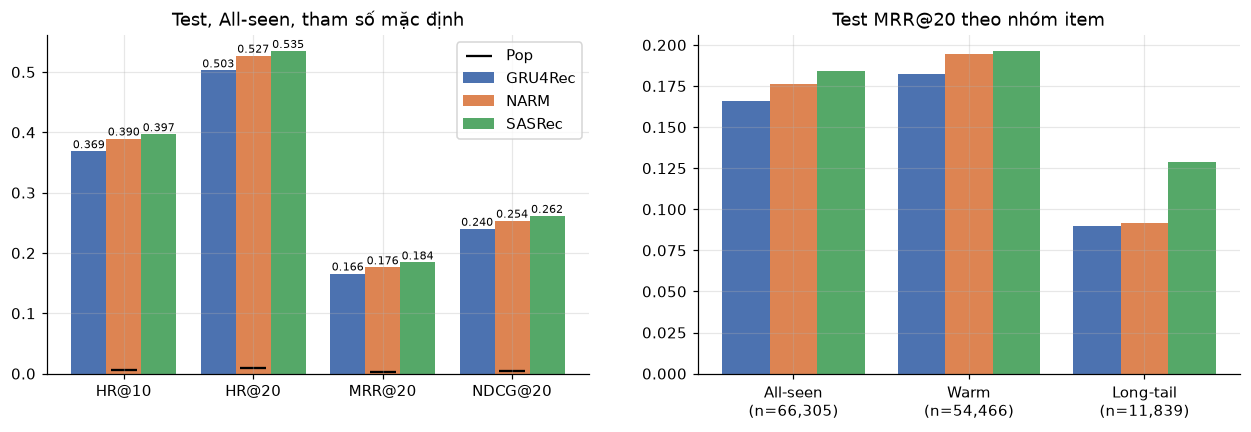

In [187]:
# ===== 10.12. Trái: 4 chỉ số × 3 mô hình; phải: MRR@20 theo nhóm Warm / Long-tail =====
MODEL_COLORS = {"GRU4Rec": "#4C72B0", "NARM": "#DD8452", "SASRec": "#55A868"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(METRIC_COLS))
for i, m in enumerate(MODELS):
    vals = [summary_table.loc[m, (k, "All-seen")] for k in METRIC_COLS]
    axes[0].bar(x + (i - 1) * .27, vals, .27, color=MODEL_COLORS[m], label=m)
    for xi, v in zip(x + (i - 1) * .27, vals):
        axes[0].text(xi, v + .005, f"{v:.3f}", ha="center", fontsize=7)
axes[0].scatter(x, [pop_metrics["All-seen"][k] for k in METRIC_COLS], color="black", marker="_", s=300, label="Pop")
axes[0].set_xticks(x)
axes[0].set_xticklabels(METRIC_COLS)
axes[0].set_title("Test, All-seen, tham số mặc định")
axes[0].legend()
gx = np.arange(len(EVAL_GROUPS))
for i, m in enumerate(MODELS):
    axes[1].bar(gx + (i - 1) * .27, [summary_table.loc[m, ("MRR@20", g)] for g in EVAL_GROUPS], .27,
                color=MODEL_COLORS[m], label=m)
axes[1].set_xticks(gx)
axes[1].set_xticklabels([f"{g}\n(n={pop_metrics[g]['n']:,})" for g in EVAL_GROUPS])
axes[1].set_title("Test MRR@20 theo nhóm item")
save_fig(fig, "m01_default_metrics.png")
plt.show()

### 10.13. Kết quả theo độ dài phiên (2–3, 4–5, 6–10, > 10)
Ghép hạng từng mẫu test với độ dài phiên của mẫu đó, lấy từ metadata ở Phần 6.

Bucket,2–3,4–5,6–10,>10
Model,,,,
GRU4Rec,0.2157,0.1876,0.1601,0.1332
NARM,0.2211,0.1956,0.1708,0.1469
SASRec,0.2349,0.2071,0.1769,0.1523


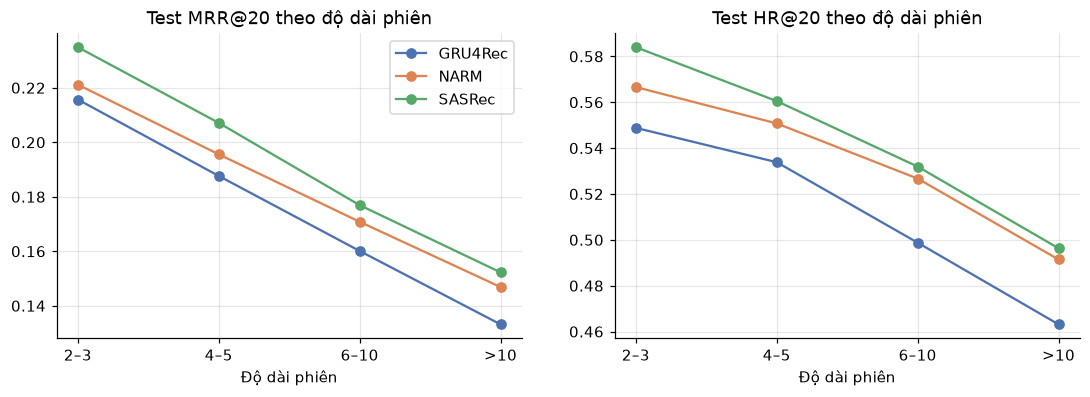

In [188]:
# ===== 10.13. MRR@20 và HR@20 theo bucket độ dài phiên (Mục 1.3 PDF) =====
meta = pd.read_csv(PREPARED_DIR / DATASET / "samples_metadata.csv.gz")
sess_len_map = meta[meta.split == "test"].drop_duplicates("session_id").set_index("session_id").session_len
bucket_rows = []
for r in default_res.values():
    rows_df = pd.DataFrame(r["test_rows"])
    rows_df["bucket"] = rows_df.session_id.astype(int).map(sess_len_map).map(length_bucket)
    assert rows_df.bucket.notna().all(), "Có mẫu test không tìm thấy độ dài phiên"
    vals = rank_metrics(rows_df["rank"])
    for b in LEN_LABELS:
        mask = (rows_df.bucket == b).to_numpy()
        bucket_rows.append({"Model": r["model"], "Bucket": b, "N": int(mask.sum()),
                            **{k: float(v[mask].mean()) for k, v in vals.items()}})
by_bucket = pd.DataFrame(bucket_rows)
display(by_bucket.pivot(index="Model", columns="Bucket", values="MRR@20")[LEN_LABELS].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, metric in zip(axes, ["MRR@20", "HR@20"]):
    for m in MODELS:
        d = by_bucket[by_bucket.Model == m].set_index("Bucket").loc[LEN_LABELS]
        ax.plot(LEN_LABELS, d[metric], marker="o", color=MODEL_COLORS[m], label=m)
    ax.set_xlabel("Độ dài phiên")
    ax.set_title(f"Test {metric} theo độ dài phiên")
axes[0].legend()
save_fig(fig, "m02_default_by_length.png")
plt.show()

### 10.14. Phân bố hạng của item đúng (CDF) — đọc được HR@K với mọi K

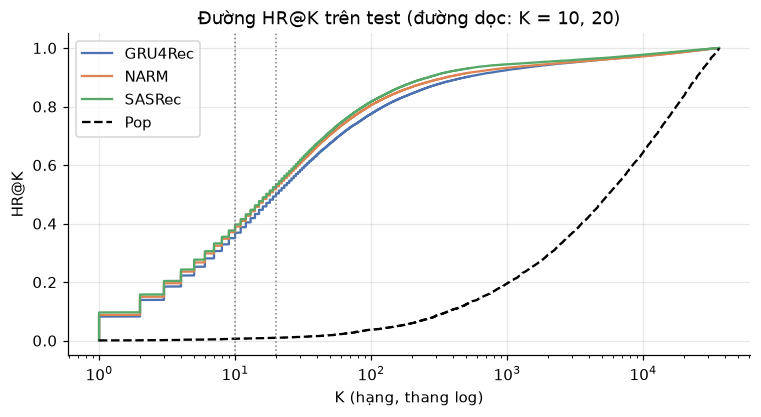

In [189]:
# ===== 10.14. Tỉ lệ mẫu có hạng <= K, với K từ 1 tới 36.244 (thang log) =====
fig, ax = plt.subplots(figsize=(8, 3.8))
for r in default_res.values():
    rk = np.sort(np.asarray(r["test_rows"]["rank"]))
    ax.plot(rk, np.arange(1, len(rk) + 1) / len(rk), color=MODEL_COLORS[r["model"]], label=r["model"])
ax.plot(np.sort(pop_ranks), np.arange(1, len(pop_ranks) + 1) / len(pop_ranks), color="black", ls="--", label="Pop")
for k in (10, 20):
    ax.axvline(k, color="gray", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("K (hạng, thang log)")
ax.set_ylabel("HR@K")
ax.set_title("Đường HR@K trên test (đường dọc: K = 10, 20)")
ax.legend()
save_fig(fig, "m03_default_rank_cdf.png")
plt.show()

### 10.15. Đường học: loss train và valid MRR@20 theo epoch

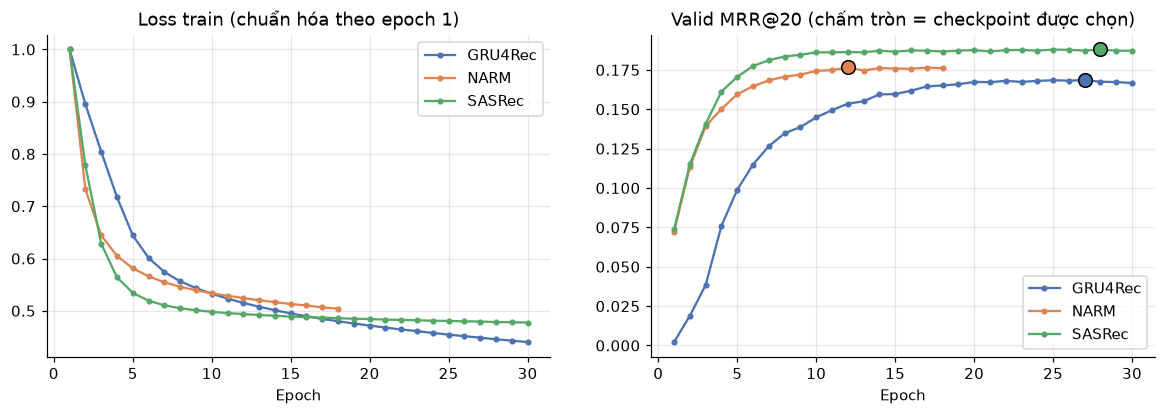

In [190]:
# ===== 10.15. Kiểm tra mô hình hội tụ chưa, dừng sớm ở đâu =====
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for r in default_res.values():
    h = pd.DataFrame(r["history"])
    c = MODEL_COLORS[r["model"]]
    axes[0].plot(h.epoch, h.train_loss / h.train_loss.iloc[0], marker=".", color=c, label=r["model"])
    axes[1].plot(h.epoch, h["valid_MRR@20"], marker=".", color=c, label=r["model"])
    axes[1].scatter(r["best_epoch"], r["best_valid_mrr20"], color=c, s=80, edgecolor="black", zorder=3)
axes[0].set_title("Loss train (chuẩn hóa theo epoch 1)")
axes[1].set_title("Valid MRR@20 (chấm tròn = checkpoint được chọn)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
save_fig(fig, "m04_default_learning_curves.png")
plt.show()

### 10.16. Lưu kết quả cho báo cáo và cho phần tìm siêu tham số

In [191]:
# ===== 10.16. CSV kết quả + hạng từng mẫu test (dùng cho kiểm định thống kê ở phần sau) =====
out_dir = ROOT / "output" / RUN_TAG / "default"
out_dir.mkdir(parents=True, exist_ok=True)
default_table.to_csv(out_dir / "default_test_by_group.csv", index=False, encoding="utf-8-sig")
by_bucket.to_csv(out_dir / "default_test_by_length.csv", index=False, encoding="utf-8-sig")
overview.to_csv(out_dir / "default_overview.csv", encoding="utf-8-sig")
for r in default_res.values():
    pd.DataFrame(r["test_rows"]).to_csv(out_dir / f"{r['name']}_test_rows.csv.gz", index=False)
    pd.DataFrame(r["history"]).to_csv(out_dir / f"{r['name']}_history.csv", index=False)
print("Đã lưu:")
for p in sorted(out_dir.iterdir()):
    print("  ", p.relative_to(ROOT))

Đã lưu:
   output\t10_v2\default\default-GRU4Rec-s42_history.csv
   output\t10_v2\default\default-GRU4Rec-s42_test_rows.csv.gz
   output\t10_v2\default\default-NARM-s42_history.csv
   output\t10_v2\default\default-NARM-s42_test_rows.csv.gz
   output\t10_v2\default\default-SASRec-s42_history.csv
   output\t10_v2\default\default-SASRec-s42_test_rows.csv.gz
   output\t10_v2\default\default_overview.csv
   output\t10_v2\default\default_test_by_group.csv
   output\t10_v2\default\default_test_by_length.csv


## Phần 11 — Tìm siêu tham số với ngân sách bằng nhau (random search 12 cấu hình / mô hình)

**Quy tắc công bằng (đề T10):**
- Mỗi mô hình thử đúng **12 cấu hình khác nhau**, chọn ngẫu nhiên trong cùng một kiểu không gian 4 trục:
  learning rate, hidden size, dropout, số lớp.
- Mọi cấu hình dùng **chung giao thức** với bản mặc định: 30 epoch, dừng sớm 5, seed 42, cùng dữ liệu, cùng cách đánh giá.
- Trong lúc tìm **không chấm test** (`run_test=False`). Chỉ dùng **valid MRR@20** để chọn.
- Sau khi đủ 12 cấu hình mới chọn winner, rồi **chấm test đúng 1 lần** cho winner (Phần 11.7).
- Cấu hình mặc định không tính vào 12; kế hoạch 36 cấu hình được **chốt trước khi train** (có checksum).

**Chi phí ước lượng:** 36 lần train, khoảng 3–9 phút mỗi lần, tổng **khoảng 3–4 giờ GPU H100**. Chạy 3 GPU song song nên chờ
khoảng 1–1,5 giờ. Chia 3 đợt khớp mốc kiểm tra của đề.

### 11.1. Chọn không gian tham số dựa trên bài báo

| Mô hình | Thiết lập trong bài gốc | Không gian tìm kiếm | Lý do |
|---|---|---|---|
| **GRU4Rec** [Hidasi 2016] | 1 lớp GRU (tác giả báo 1 lớp tốt nhất), 100–1000 hidden unit, dropout 0–0,5 | lr {3e-4, 1e-3, 3e-3} · hidden {64, 128, 256} · lớp {1, 2} · dropout {0,1; 0,3; 0,5} | Adam trong RecBole tốt quanh 1e-3, thử ×3 lên và xuống; hidden nhỏ hơn bài gốc vì Diginetica nhỏ hơn RSC15 |
| **NARM** [Li 2017] | embedding 50, hidden 100, Adam lr 0,001; dropout 0,25 sau embedding và 0,5 trước lớp ra | lr {3e-4, 1e-3, 3e-3} · hidden {64, 128, 256} · lớp {1, 2} · dropout [emb, ra] ∈ {[0,1; 0,1], [0,25; 0,5], [0,5; 0,5]} | Giữ cặp dropout như bài gốc, thêm mức thấp và mức cao |
| **SASRec** [Kang 2018] | d = 50, 2 block, dropout 0,2 (dữ liệu dày) / 0,5 (dữ liệu thưa), lr 0,001 | lr {3e-4, 1e-3, 3e-3} · hidden {32, 64, 128} · lớp {1, 2} · dropout {0,1; 0,3; 0,5} (dropout attention = dropout hidden) | Hidden chia hết cho 2 head; dropout phủ cả 2 mức tác giả khuyến nghị |

- **Random search** thay vì grid search: với ngân sách nhỏ, random search hiệu quả hơn [Bergstra & Bengio 2012].
- **Chọn theo valid MRR@20:** giống cách Ludewig và cộng sự (2021) làm với SBR.
- **Ngân sách tính bằng số cấu hình:** baseline tinh chỉnh kém là nguồn gốc của "tiến bộ ảo" [Ferrari Dacrema 2019].
- **Kích thước không gian:** mỗi mô hình 3·3·2·3 = 54 tổ hợp, bỏ tổ hợp trùng mặc định còn 53, lấy ngẫu nhiên 12.

### 11.2. Khai báo không gian tìm kiếm

In [192]:
# ===== 11.2. Bốn trục tìm kiếm cho mỗi mô hình =====
import itertools
import random

SEARCH_SEED, TRAIN_SEED, TRIALS_PER_MODEL = 2026, 42, 12
MODEL_SEED_OFFSETS = {"GRU4Rec": 0, "NARM": 1, "SASRec": 2}      # mỗi mô hình một luồng ngẫu nhiên riêng
AXES = {
    "GRU4Rec": {"learning_rate": [0.0003, 0.001, 0.003], "hidden_size": [64, 128, 256],
                "num_layers": [1, 2], "dropout_prob": [0.1, 0.3, 0.5]},
    "NARM": {"learning_rate": [0.0003, 0.001, 0.003], "hidden_size": [64, 128, 256],
             "n_layers": [1, 2], "dropout_probs": [[0.1, 0.1], [0.25, 0.5], [0.5, 0.5]]},
    "SASRec": {"learning_rate": [0.0003, 0.001, 0.003], "hidden_size": [32, 64, 128],
               "n_layers": [1, 2], "hidden_dropout_prob": [0.1, 0.3, 0.5]},
}
AXIS_LABEL = {"learning_rate": "lr", "hidden_size": "hidden", "num_layers": "số lớp", "n_layers": "số lớp",
              "dropout_prob": "dropout", "dropout_probs": "dropout", "hidden_dropout_prob": "dropout"}
for m in MODELS:
    print(f"{m:8s} mặc định:", {AXIS_LABEL[k]: DEFAULTS[m][k] for k in AXES[m]})

GRU4Rec  mặc định: {'lr': 0.001, 'hidden': 128, 'số lớp': 1, 'dropout': 0.3}
NARM     mặc định: {'lr': 0.001, 'hidden': 128, 'số lớp': 1, 'dropout': [0.25, 0.5]}
SASRec   mặc định: {'lr': 0.001, 'hidden': 64, 'số lớp': 2, 'dropout': 0.5}


### 11.3. Hàm liệt kê tổ hợp và lấy ngẫu nhiên 12 cấu hình

In [193]:
# ===== 11.3. 54 tổ hợp -> bỏ cấu hình mặc định -> lấy ngẫu nhiên 12 không trùng =====
def materialize(model, sampled):
    cfg = dict(sampled)
    if model == "SASRec":
        cfg["attn_dropout_prob"] = cfg["hidden_dropout_prob"]       # SASRec: dropout attention đi cùng dropout hidden
    return cfg


def enumerate_candidates(model):
    keys = list(AXES[model])
    out = []
    for values in itertools.product(*(AXES[model][k] for k in keys)):
        cfg = materialize(model, dict(zip(keys, values)))
        if any(DEFAULTS[model][k] != v for k, v in cfg.items()):    # bỏ đúng tổ hợp trùng mặc định
            out.append(cfg)
    return out


def sample_trials(model):
    rng = random.Random(SEARCH_SEED + MODEL_SEED_OFFSETS[model])
    chosen = rng.sample(enumerate_candidates(model), TRIALS_PER_MODEL)
    return [{"name": f"{model}-t{i:02d}", "model": model, "seed": TRAIN_SEED, "overrides": cfg,
             "run_test": False, "trial_index": i} for i, cfg in enumerate(chosen, start=1)]

### 11.4. Sinh 36 cấu hình và chốt kế hoạch trước khi train
Lưu manifest kèm checksum. Lần chạy sau mà kế hoạch khác bản đã chốt thì báo lỗi, để không ai đổi được kế hoạch sau khi
đã thấy kết quả.

In [194]:
# ===== 11.4. Manifest 36 trial + checksum =====
search_jobs = [t for m in MODELS for t in sample_trials(m)]
SEARCH_DIR = ROOT / "configs" / f"search_{RUN_TAG}"
SEARCH_DIR.mkdir(parents=True, exist_ok=True)
manifest = {"search_seed": SEARCH_SEED, "train_seed": TRAIN_SEED, "trials_per_model": TRIALS_PER_MODEL,
            "max_epochs": MAX_EPOCHS, "stopping_step": STOPPING_STEP, "selection": "valid MRR@20 (All-seen)",
            "tie_break": "trial_index nhỏ hơn", "test_during_search": False, "axes": AXES, "defaults": DEFAULTS,
            "data_fingerprint": FINGERPRINT, "trials": search_jobs}
blob = json.dumps(manifest, ensure_ascii=False, sort_keys=True, indent=1)
digest = hashlib.sha256(blob.encode()).hexdigest()
if (SEARCH_DIR / "checksum.txt").exists():
    assert (SEARCH_DIR / "checksum.txt").read_text().strip() == digest, "Kế hoạch đã bị sửa sau khi chốt!"
    print("Manifest đã chốt trước đó, checksum khớp:", digest[:16])
else:
    (SEARCH_DIR / "trial_manifest.json").write_text(blob, encoding="utf-8")
    (SEARCH_DIR / "checksum.txt").write_text(digest)
    print("Đã chốt manifest 36 trial:", digest[:16])
for m in MODELS:
    print(f"  {m}: {len(enumerate_candidates(m))} ứng viên -> chọn {TRIALS_PER_MODEL}")
plan = pd.DataFrame([{"trial": t["name"], **{AXIS_LABEL.get(k, k): str(v) for k, v in t["overrides"].items()
                                             if k != "attn_dropout_prob"}} for t in search_jobs])
plan.to_csv(SEARCH_DIR / "trial_plan.csv", index=False, encoding="utf-8-sig")
display(plan)

Đã chốt manifest 36 trial: 0a7cd872ec6f445b
  GRU4Rec: 53 ứng viên -> chọn 12
  NARM: 53 ứng viên -> chọn 12
  SASRec: 53 ứng viên -> chọn 12


,trial,lr,hidden,số lớp,dropout
0,GRU4Rec-t01,0.0003,128,1,0.3
1,GRU4Rec-t02,0.001,64,1,0.5
2,GRU4Rec-t03,0.001,256,2,0.1
3,GRU4Rec-t04,0.003,256,2,0.1
4,GRU4Rec-t05,0.003,128,1,0.1
5,GRU4Rec-t06,0.0003,128,1,0.1
6,GRU4Rec-t07,0.0003,256,1,0.5
7,GRU4Rec-t08,0.003,64,2,0.1
8,GRU4Rec-t09,0.003,64,2,0.3
9,GRU4Rec-t10,0.003,64,1,0.1


### 11.5. Biểu đồ: 12 cấu hình đã phủ đều các giá trị chưa?

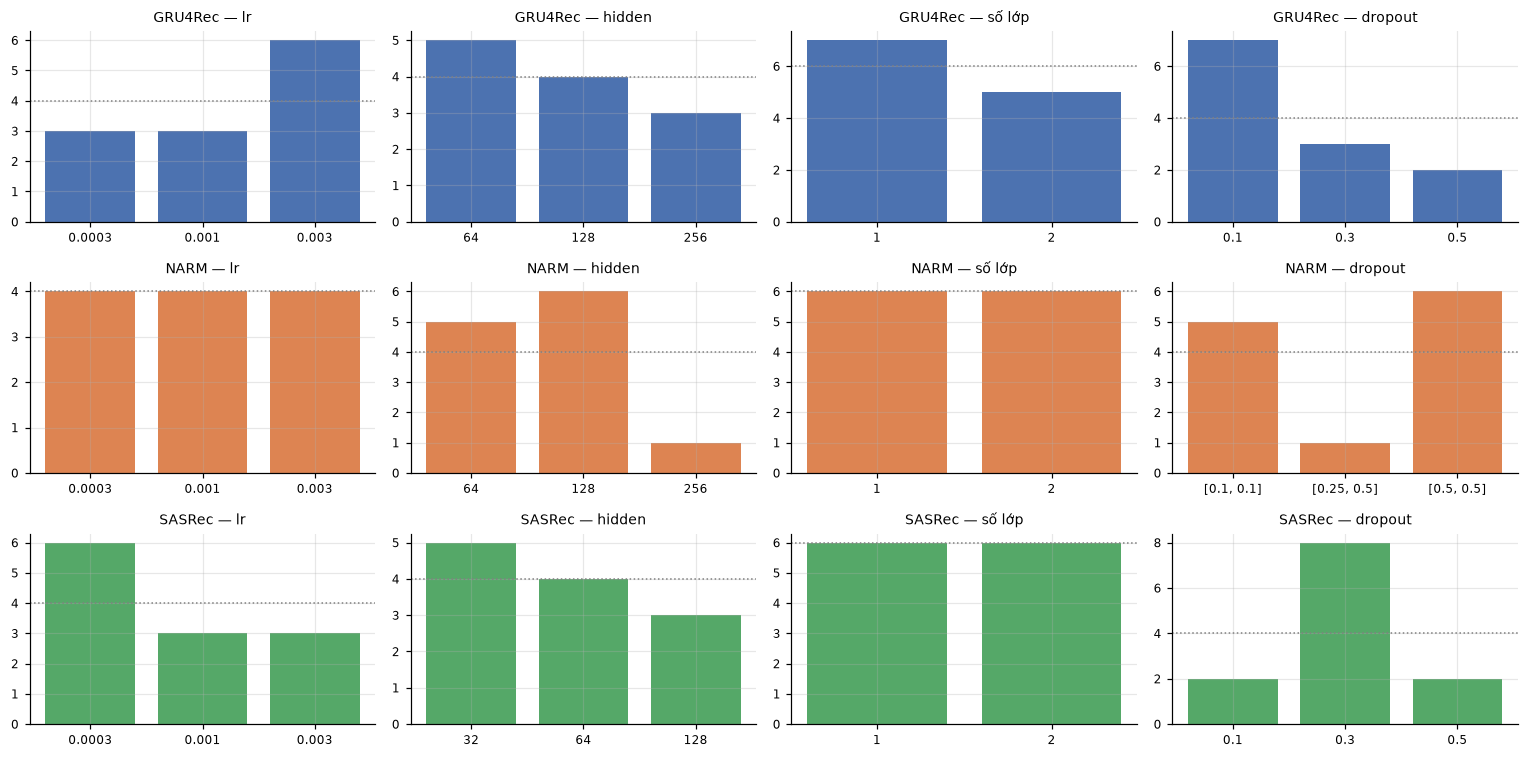

In [195]:
# ===== 11.5. Mỗi giá trị của mỗi trục xuất hiện bao nhiêu lần trong 12 trial =====
MODEL_COLORS = {"GRU4Rec": "#4C72B0", "NARM": "#DD8452", "SASRec": "#55A868"}
fig, axes = plt.subplots(3, 4, figsize=(14, 7))
for r_i, m in enumerate(MODELS):
    for c_i, axis in enumerate(AXES[m]):
        cnt = Counter(str(t["overrides"][axis]) for t in search_jobs if t["model"] == m)
        keys = [str(v) for v in AXES[m][axis]]
        axes[r_i, c_i].bar(keys, [cnt.get(k, 0) for k in keys], color=MODEL_COLORS[m])
        axes[r_i, c_i].axhline(TRIALS_PER_MODEL / len(keys), color="gray", ls=":", lw=1)
        axes[r_i, c_i].set_title(f"{m} — {AXIS_LABEL[axis]}", fontsize=9)
        axes[r_i, c_i].tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "s01_search_coverage.png")
plt.show()

### 11.6. CHẠY random search — 3 đợt, mỗi đợt cả 3 mô hình tiến đều nhau
Dừng ở đợt nào thì so sánh vẫn công bằng, vì 3 mô hình luôn có cùng số cấu hình. Mất mạng thì chạy lại đúng cell đó:
trial đã xong được tải về, không train lại.

#### Đợt 1 — cấu hình 1–3 (9 lần train, mốc tuần 3–4)

In [196]:
# ===== 11.6a. Trial 1..3 của cả 3 mô hình =====
run_jobs([t for t in search_jobs if t["trial_index"] <= 3], "Search đợt 1 (k=1..3)")

[Search đợt 1 (k=1..3)] 9 job | đã có: 0 | cần chạy: 9
✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-Re6aM44QiMOQomk6TUNt5e
- Initializing...
| Creating objects...objects...
├── - Creating Function h100_check...
- Creating objects...mote...
├── ✓ Created Function h100_check.
\ Creating objects...mote...
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
✓ Created objects.
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
- Running... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (2 containers initializing)... View app at 
| Loading images (3 containers initializing)... View app at 
- Loading images (3 containers initializing)... View app at 
| Loading images (3 containers initializing)... View app at 
- Running (1/3 containers active)... View app at 
| Running (1/3 containers active)... View app at 
- Running (2/3 containers active)... View app at 
| Running (2/3 c

#### Đợt 2 — cấu hình 4–6 (9 lần train, mốc tuần 6)

In [197]:
# ===== 11.6b. Trial 4..6 =====
run_jobs([t for t in search_jobs if 4 <= t["trial_index"] <= 6], "Search đợt 2 (k=4..6)")

[Search đợt 2 (k=4..6)] 9 job | đã có: 0 | cần chạy: 9
✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-Sk8cCGxiOeAb8bdr7K9OFd
- Initializing...
| Creating objects...objects...
├── - Creating Function h100_check...
- Creating objects...mote...
├── ✓ Created Function h100_check.
\ Creating objects...mote...
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
✓ Created objects.
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
- Running... View app at 
| Running... View app at CGxiOeAb8bdr7K9OFd
- Running... View app at CGxiOeAb8bdr7K9OFd
| Loading images (1 containers initializing)... View app at 
- Loading images (3 containers initializing)... View app at 
| Loading images (3 containers initializing)... View app at 
- Loading images (3 containers initializing)... View app at 
| Loading images (3 containers initializing)... View app at 
- Loading images (3 containers initializing)... View app at 
| Running (1/3 co

#### Đợt 3 — cấu hình 7–12 (18 lần train)

In [198]:
# ===== 11.6c. Trial 7..12 =====
run_jobs([t for t in search_jobs if t["trial_index"] >= 7], "Search đợt 3 (k=7..12)")

[Search đợt 3 (k=7..12)] 18 job | đã có: 0 | cần chạy: 18
✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-IAjFJIcjMseoJglZh4FF5r
- Initializing...
| Creating objects...objects...
├── - Creating Function h100_check...
- Creating objects...mote...
├── | Creating Function h100_check...
| Creating objects...mote...
├── ✓ Created Function h100_check.
| Creating objects...mote...
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
✓ Created objects.
├── ✓ Created Function h100_check.
└── ✓ Created Function train_remote.
| Running... View app at 
- Loading images (1 containers initializing)... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers initializing)... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers initializing)... View app at 
| Loading images (1 containers initializing)... View app at 
- Loading images (1 containers init

### 11.7. Bảng 36 trial: điểm valid, epoch tốt nhất, thời gian

In [199]:
# ===== 11.7. Tiến độ + kiểm tra KHÔNG trial nào có điểm test =====
search_res = load_jobs([t["name"] for t in search_jobs])
assert all(r["test"] is None for r in search_res.values()), "Trial tìm tham số không được chấm test!"
trials = pd.DataFrame([{"trial": n, "model": r["model"], "k": r["trial_index"],
                        **{AXIS_LABEL.get(a, a): str(v) for a, v in r["overrides"].items() if a != "attn_dropout_prob"},
                        "valid MRR@20": r["best_valid_mrr20"], "valid HR@20": r["valid"]["All-seen"]["HR@20"],
                        "best epoch": r["best_epoch"], "epochs": r["epochs_completed"], "dừng do": r["stop_reason"],
                        "phút": r["train_seconds"] / 60} for n, r in search_res.items()])
SEARCH_DONE = len(search_res) == len(search_jobs)
if len(trials):
    trials = trials.sort_values(["model", "k"]).reset_index(drop=True)
    print("Đã xong:", trials.groupby("model").size().to_dict(), f"/ {TRIALS_PER_MODEL} mỗi mô hình")
    display(trials.round(4))
else:
    print("Chưa có trial nào -> chạy 11.6.")

Đã xong: {'GRU4Rec': 12, 'NARM': 12, 'SASRec': 12} / 12 mỗi mô hình


,trial,model,k,lr,hidden,số lớp,dropout,valid MRR@20,valid HR@20,best epoch,epochs,dừng do,phút
0,GRU4Rec-t01,GRU4Rec,1,0.0003,128,1,0.3,0.1281,0.4423,29,30,epoch_limit,2.6682
1,GRU4Rec-t02,GRU4Rec,2,0.001,64,1,0.5,0.1679,0.5108,29,30,epoch_limit,2.6578
2,GRU4Rec-t03,GRU4Rec,3,0.001,256,2,0.1,0.1596,0.4923,12,18,early_stopping,2.1508
3,GRU4Rec-t04,GRU4Rec,4,0.003,256,2,0.1,0.1656,0.5047,6,12,early_stopping,1.5558
4,GRU4Rec-t05,GRU4Rec,5,0.003,128,1,0.1,0.1710,0.5068,8,14,early_stopping,1.2817
5,GRU4Rec-t06,GRU4Rec,6,0.0003,128,1,0.1,0.1355,0.4556,30,30,epoch_limit,2.8843
6,GRU4Rec-t07,GRU4Rec,7,0.0003,256,1,0.5,0.1121,0.4049,30,30,epoch_limit,2.8976
7,GRU4Rec-t08,GRU4Rec,8,0.003,64,2,0.1,0.1652,0.5030,8,14,early_stopping,1.6530
8,GRU4Rec-t09,GRU4Rec,9,0.003,64,2,0.3,0.1686,0.5089,12,18,early_stopping,2.1145
9,GRU4Rec-t10,GRU4Rec,10,0.003,64,1,0.1,0.1701,0.5082,8,14,early_stopping,1.5443


### 11.8. Chọn winner CHỈ bằng valid MRR@20
Winner = cấu hình có valid MRR@20 cao nhất trong 12 cấu hình; hòa thì lấy trial_index nhỏ hơn.
Cell này **không đọc điểm test** nào.

In [200]:
# ===== 11.8. Winner mỗi mô hình; lưu winners.json =====
assert SEARCH_DONE, "Chưa đủ 36 trial -> chạy hết 11.6 trước khi chọn winner"
winners = {}
for m in MODELS:
    cand = [r for r in search_res.values() if r["model"] == m]
    winners[m] = min(cand, key=lambda r: (-r["best_valid_mrr20"], r["trial_index"]))
    w = winners[m]
    print(f"{m:8s} winner = {w['name']}  valid MRR@20 = {w['best_valid_mrr20']:.4f}  "
          f"(default {load_jobs([f'default-{m}-s{TRAIN_SEED}'])[f'default-{m}-s{TRAIN_SEED}']['best_valid_mrr20']:.4f})  "
          f"cấu hình = { {AXIS_LABEL.get(k, k): v for k, v in w['overrides'].items() if k != 'attn_dropout_prob'} }")
(ROOT / "output" / RUN_TAG).mkdir(parents=True, exist_ok=True)
write_json(ROOT / "output" / RUN_TAG / "winners.json",
           {m: {"trial": w["name"], "overrides": w["overrides"], "valid_mrr20": w["best_valid_mrr20"]}
            for m, w in winners.items()})

GRU4Rec  winner = GRU4Rec-t12  valid MRR@20 = 0.1751  (default 0.1686)  cấu hình = {'lr': 0.003, 'hidden': 64, 'số lớp': 1, 'dropout': 0.3}
NARM     winner = NARM-t02  valid MRR@20 = 0.1786  (default 0.1765)  cấu hình = {'lr': 0.001, 'hidden': 256, 'số lớp': 1, 'dropout': [0.1, 0.1]}
SASRec   winner = SASRec-t07  valid MRR@20 = 0.1945  (default 0.1880)  cấu hình = {'lr': 0.0003, 'hidden': 128, 'số lớp': 2, 'dropout': 0.3}


### 11.9. Chấm test cho winner (nạp lại checkpoint, không train lại)
Hàm từ xa nạp checkpoint tốt nhất của trial winner trên Volume, chấm lại valid (phải khớp điểm lúc train, chứng tỏ
nạp đúng mô hình) rồi chấm test. Mỗi winner chấm test đúng 1 lần.

In [201]:
# ===== 11.9. test_checkpoint chạy trên H100 + chạy cho 3 winner =====
def test_checkpoint(train_result):
    import torch
    from recbole.data import create_dataset, data_preparation
    from recbole.utils import get_model

    out_file = Path(f"{REMOTE_ROOT}/results/{RUN_TAG}/{train_result['name']}/winner_test.json")
    if out_file.exists():
        return json.loads(out_file.read_text(encoding="utf-8"))
    ckpt = torch.load(train_result["checkpoint"], map_location="cpu", weights_only=False)
    config = ckpt["config"]
    config["device"] = torch.device("cuda")
    config["data_path"] = str(Path(REMOTE_PREPARED) / DATASET)
    ds = create_dataset(config)
    train_data, valid_data, test_data = data_preparation(config, ds)
    model = get_model(train_result["model"])(config, train_data._dataset).to(config["device"])
    model.load_state_dict(ckpt["state_dict"])
    model.load_other_parameter(ckpt.get("other_parameter"))
    counts = json.loads((Path(REMOTE_PREPARED) / DATASET / "train_item_counts.json").read_text(encoding="utf-8"))
    tokens = ds.field2id_token[ds.iid_field]
    counts_by_id = np.array([0] + [counts[str(t)] for t in tokens[1:]], dtype=np.int64)
    valid_summary, _ = evaluate_full(model, valid_data._dataset, counts_by_id)
    assert abs(valid_summary["All-seen"]["MRR@20"] - train_result["best_valid_mrr20"]) < 1e-4, "Checkpoint nạp sai"
    test_summary, rows = evaluate_full(model, test_data._dataset, counts_by_id, keep_rows=True)
    res = {"name": train_result["name"], "model": train_result["model"], "overrides": train_result["overrides"],
           "trial_index": train_result["trial_index"], "best_valid_mrr20": train_result["best_valid_mrr20"],
           "valid": valid_summary, "test": test_summary, "test_rows": rows, "fingerprint": FINGERPRINT}
    out_file.write_text(json.dumps(res), encoding="utf-8")
    return res


@app.function(image=gpu_image, gpu=GPU_TYPE, cpu=4, memory=16384, timeout=1800, volumes={REMOTE_ROOT: volume},
              serialized=True, max_containers=MAX_CONTAINERS, retries=0)
def test_remote(train_result):
    volume.reload()
    try:
        return test_checkpoint(train_result)
    finally:
        volume.commit()


run_remote(test_remote, [winners[m] for m in MODELS], "Test winner", kind="test")
winner_tests = load_jobs([winners[m]["name"] for m in MODELS], kind="test")
assert len(winner_tests) == 3, "Chưa đủ kết quả test winner -> chạy lại cell này"

[Test winner] 3 job | đã có: 0 | cần chạy: 3
✓ Initialized. View run at 
https://modal.com/apps/tuananhnguyen28112005/main/ap-PeDxu4BLKj06BaRQ68n5sf
- Initializing...
| Creating objects...objects...
├── - Creating Function h100_check...
├── - Creating Function train_remote...
- Creating objects...
├── | Creating Function h100_check...
├── | Creating Function train_remote...
| Creating objects...
├── - Creating Function h100_check...
├── - Creating Function train_remote...
- Creating objects....
├── | Creating Function h100_check...
├── | Creating Function train_remote...
| Creating objects....
├── - Creating Function h100_check...
├── - Creating Function train_remote...
- Creating objects....
├── | Creating Function h100_check...
├── ✓ Created Function train_remote.
- Creating objects....
├── ✓ Created Function h100_check.
├── ✓ Created Function train_remote.
└── ✓ Created Function test_remote.
✓ Created objects.
├── ✓ Created Function h100_check.
├── ✓ Created Function train_remote.
└

### 11.10. (Tùy chọn, tốn thêm GPU) Lặp seed để đo dao động do khởi tạo
Kết quả chính dùng seed 42. Muốn biết mức cải thiện có lớn hơn dao động ngẫu nhiên không, thêm seed vào
`EXTRA_SEEDS` (ví dụ `[43, 44]`). Khi đó sẽ train thêm default và winner với các seed đó: 12 lần train.
Phần 12.12 tự dùng kết quả này nếu có.

In [202]:
# ===== 11.10. Mặc định không chạy (EXTRA_SEEDS rỗng) =====
EXTRA_SEEDS = []          # ví dụ [43, 44]
seed_jobs = [{"name": f"{variant}-{m}-s{s}", "model": m, "seed": s, "run_test": True, "trial_index": 0,
              "overrides": {} if variant == "default" else winners[m]["overrides"]}
             for m in MODELS for s in EXTRA_SEEDS for variant in ("default", "tuned")]
if seed_jobs:
    run_jobs(seed_jobs, "Lặp seed")
else:
    print("Không chạy lặp seed (EXTRA_SEEDS rỗng).")

Không chạy lặp seed (EXTRA_SEEDS rỗng).


## Phần 12 — So sánh bản mặc định với bản đã tinh chỉnh: có công bằng không?

Chỉ đọc kết quả đã lưu, chạy CPU. Trả lời 3 câu hỏi của đề:
1. Tinh chỉnh cải thiện mỗi mô hình bao nhiêu?
2. Thứ hạng có đổi không?
3. Thử bao nhiêu cấu hình thì bão hòa?

Thêm các phân tích về tính công bằng.

### 12.1. Gom kết quả test: default (seed 42) và tuned (winner)

In [203]:
# ===== 12.1. Bảng dài: Model × Variant × Group × 4 chỉ số =====
default42 = {m: load_jobs([f"default-{m}-s{TRAIN_SEED}"])[f"default-{m}-s{TRAIN_SEED}"] for m in MODELS}
tuned42 = {m: winner_tests[winners[m]["name"]] for m in MODELS}
long_rows = []
for variant, src in (("Default", default42), ("Tuned", tuned42)):
    for m in MODELS:
        for g in EVAL_GROUPS:
            long_rows.append({"Model": m, "Variant": variant, "Group": g, "N": src[m]["test"][g]["n"],
                              **{k: src[m]["test"][g][k] for k in METRIC_COLS}})
scores = pd.DataFrame(long_rows)
display(scores.pivot_table(index=["Model", "Variant"], columns="Group", values="MRR@20")[EVAL_GROUPS].round(4))

Group            All-seen    Warm  Long-tail
Model   Variant                             
GRU4Rec Default    0.1660  0.1825     0.0897
        Tuned      0.1753  0.1912     0.1023
NARM    Default    0.1762  0.1946     0.0915
        Tuned      0.1799  0.1969     0.1019
SASRec  Default    0.1843  0.1963     0.1290
        Tuned      0.1916  0.2045     0.1325

### 12.2. Câu hỏi 1 — Tinh chỉnh cải thiện mỗi mô hình bao nhiêu?

In [204]:
# ===== 12.2. Default vs tuned: giá trị, chênh tuyệt đối, chênh tương đối (%) =====
gain_rows = []
for m in MODELS:
    for g in EVAL_GROUPS:
        for k in METRIC_COLS:
            d = scores.query("Model == @m and Group == @g and Variant == 'Default'")[k].iloc[0]
            t = scores.query("Model == @m and Group == @g and Variant == 'Tuned'")[k].iloc[0]
            gain_rows.append({"Model": m, "Group": g, "Metric": k, "Default": d, "Tuned": t,
                              "Chênh": t - d, "Chênh %": (t / d - 1) * 100})
gains = pd.DataFrame(gain_rows)
q1 = gains.pivot_table(index=["Model", "Group"], columns="Metric", values="Chênh %")[METRIC_COLS]
print("Mức tăng tương đối (%) của bản tuned so với default:")
display(q1.round(2))
display(gains[gains.Group == "All-seen"].set_index(["Model", "Metric"])[["Default", "Tuned", "Chênh", "Chênh %"]].round(4))

Mức tăng tương đối (%) của bản tuned so với default:


Metric             HR@10  HR@20  MRR@20  NDCG@20
Model   Group                                   
GRU4Rec All-seen    4.07   2.83    5.63     4.41
        Long-tail  11.21   8.93   14.01    11.63
        Warm        3.31   2.11    4.74     3.61
NARM    All-seen   -0.28  -0.74    2.12     0.80
        Long-tail   8.93   1.71   11.38     6.86
        Warm       -1.22  -1.03    1.17     0.14
SASRec  All-seen    4.77   3.56    3.98     3.90
        Long-tail   6.15   6.21    2.72     4.30
        Warm        4.60   3.20    4.16     3.84

Default   Tuned   Chênh  Chênh %
Model   Metric                                   
GRU4Rec HR@10     0.3687  0.3837  0.0150   4.0663
        HR@20     0.5027  0.5170  0.0142   2.8320
        MRR@20    0.1660  0.1753  0.0093   5.6331
        NDCG@20   0.2401  0.2507  0.0106   4.4098
NARM    HR@10     0.3897  0.3886 -0.0011  -0.2825
        HR@20     0.5271  0.5232 -0.0039  -0.7411
        MRR@20    0.1762  0.1799  0.0037   2.1192
        NDCG@20   0.2536  0.2556  0.0020   0.8032
SASRec  HR@10     0.3969  0.4158  0.0189   4.7729
        HR@20     0.5349  0.5540  0.0190   3.5552
        MRR@20    0.1843  0.1916  0.0073   3.9802
        NDCG@20   0.2615  0.2717  0.0102   3.8981

### 12.3. Biểu đồ Câu hỏi 1

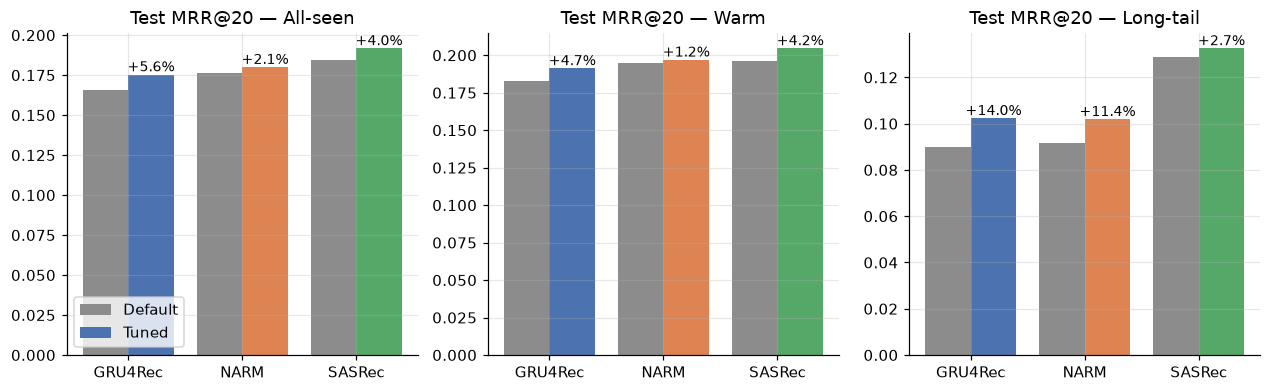

In [205]:
# ===== 12.3. Cột đôi default/tuned cho MRR@20 ở 3 nhóm, ghi % tăng =====
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, g in zip(axes, EVAL_GROUPS):
    sub = scores[scores.Group == g].pivot(index="Model", columns="Variant", values="MRR@20").loc[list(MODELS)]
    x = np.arange(len(MODELS))
    ax.bar(x - .2, sub.Default, .4, color="#8C8C8C", label="Default")
    ax.bar(x + .2, sub.Tuned, .4, color=[MODEL_COLORS[m] for m in MODELS], label="Tuned")
    for i, m in enumerate(MODELS):
        ax.text(i + .2, sub.loc[m, "Tuned"], f"{(sub.loc[m, 'Tuned'] / sub.loc[m, 'Default'] - 1) * 100:+.1f}%",
                ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS)
    ax.set_title(f"Test MRR@20 — {g}")
axes[0].legend()
save_fig(fig, "c01_default_vs_tuned.png")
plt.show()

### 12.4. Câu hỏi 2 — Thứ hạng 3 mô hình có đổi không?

In [206]:
# ===== 12.4. Thứ tự mô hình theo từng nhóm × chỉ số, trước và sau tinh chỉnh =====
rank_rows = []
for g in EVAL_GROUPS:
    for k in METRIC_COLS:
        mean = scores[scores.Group == g].set_index(["Variant", "Model"])[k]
        o_d = " > ".join(mean["Default"].sort_values(ascending=False).index)
        o_t = " > ".join(mean["Tuned"].sort_values(ascending=False).index)
        rank_rows.append({"Group": g, "Metric": k, "Default": o_d, "Tuned": o_t, "Đổi hạng?": o_d != o_t})
ranks = pd.DataFrame(rank_rows)
display(ranks)
print("Số tổ hợp (nhóm × chỉ số) đổi thứ hạng:", int(ranks["Đổi hạng?"].sum()), "/", len(ranks))

,Group,Metric,Default,Tuned,Đổi hạng?
0,All-seen,HR@10,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
1,All-seen,HR@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
2,All-seen,MRR@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
3,All-seen,NDCG@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
4,Warm,HR@10,NARM > SASRec > GRU4Rec,SASRec > NARM > GRU4Rec,True
5,Warm,HR@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
6,Warm,MRR@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
7,Warm,NDCG@20,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
8,Long-tail,HR@10,SASRec > NARM > GRU4Rec,SASRec > NARM > GRU4Rec,False
9,Long-tail,HR@20,SASRec > NARM > GRU4Rec,SASRec > GRU4Rec > NARM,True


Số tổ hợp (nhóm × chỉ số) đổi thứ hạng: 4 / 12


### 12.5. Câu hỏi 3 — Valid tốt nhất sau k cấu hình (k = 1…12)
Đường bậc thang = điểm valid tốt nhất trong k cấu hình đầu, theo thứ tự đã chốt trong manifest. Đường đỏ = default.

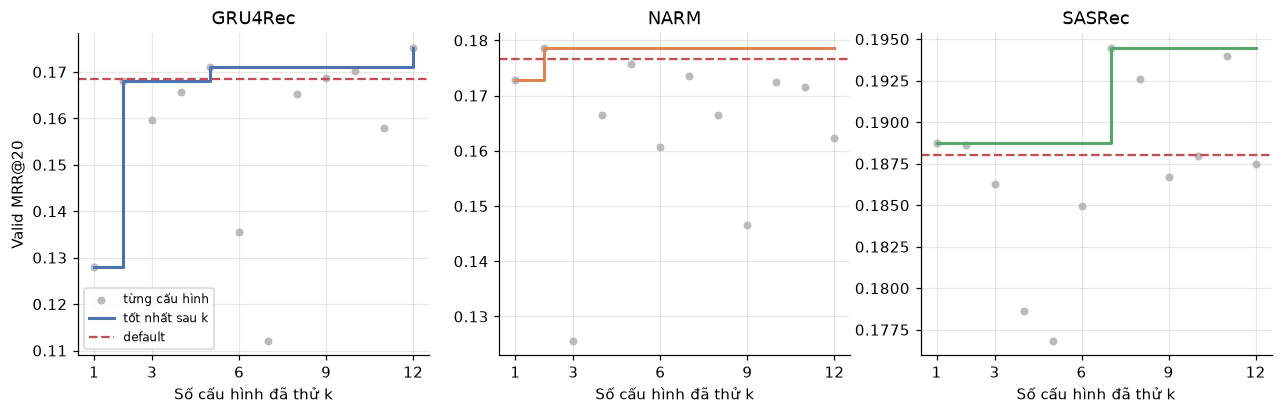

,Default,Best@1,Best@3,Best@6,Best@12,Tăng 6→12,k đạt 99% best cuối,k đầu tiên vượt default
Model,,,,,,,,
GRU4Rec,0.1686,0.1281,0.1679,0.1710,0.1751,0.0041,12,5
NARM,0.1765,0.1728,0.1786,0.1786,0.1786,0.0000,2,2
SASRec,0.1880,0.1888,0.1888,0.1888,0.1945,0.0057,7,1


In [207]:
# ===== 12.5. Best-so-far theo số cấu hình + bảng bão hòa =====
trials["best_so_far"] = trials.groupby("model")["valid MRR@20"].cummax()
default_valid = {m: default42[m]["best_valid_mrr20"] for m in MODELS}
sat_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, m in zip(axes, MODELS):
    c = trials[trials.model == m].set_index("k")
    ax.scatter(c.index, c["valid MRR@20"], color="#BBBBBB", s=18, label="từng cấu hình")
    ax.step(c.index, c.best_so_far, where="post", color=MODEL_COLORS[m], lw=2, label="tốt nhất sau k")
    ax.axhline(default_valid[m], color="#C44E52", ls="--", label="default")
    ax.set_xticks([1, 3, 6, 9, 12])
    ax.set_xlabel("Số cấu hình đã thử k")
    ax.set_title(m)
    final = c.best_so_far.loc[TRIALS_PER_MODEL]
    beat = c.best_so_far[c.best_so_far > default_valid[m]]
    sat_rows.append({"Model": m, "Default": default_valid[m], **{f"Best@{k}": c.best_so_far.loc[k] for k in (1, 3, 6, 12)},
                     "Tăng 6→12": c.best_so_far.loc[12] - c.best_so_far.loc[6],
                     "k đạt 99% best cuối": int(c.best_so_far[c.best_so_far >= .99 * final].index.min()),
                     "k đầu tiên vượt default": int(beat.index.min()) if len(beat) else None})
axes[0].set_ylabel("Valid MRR@20")
axes[0].legend(fontsize=8)
save_fig(fig, "c02_budget_curves.png")
plt.show()
saturation = pd.DataFrame(sat_rows).set_index("Model")
display(saturation.round(4))

### 12.6. Câu hỏi 3 (vững hơn) — Kỳ vọng best-of-k khi thứ tự thử là ngẫu nhiên
Đường ở 12.5 phụ thuộc thứ tự trial đã chốt. Ở đây xáo ngẫu nhiên thứ tự 12 cấu hình 5.000 lần để có giá trị kỳ vọng,
dải 10–90%, và xác suất "best-of-k vượt default".

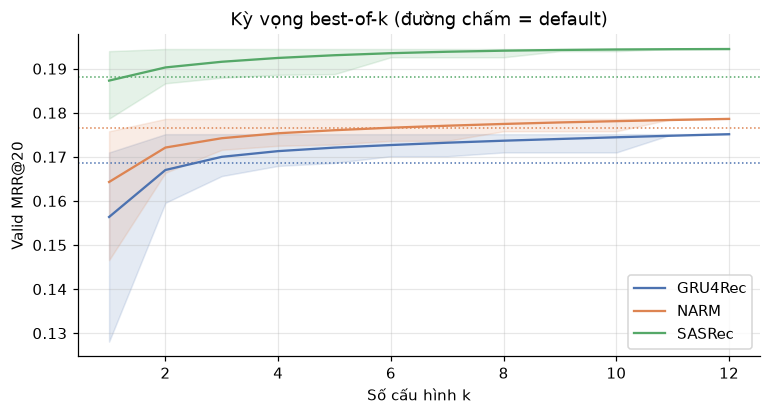

E[best-of-k]                      P(> default)                   
k                 1      3      6      12           1      3      6    12
Model                                                                    
GRU4Rec        0.156  0.170  0.173  0.175        0.339  0.743  0.968  1.0
NARM           0.164  0.174  0.177  0.179        0.079  0.250  0.500  1.0
SASRec         0.187  0.192  0.194  0.194        0.418  0.831  0.992  1.0

In [208]:
# ===== 12.6. E[max valid trong k cấu hình], dải 10–90%, P(> default) =====
rng = np.random.default_rng(TRAIN_SEED)
exp_rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
kk = np.arange(1, TRIALS_PER_MODEL + 1)
for m in MODELS:
    v = trials[trials.model == m]["valid MRR@20"].to_numpy()
    best_k = np.maximum.accumulate(np.array([rng.permutation(v) for _ in range(5000)]), axis=1)
    ax.plot(kk, best_k.mean(0), color=MODEL_COLORS[m], label=m)
    ax.fill_between(kk, np.percentile(best_k, 10, 0), np.percentile(best_k, 90, 0), color=MODEL_COLORS[m], alpha=.15)
    ax.axhline(default_valid[m], color=MODEL_COLORS[m], ls=":", lw=1)
    for k in (1, 3, 6, 12):
        exp_rows.append({"Model": m, "k": k, "E[best-of-k]": best_k[:, k - 1].mean(),
                         "P(> default)": (best_k[:, k - 1] > default_valid[m]).mean()})
ax.set_xlabel("Số cấu hình k")
ax.set_ylabel("Valid MRR@20")
ax.set_title("Kỳ vọng best-of-k (đường chấm = default)")
ax.legend()
save_fig(fig, "c03_expected_best_of_k.png")
plt.show()
display(pd.DataFrame(exp_rows).pivot(index="Model", columns="k").round(3))

### 12.7. Ngân sách bằng số cấu hình hay bằng thời gian GPU?
Cùng 12 cấu hình nhưng thời gian train của mỗi mô hình khác nhau. Nếu chia **cùng số phút GPU**, kết luận có đổi không?

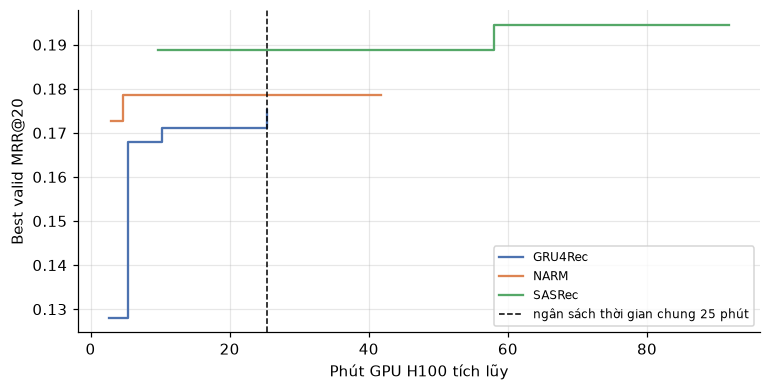

,Model,Tổng phút 12 cấu hình,Số cấu hình trong 25 phút,Best valid trong 25 phút,Best valid 12 cấu hình
0,GRU4Rec,25.4149,12,0.1751,0.1751
1,NARM,41.7203,7,0.1786,0.1786
2,SASRec,91.7969,2,0.1888,0.1945


In [209]:
# ===== 12.7. Best valid theo phút GPU tích lũy; cắt ở mức thời gian của mô hình tốn ít nhất =====
trials["phút tích lũy"] = trials.groupby("model")["phút"].cumsum()
T = trials.groupby("model")["phút"].sum().min()
time_rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
for m in MODELS:
    c = trials[trials.model == m]
    ax.step(c["phút tích lũy"], c.best_so_far, where="post", color=MODEL_COLORS[m], label=m)
    within = c[c["phút tích lũy"] <= T]
    time_rows.append({"Model": m, "Tổng phút 12 cấu hình": c["phút"].sum(), f"Số cấu hình trong {T:.0f} phút": len(within),
                      f"Best valid trong {T:.0f} phút": within["valid MRR@20"].max() if len(within) else np.nan,
                      "Best valid 12 cấu hình": c["valid MRR@20"].max()})
ax.axvline(T, color="black", ls="--", lw=1, label=f"ngân sách thời gian chung {T:.0f} phút")
ax.set_xlabel("Phút GPU H100 tích lũy")
ax.set_ylabel("Best valid MRR@20")
ax.legend(fontsize=8)
save_fig(fig, "c04_budget_by_time.png")
plt.show()
display(pd.DataFrame(time_rows).round(4))

### 12.8. So sánh KHÔNG công bằng dẫn tới kết luận sai thế nào?
Mô phỏng tình huống hay gặp: mô hình A được tinh chỉnh, mô hình B để mặc định. So chênh lệch "A tuned − B default" với
chênh lệch công bằng "A tuned − B tuned".

In [210]:
# ===== 12.8. Chênh test MRR@20 (All-seen): công bằng vs không công bằng =====
mrr = scores[scores.Group == "All-seen"].set_index(["Variant", "Model"])["MRR@20"]
unfair_rows = []
for a, b in itertools.permutations(MODELS, 2):
    fair, unfair = mrr["Tuned"][a] - mrr["Tuned"][b], mrr["Tuned"][a] - mrr["Default"][b]
    unfair_rows.append({"A (tuned)": a, "B": b, "Công bằng: A − B tuned": fair, "Không công bằng: A − B default": unfair,
                        "Phóng đại (%)": (unfair - fair) / abs(fair) * 100, "Đảo kết luận?": bool(np.sign(fair) != np.sign(unfair))})
unfair = pd.DataFrame(unfair_rows)
display(unfair.round(4))

,A (tuned),B,Công bằng: A − B tuned,Không công bằng: A − B default,Phóng đại (%),Đảo kết luận?
0,GRU4Rec,NARM,-0.0046,-0.0009,80.4888,False
1,GRU4Rec,SASRec,-0.0163,-0.0090,44.9109,False
2,NARM,GRU4Rec,0.0046,0.0140,201.4971,False
3,NARM,SASRec,-0.0117,-0.0044,62.7285,False
4,SASRec,GRU4Rec,0.0163,0.0257,57.2341,False
5,SASRec,NARM,0.0117,0.0154,31.9327,False


### 12.9. Mức chênh có thật hay do ngẫu nhiên? Bootstrap ghép cặp trên từng mẫu test
Lấy mẫu lại 66 nghìn mẫu test 2.000 lần để có khoảng tin cậy 95% cho:
- mức tăng tuned − default của từng mô hình;
- khoảng cách giữa các mô hình.

CI không chứa 0 thì chênh lệch không phải do may rủi của tập test. Bootstrap không đo dao động do seed (xem 11.10).

In [211]:
# ===== 12.9. Bootstrap ghép cặp (cùng mẫu test) =====
def paired_bootstrap(diff, n_boot=2000, chunk=100, seed=TRAIN_SEED):
    rng_b = np.random.default_rng(seed)
    means = np.concatenate([diff[rng_b.integers(0, len(diff), (chunk, len(diff)))].mean(1) for _ in range(n_boot // chunk)])
    return np.percentile(means, [2.5, 97.5])


inst = {}
for m in MODELS:
    d_rows, t_rows = default42[m]["test_rows"], tuned42[m]["test_rows"]
    assert d_rows["session_id"] == t_rows["session_id"] and d_rows["target"] == t_rows["target"], "Thứ tự mẫu test khác nhau"
    inst[m] = {"Default": rank_metrics(d_rows["rank"])["MRR@20"], "Tuned": rank_metrics(t_rows["rank"])["MRR@20"],
               "cnt": np.asarray(d_rows["train_count"])}
boot_rows = []
for m in MODELS:
    for g, mask in {"All-seen": inst[m]["cnt"] > 0, "Warm": inst[m]["cnt"] > THETA_WARM,
                    "Long-tail": inst[m]["cnt"] <= THETA_WARM}.items():
        diff = inst[m]["Tuned"][mask] - inst[m]["Default"][mask]
        lo, hi = paired_bootstrap(diff)
        boot_rows.append({"So sánh": f"{m}: tuned − default", "Group": g, "Chênh MRR@20": diff.mean(),
                          "CI95 thấp": lo, "CI95 cao": hi, "Có ý nghĩa": bool(lo > 0 or hi < 0)})
for a, b in (("SASRec", "NARM"), ("NARM", "GRU4Rec"), ("SASRec", "GRU4Rec")):
    for variant in ("Default", "Tuned"):
        diff = inst[a][variant] - inst[b][variant]
        lo, hi = paired_bootstrap(diff)
        boot_rows.append({"So sánh": f"{a} − {b} ({variant})", "Group": "All-seen", "Chênh MRR@20": diff.mean(),
                          "CI95 thấp": lo, "CI95 cao": hi, "Có ý nghĩa": bool(lo > 0 or hi < 0)})
bootstrap = pd.DataFrame(boot_rows)
display(bootstrap.round(4))

,So sánh,Group,Chênh MRR@20,CI95 thấp,CI95 cao,Có ý nghĩa
0,GRU4Rec: tuned − default,All-seen,0.0093,0.0077,0.0111,True
1,GRU4Rec: tuned − default,Warm,0.0086,0.0067,0.0105,True
2,GRU4Rec: tuned − default,Long-tail,0.0126,0.0093,0.0159,True
3,NARM: tuned − default,All-seen,0.0037,0.0022,0.0053,True
4,NARM: tuned − default,Warm,0.0023,0.0003,0.0042,True
5,NARM: tuned − default,Long-tail,0.0104,0.0073,0.0136,True
6,SASRec: tuned − default,All-seen,0.0073,0.0065,0.0082,True
7,SASRec: tuned − default,Warm,0.0082,0.0072,0.0091,True
8,SASRec: tuned − default,Long-tail,0.0035,0.0019,0.0053,True
9,SASRec − NARM (Default),All-seen,0.0081,0.0064,0.0098,True


### 12.10. Tham số nào ảnh hưởng nhiều nhất? Có cấu hình nào bị giới hạn 30 epoch cắt ngang?

In [212]:
# ===== 12.10. Valid trung bình theo từng giá trị tham số; liệt kê trial có best epoch = 30 =====
for m in MODELS:
    sub = trials[trials.model == m]
    parts = [f"{AXIS_LABEL[a]}: " + str(sub.groupby(AXIS_LABEL[a])["valid MRR@20"].mean().round(4).to_dict())
             for a in AXES[m]]
    print(f"{m}\n   " + "\n   ".join(parts))
capped = trials[trials["best epoch"] >= MAX_EPOCHS]
print(f"\n{len(capped)}/{len(trials)} cấu hình có epoch tốt nhất = {MAX_EPOCHS} (vẫn đang tăng khi bị dừng):")
display(capped[["trial", "lr", "valid MRR@20", "best epoch"]].round(4))

GRU4Rec
   lr: {'0.0003': 0.1252, '0.001': 0.1618, '0.003': 0.1693}
   hidden: {'128': 0.1481, '256': 0.1458, '64': 0.1694}
   số lớp: {'1': 0.1514, '2': 0.1634}
   dropout: {'0.1': 0.1607, '0.3': 0.1573, '0.5': 0.14}
NARM
   lr: {'0.0003': 0.1529, '0.001': 0.1688, '0.003': 0.1716}
   hidden: {'128': 0.1688, '256': 0.1786, '64': 0.1563}
   số lớp: {'1': 0.1713, '2': 0.1575}
   dropout: {'[0.1, 0.1]': 0.1731, '[0.25, 0.5]': 0.1623, '[0.5, 0.5]': 0.1576}
SASRec
   lr: {'0.0003': 0.1894, '0.001': 0.1844, '0.003': 0.186}
   hidden: {'128': 0.1911, '32': 0.1839, '64': 0.1885}
   số lớp: {'1': 0.1866, '2': 0.1879}
   dropout: {'0.1': 0.191, '0.3': 0.1875, '0.5': 0.1827}

7/36 cấu hình có epoch tốt nhất = 30 (vẫn đang tăng khi bị dừng):


,trial,lr,valid MRR@20,best epoch
5,GRU4Rec-t06,0.0003,0.1355,30
6,GRU4Rec-t07,0.0003,0.1121,30
14,NARM-t03,0.0003,0.1256,30
20,NARM-t09,0.0003,0.1466,30
25,SASRec-t02,0.0003,0.1886,30
27,SASRec-t04,0.0003,0.1787,30
33,SASRec-t10,0.0003,0.1880,30


### 12.11. Mức tăng theo độ dài phiên

Bucket,2–3,4–5,6–10,>10
Model,,,,
GRU4Rec,3.61,4.98,5.81,7.67
NARM,2.37,3.13,1.44,2.02
SASRec,3.30,3.45,3.70,5.42


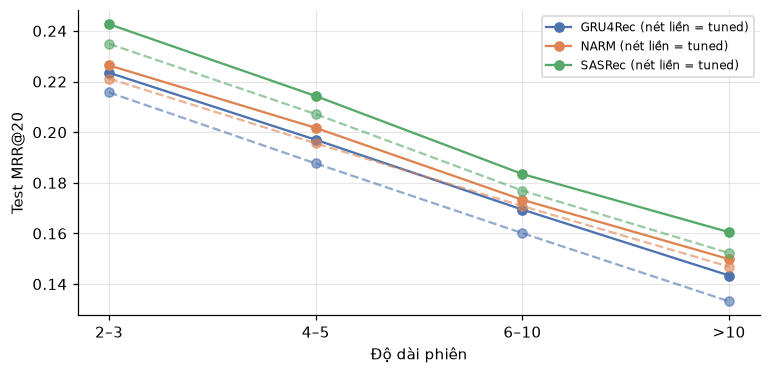

In [213]:
# ===== 12.11. MRR@20 default vs tuned theo bucket độ dài phiên 2–3 / 4–5 / 6–10 / >10 =====
meta = pd.read_csv(PREPARED_DIR / DATASET / "samples_metadata.csv.gz")
sess_len_map = meta[meta.split == "test"].drop_duplicates("session_id").set_index("session_id").session_len
buckets = pd.Series(default42[MODELS[0]]["test_rows"]["session_id"]).astype(int).map(sess_len_map).map(length_bucket).to_numpy()
blen_rows = []
for m in MODELS:
    for b in LEN_LABELS:
        mask = buckets == b
        blen_rows.append({"Model": m, "Bucket": b, "N": int(mask.sum()), "Default": inst[m]["Default"][mask].mean(),
                          "Tuned": inst[m]["Tuned"][mask].mean()})
blen = pd.DataFrame(blen_rows)
blen["Tăng %"] = (blen.Tuned / blen.Default - 1) * 100
display(blen.pivot(index="Model", columns="Bucket", values="Tăng %")[LEN_LABELS].round(2))
fig, ax = plt.subplots(figsize=(8, 3.6))
for m in MODELS:
    d = blen[blen.Model == m].set_index("Bucket").loc[LEN_LABELS]
    ax.plot(LEN_LABELS, d.Default, ls="--", marker="o", color=MODEL_COLORS[m], alpha=.6)
    ax.plot(LEN_LABELS, d.Tuned, marker="o", color=MODEL_COLORS[m], label=f"{m} (nét liền = tuned)")
ax.set_xlabel("Độ dài phiên")
ax.set_ylabel("Test MRR@20")
ax.legend(fontsize=8)
save_fig(fig, "c05_by_length.png")
plt.show()

### 12.12. Đường học: default vs winner

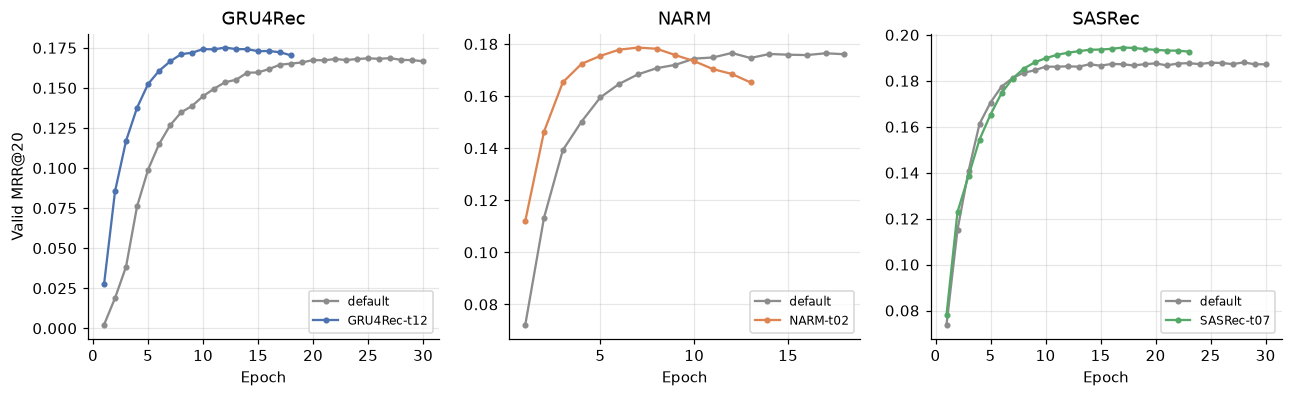

In [214]:
# ===== 12.12. Valid MRR@20 theo epoch =====
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m in zip(axes, MODELS):
    hd, hw = pd.DataFrame(default42[m]["history"]), pd.DataFrame(winners[m]["history"])
    ax.plot(hd.epoch, hd["valid_MRR@20"], marker=".", color="#8C8C8C", label="default")
    ax.plot(hw.epoch, hw["valid_MRR@20"], marker=".", color=MODEL_COLORS[m], label=winners[m]["name"])
    ax.set_title(m)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Valid MRR@20")
save_fig(fig, "c06_learning_curves.png")
plt.show()

### 12.13. (Nếu đã chạy 11.10) Kết quả qua nhiều seed

In [215]:
# ===== 12.13. Trung bình ± độ lệch chuẩn qua các seed; chỉ chạy khi có kết quả lặp seed =====
seed_res = load_jobs([j["name"] for j in seed_jobs]) if seed_jobs else {}
if seed_res:
    rows_s = [{"Model": m, "Variant": v, "Seed": TRAIN_SEED, "MRR@20": src[m]["test"]["All-seen"]["MRR@20"]}
              for v, src in (("Default", default42), ("Tuned", tuned42)) for m in MODELS]
    rows_s += [{"Model": r["model"], "Variant": "Default" if r["name"].startswith("default") else "Tuned",
                "Seed": r["seed"], "MRR@20": r["test"]["All-seen"]["MRR@20"]} for r in seed_res.values()]
    sd = pd.DataFrame(rows_s)
    agg = sd.groupby(["Model", "Variant"])["MRR@20"].agg(["mean", "std", "count"]).unstack()
    display(agg.round(4))
    for m in MODELS:
        d, t = sd.query("Model == @m and Variant == 'Default'")["MRR@20"], sd.query("Model == @m and Variant == 'Tuned'")["MRR@20"]
        print(f"{m}: tăng {t.mean() - d.mean():+.4f} | std seed default {d.std():.4f}, tuned {t.std():.4f} | "
              f"mọi seed tuned > mọi seed default: {t.min() > d.max()}")
else:
    print("Chưa chạy lặp seed (11.10) -> bỏ qua.")

Chưa chạy lặp seed (11.10) -> bỏ qua.


### 12.14. Kiểm tra tiêu chí hoàn thành của đề (Mục 15, trang 56 PDF)

In [216]:
# ===== 12.14. Đối chiếu tiêu chí bằng dữ liệu thật =====
criteria = {
    "Ngân sách bằng nhau: 12 cấu hình khác nhau / mô hình": all(
        len({json.dumps(t["overrides"], sort_keys=True) for t in search_jobs if t["model"] == m}) == TRIALS_PER_MODEL
        for m in MODELS) and trials.groupby("model").size().eq(TRIALS_PER_MODEL).all(),
    "Cùng giao thức (30 epoch, dừng sớm 5, seed 42) cho default và tuned":
        all(r["seed"] == TRAIN_SEED for r in [*search_res.values(), *default42.values()]),
    "Không trial tìm tham số nào chấm test": all(r["test"] is None for r in search_res.values()),
    "Winner chọn đúng theo valid MRR@20": all(
        winners[m]["best_valid_mrr20"] == trials[trials.model == m]["valid MRR@20"].max() for m in MODELS),
    "Default và tuned cùng dữ liệu (fingerprint)": all(
        r["fingerprint"] == FINGERPRINT for r in [*default42.values(), *tuned42.values()]),
    "Có đường cong hiệu năng theo số cấu hình": (FIG_DIR / "c02_budget_curves.png").exists(),
}
display(pd.Series(criteria, name="Đạt").to_frame())

,Đạt
Ngân sách bằng nhau: 12 cấu hình khác nhau / mô hình,True
"Cùng giao thức (30 epoch, dừng sớm 5, seed 42) cho default và tuned",True
Không trial tìm tham số nào chấm test,True
Winner chọn đúng theo valid MRR@20,True
Default và tuned cùng dữ liệu (fingerprint),True
Có đường cong hiệu năng theo số cấu hình,True


### 12.15. Lưu bảng và in câu trả lời 3 câu hỏi (dán vào báo cáo rồi chỉnh câu chữ)

In [217]:
# ===== 12.15. Xuất CSV + kết luận tự động từ số liệu =====
out_dir = ROOT / "output" / RUN_TAG / "tuning"
out_dir.mkdir(parents=True, exist_ok=True)
for name, df in {"all_trials.csv": trials, "test_default_vs_tuned.csv": scores, "gains.csv": gains,
                 "rank_changes.csv": ranks, "saturation.csv": saturation.reset_index(),
                 "unfair_comparison.csv": unfair, "bootstrap_ci.csv": bootstrap, "gain_by_length.csv": blen}.items():
    df.to_csv(out_dir / name, index=False, encoding="utf-8-sig")
print("Đã lưu bảng vào", out_dir.relative_to(ROOT), "\n")

print("CÂU 1 — Mức cải thiện test MRR@20 (All-seen) khi tinh chỉnh 12 cấu hình:")
for m in MODELS:
    gr = gains.query("Model == @m and Group == 'All-seen' and Metric == 'MRR@20'").iloc[0]
    ci = bootstrap[(bootstrap["So sánh"] == f"{m}: tuned − default") & (bootstrap.Group == "All-seen")].iloc[0]
    print(f"  {m}: {gr.Default:.4f} -> {gr.Tuned:.4f} ({gr['Chênh %']:+.1f}%), "
          f"CI95 [{ci['CI95 thấp']:+.4f}, {ci['CI95 cao']:+.4f}] {'có ý nghĩa' if ci['Có ý nghĩa'] else 'KHÔNG có ý nghĩa'}")
changed = int(ranks["Đổi hạng?"].sum())
row = ranks.query("Group == 'All-seen' and Metric == 'MRR@20'").iloc[0]
print(f"\nCÂU 2 — Thứ hạng: {'không đổi' if changed == 0 else f'đổi ở {changed}/{len(ranks)} tổ hợp'}; "
      f"All-seen MRR@20: default {row.Default} | tuned {row.Tuned}")
print(f"  So sánh không công bằng (A tuned vs B default) đảo kết luận ở {int(unfair['Đảo kết luận?'].sum())}/6 cặp, "
      f"phóng đại chênh lệch trung bình {unfair['Phóng đại (%)'].abs().mean():.0f}%.")
print("\nCÂU 3 — Bão hòa:")
for m in MODELS:
    s = saturation.loc[m]
    beat = f"từ cấu hình thứ {int(s['k đầu tiên vượt default'])}" if pd.notna(s["k đầu tiên vượt default"]) else "không vượt"
    print(f"  {m}: đạt 99% best sau {int(s['k đạt 99% best cuối'])} cấu hình; tăng thêm 6→12 = {s['Tăng 6→12']:+.4f}; "
          f"vượt default {beat}")
print(f"\nHạn chế: {len(capped)}/{len(trials)} cấu hình đạt best ở epoch {MAX_EPOCHS}; ngân sách tính bằng số cấu hình "
      f"(thời gian GPU khác nhau, xem 12.7); 1 seed (trừ khi chạy 11.10); 1 bộ dữ liệu.")

Đã lưu bảng vào output\t10_v2\tuning 

CÂU 1 — Mức cải thiện test MRR@20 (All-seen) khi tinh chỉnh 12 cấu hình:
  GRU4Rec: 0.1660 -> 0.1753 (+5.6%), CI95 [+0.0077, +0.0111] có ý nghĩa
  NARM: 0.1762 -> 0.1799 (+2.1%), CI95 [+0.0022, +0.0053] có ý nghĩa
  SASRec: 0.1843 -> 0.1916 (+4.0%), CI95 [+0.0065, +0.0082] có ý nghĩa

CÂU 2 — Thứ hạng: đổi ở 4/12 tổ hợp; All-seen MRR@20: default SASRec > NARM > GRU4Rec | tuned SASRec > NARM > GRU4Rec
  So sánh không công bằng (A tuned vs B default) đảo kết luận ở 0/6 cặp, phóng đại chênh lệch trung bình 80%.

CÂU 3 — Bão hòa:
  GRU4Rec: đạt 99% best sau 12 cấu hình; tăng thêm 6→12 = +0.0041; vượt default từ cấu hình thứ 5
  NARM: đạt 99% best sau 2 cấu hình; tăng thêm 6→12 = +0.0000; vượt default từ cấu hình thứ 2
  SASRec: đạt 99% best sau 7 cấu hình; tăng thêm 6→12 = +0.0057; vượt default từ cấu hình thứ 1

Hạn chế: 7/36 cấu hình đạt best ở epoch 30; ngân sách tính bằng số cấu hình (thời gian GPU khác nhau, xem 12.7); 1 seed (trừ khi chạy 11.10)